# Surveillance vibratoire des roulements — étude comparative des autoencodeurs et du clustering
### Rapport expérimental consolidé V6 · version révisée pour partage avec les collaborateurs

**Objet.** Détecter les anomalies d'un roulement (*SAFE* versus défaut), puis regrouper cinq états (*SAFE*, *BALL*, *INNER_RACE*, *OUTER_RACE*, *COMBINED*) à partir des vibrations. Comparer quatre familles d'autoencodeurs, trois algorithmes de clustering et des références classiques sans réseau neuronal.

**Jeu exploité :** **8 431 acquisitions**, 26 descripteurs, 512 coefficients spectraux, trois régimes de vitesse (10, 15, 20) ; **5 902 TRAIN / 1 264 VALIDATION / 1 265 TEST**.

**Statut scientifique à la remise :** **A, B et C calculées et leurs sorties enregistrées ; D (DEC/IDEC) non exécutée et optionnelle.** Ce fichier contient les codes d'apprentissage et les résultats déjà obtenus. La présente révision est **éditoriale et graphique : aucun réentraînement n'a été effectué** pour la réaliser.

> **Lecture prioritaire.** Sur le TEST actuel, plusieurs méthodes atteignent ARI ou AUROC = 1,0000. Cela ne prouve ni la supériorité intrinsèque d'un autoencodeur ni la généralisation à une nouvelle machine : les acquisitions ne disposent pas d'un identifiant de groupe physique indépendant et la correction de vitesse utilise des régimes déjà connus.

**Parcours :** A — autoencodeurs et diagnostic ; B — K-means, GMM, BIRCH ; C — audit scientifique, références classiques, vitesse inconnue, robustesse ; D — approfondissement optionnel ; **Synthèse générale et décision provisoire**.

*Traçabilité : valeurs numériques et figures reprises des sorties du notebook V6 exécuté fourni pour cette révision. Les commentaires rapportent uniquement les résultats effectivement observés. Les figures complémentaires ont été recomposées à partir des tableaux de sortie, sans nouvel apprentissage.*

## Guide de lecture — protocole et statut des expériences

| Partie | Objet | Provenance de la sortie enregistrée | Statut |
|---|---|---|---|
| **A** | Quatre AE ; détection SAFE/défaut ; stratégies de vitesse ; K-means | Résultats recalculés dans le pipeline autonome, puis rechargés | **Exécutée** : 24 entraînements AE et figures sauvegardées |
| **B** | K-means, GMM, BIRCH sur les espaces latents A | 20 configurations × 3 algorithmes | **Exécutée** : 60 évaluations |
| **C** | Audit des données, PCA, détecteurs classiques, vitesse exclue et robustesse latente | Données et sorties A/B, `bd_v1.pkl` | **Exécutée** : tableaux et figures sauvegardés |
| **D** | DEC / IDEC pour clustering profond | Protocole préparé, entraînement volontairement désactivé | **Non exécutée** — aucun score ne peut en être inféré |

**Évaluation :** les normalisations, PCA et modèles sont ajustés sur le TRAIN applicable à chaque expérience. Les étiquettes du TEST sont utilisées pour les métriques (ARI/NMI, AUROC, etc.), pas pour entraîner les clusterings. *K = 5* est fixé à partir de la connaissance des cinq états. Les performances de test ayant été examinées dans les travaux successifs, un test externe indépendant reste indispensable pour confirmer le choix final.

**Autonomie du livrable :** aucun notebook V4/V5 ni répertoire `results_v5_*` n'est requis par cette V6. Le fichier de données `bd_v1.pkl`, un environnement Python compatible et, lors d'une réexécution, un répertoire de résultats V6 sont nécessaires.

---
# Étude A — Quatre familles d'autoencodeurs : diagnostic, vitesse et clustering

Cette partie présente les sorties issues des entraînements réalisés dans **ce notebook autonome**. Les représentations latentes, métriques et figures sont conservées dans les sorties des cellules. L'étude A compare MLP-AE, Denoising-AE, VAE et CNN-AE spectral, avec trois traitements de la vitesse.

## Exécution et reproductibilité — notebook autonome

Le code scientifique nécessaire aux études A/B est incorporé dans les cellules suivantes ; **aucune ancienne version du notebook n'est nécessaire**. Le pipeline utilise `bd_v1.pkl`, puis crée et réutilise ses résultats dans `results_v6_autonome/`.

- **Lecture du présent livrable :** ouvrir le notebook ; les résultats A/B/C et figures sont déjà enregistrés. Il n'est pas nécessaire de lancer `Run All` pour lire ou commenter ce travail.
- **Reproduction intégrale :** installer l'environnement Python, placer `bd_v1.pkl` dans le répertoire de travail, puis lancer `Run All`. **La première fois, A réentraîne les autoencodeurs et B recalcule les clusterings** ; les sorties vérifiées sont ensuite réutilisées. Cette procédure peut prendre du temps sur CPU.
- **Partie D :** `EXECUTER_DEC_IDEC=False` ; l'activer entraîne de nouveaux modèles et constitue une nouvelle expérience, non couverte par les conclusions de ce rapport.

La sortie exécutée contient les historiques et figures des expériences ; la génération de la présente version de diffusion **n'a pas recalculé les modèles**. Une sauvegarde des résultats et une documentation du jeu de données restent nécessaires à la reproductibilité sur d'autres postes.

In [1]:
# Initialisation du paquet de code incorporé au notebook.
import sys, types
_paquet = types.ModuleType('scripts')
_paquet.__path__ = []
sys.modules['scripts'] = _paquet
print('Code scientifique autonome : chargement des modules internes')


Code scientifique autonome : chargement des modules internes


In [2]:
# Code embarqué pour scripts.benchmark_v5 — modifiable dans ce notebook.
import sys as _sys, types as _types
_nom = 'scripts.benchmark_v5'
_module = _types.ModuleType(_nom)
_module.__package__ = 'scripts'
_module.__file__ = '<notebook_autonome>/' + _nom.replace('.', '/') + '.py'
_source = "\"\"\"V5: benchmark reproducible d'autoencodeurs pour roulements (cache V4).\n\nNe chargez bd_v1.pkl que depuis une source de confiance (pickle execute du code).\nLes scores sont exploratoires tant qu'un split par acquisitions independantes\n(group_id) n'a pas ete valide et utilise.\n\"\"\"\nfrom __future__ import annotations\n\nimport argparse\nimport copy\nimport json\nimport random\nimport warnings\nfrom pathlib import Path\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom sklearn.cluster import KMeans\nfrom sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, roc_auc_score, confusion_matrix\nfrom sklearn.neural_network import MLPRegressor\nfrom sklearn.preprocessing import StandardScaler\nfrom torch import nn\nfrom torch.utils.data import DataLoader, TensorDataset\n\nCLASSES = (\"SAFE\", \"BALL\", \"INNER_RACE\", \"OUTER_RACE\", \"COMBINED\")\nMETA_COLS = {\"classe\", \"vitesse\", \"fichier\", \"chemin\", \"split\", \"entete\", \"group_id\"}\n\n\ndef seed_all(seed: int):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n\n\ndef load_data(path: Path):\n    if not path.is_file():\n        raise FileNotFoundError(f\"Cache absent : {path}. Executer d'abord les sections 0-3 de la V4 avec les Excel locaux.\")\n    bd, spectra = pd.read_pickle(path)\n    if not isinstance(bd, pd.DataFrame) or not isinstance(spectra, np.ndarray):\n        raise ValueError(\"Le cache doit contenir (DataFrame, ndarray).\")\n    if len(bd) != len(spectra) or len(bd) == 0 or spectra.ndim != 2 or spectra.shape[1] != 512:\n        raise ValueError(\"Dimensions incompatibles : spectres attendus (N, 512), aligns sur bd.\")\n    req = {\"classe\", \"vitesse\", \"split\", \"fichier\", \"chemin\"}\n    if not req.issubset(bd.columns):\n        raise ValueError(f\"Colonnes manquantes : {sorted(req - set(bd.columns))}\")\n    if set(bd.classe.unique()) != set(CLASSES):\n        raise ValueError(f\"Classes inattendues : {sorted(bd.classe.unique())}\")\n    if not {\"train\", \"val\", \"test\"}.issubset(set(bd.split)):\n        raise ValueError(\"Splits train/val/test manquants\")\n    if bd.chemin.duplicated().any():\n        raise ValueError(\"Une meme acquisition figure plusieurs fois dans bd\")\n    features = [c for c in bd.columns if c not in META_COLS]\n    if len(features) != 26:\n        raise ValueError(f\"26 descripteurs attendus, {len(features)} recus\")\n    if not np.isfinite(bd[features].to_numpy(dtype=float)).all() or not np.isfinite(spectra).all():\n        raise ValueError(\"NaN/Inf dans les entrees. Verifier les fichiers et les log10.\")\n    bd = bd.reset_index(drop=True).copy()\n    if \"group_id\" in bd:\n        sets = [set(bd.loc[bd.split == s, \"group_id\"]) for s in (\"train\", \"val\", \"test\")]\n        if any(sets[i] & sets[j] for i, j in ((0, 1), (0, 2), (1, 2))):\n            raise ValueError(\"Fuite de donnees: group_id commun a plusieurs splits\")\n    else:\n        warnings.warn(\"Aucun group_id independant : les scores ne prouvent pas la generalisation a de nouvelles series.\")\n    return bd, spectra.astype(np.float32), features\n\n\ndef normalize(bd, values, train_mask, feature_names=None, log_features=False):\n    values = np.asarray(values, dtype=np.float64).copy()\n    if log_features:\n        indices = [i for i, col in enumerate(feature_names) if col.split(\"_\")[0] in (\"rms\", \"pkpk\", \"kurtosis\", \"crete\")]\n        if (values[:, indices] <= 0).any():\n            raise ValueError(\"log10 impossible : descripteur non strictement positif\")\n        values[:, indices] = np.log10(values[:, indices])\n    scaled = np.zeros_like(values, dtype=np.float32)\n    for speed in sorted(bd.vitesse.unique()):\n        current = (bd.vitesse == speed).to_numpy()\n        fit_mask = current & train_mask\n        if fit_mask.sum() < 3:\n            raise ValueError(f\"Pas assez de donnees d'apprentissage pour la vitesse {speed}\")\n        scaler = StandardScaler().fit(values[fit_mask])\n        scaled[current] = scaler.transform(values[current]).astype(np.float32)\n    return scaled\n\n\nclass DenseAE(nn.Module):\n    def __init__(self, size, latent=8):\n        super().__init__()\n        self.enc = nn.Sequential(nn.Linear(size, 64), nn.ReLU(), nn.Linear(64, latent))\n        self.dec = nn.Sequential(nn.Linear(latent, 64), nn.ReLU(), nn.Linear(64, size))\n\n    def encode(self, x):\n        return self.enc(x)\n\n    def forward(self, x):\n        return self.dec(self.encode(x)), torch.zeros((), device=x.device)\n\n\nclass VAE(nn.Module):\n    def __init__(self, size, latent=8):\n        super().__init__()\n        self.hidden = nn.Sequential(nn.Linear(size, 64), nn.ReLU())\n        self.mu = nn.Linear(64, latent)\n        self.logvar = nn.Linear(64, latent)\n        self.dec = nn.Sequential(nn.Linear(latent, 64), nn.ReLU(), nn.Linear(64, size))\n\n    def encode(self, x):\n        return self.mu(self.hidden(x))\n\n    def forward(self, x):\n        h = self.hidden(x)\n        mu, logvar = self.mu(h), self.logvar(h).clamp(-10, 10)\n        z = mu + torch.randn_like(mu) * torch.exp(logvar * 0.5) if self.training else mu\n        kl = (-0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(dim=1)).mean()\n        return self.dec(z), kl\n\n\nclass SpectralCNN(nn.Module):\n    def __init__(self, latent=16):\n        super().__init__()\n        self.enc = nn.Sequential(nn.Conv1d(2, 16, 5, 2, 2), nn.ReLU(),\n                                 nn.Conv1d(16, 32, 5, 2, 2), nn.ReLU())\n        self.proj = nn.Linear(32 * 64, latent)\n        self.unproj = nn.Linear(latent, 32 * 64)\n        self.dec = nn.Sequential(nn.ConvTranspose1d(32, 16, 4, 2, 1), nn.ReLU(),\n                                 nn.ConvTranspose1d(16, 2, 4, 2, 1))\n\n    def encode(self, x):\n        return self.proj(self.enc(x).flatten(1))\n\n    def forward(self, x):\n        z = self.encode(x)\n        return self.dec(self.unproj(z).reshape(-1, 32, 64)), torch.zeros((), device=x.device)\n\n\nclass TemporalLSTM(nn.Module):\n    def __init__(self, latent=8):\n        super().__init__()\n        self.rnn_enc = nn.LSTM(2, 24, batch_first=True)\n        self.proj = nn.Linear(24, latent)\n        self.rnn_dec = nn.LSTM(latent, 24, batch_first=True)\n        self.out = nn.Linear(24, 2)\n\n    def encode(self, x):\n        _, (h, _) = self.rnn_enc(x)\n        return self.proj(h[-1])\n\n    def forward(self, x):\n        z = self.encode(x)\n        out, _ = self.rnn_dec(z[:, None, :].expand(-1, x.shape[1], -1))\n        return self.out(out), torch.zeros((), device=x.device)\n\n\ndef fit_torch(model, values, tr, val, device, epochs, batch_size, seed, noise=0.0, beta=0.02):\n    if epochs < 1 or batch_size < 1:\n        raise ValueError(\"epochs et batch_size doivent etre positifs\")\n    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)\n    x_tr = torch.tensor(values[tr], dtype=torch.float32)\n    x_val = torch.tensor(values[val], dtype=torch.float32)\n    if not len(x_tr) or not len(x_val):\n        raise ValueError(\"train/validation vide\")\n    loader = DataLoader(TensorDataset(x_tr), batch_size=batch_size, shuffle=True,\n                        generator=torch.Generator().manual_seed(seed))\n    model.to(device)\n    best, best_state, patience = float(\"inf\"), None, 0\n    for _ in range(epochs):\n        model.train()\n        for (clean,) in loader:\n            clean = clean.to(device)\n            corrupted = clean + noise * torch.randn_like(clean) if noise else clean\n            rec, kl = model(corrupted)\n            loss = (rec - clean).square().mean() + beta * kl\n            optimizer.zero_grad()\n            loss.backward()\n            optimizer.step()\n        model.eval()\n        with torch.no_grad():\n            val_losses = []\n            for chunk in x_val.split(batch_size):\n                chunk = chunk.to(device)\n                rec, kl = model(chunk)\n                val_losses.append(((rec - chunk).square().mean() + beta * kl).item())\n            score = float(np.mean(val_losses))\n        if score < best - 1e-5:\n            best, best_state, patience = score, copy.deepcopy(model.state_dict()), 0\n        else:\n            patience += 1\n        if patience >= 5:\n            break\n    model.load_state_dict(best_state)\n    return model\n\n\ndef infer_torch(model, values, device, batch_size):\n    model.eval()\n    reconstruction, latent = [], []\n    with torch.no_grad():\n        for chunk in np.array_split(values, max(1, (len(values) + batch_size - 1) // batch_size)):\n            x = torch.tensor(chunk, dtype=torch.float32, device=device)\n            rec, _ = model(x)\n            reconstruction.append((x - rec).square().flatten(1).mean(1).cpu().numpy())\n            latent.append(model.encode(x).cpu().numpy())\n    return np.concatenate(reconstruction), np.concatenate(latent)\n\n\ndef load_temporal_envelopes(bd, cache_path: Path):\n    \"\"\"RMS dans 128 fenetres de 200 echantillons, par canal, sur 1 seconde.\"\"\"\n    if cache_path.is_file():\n        with np.load(cache_path) as data:\n            if not np.array_equal(data[\"paths\"], bd.chemin.to_numpy(dtype=str)):\n                raise ValueError(\"Cache temporel obsolete: chemins differents\")\n            return data[\"x\"].astype(np.float32)\n    import zipfile\n    import unicodedata\n    from xml.etree.ElementTree import iterparse\n    ns = \"{http://schemas.openxmlformats.org/spreadsheetml/2006/main}\"\n    names = (\"acceleration_vertbleu\", \"acceleration_vert\")\n    env = []\n    for path in bd.chemin:\n        if not Path(path).exists():\n            raise FileNotFoundError(f\"Fichier source introuvable : {path}\")\n        with zipfile.ZipFile(path) as archive:\n            texts = []\n            if \"xl/sharedStrings.xml\" in archive.namelist():\n                for _, elem in iterparse(archive.open(\"xl/sharedStrings.xml\")):\n                    if elem.tag == ns + \"si\":\n                        texts.append(\"\".join(t.text or \"\" for t in elem.iter(ns + \"t\")))\n            rows = []\n            for _, elem in iterparse(archive.open(\"xl/worksheets/sheet1.xml\")):\n                if elem.tag == ns + \"row\":\n                    vals = []\n                    for col in elem.findall(ns + \"c\"):\n                        value = col.find(ns + \"v\")\n                        if col.get(\"t\") == \"s\":\n                            vals.append(texts[int(value.text)])\n                        elif col.get(\"t\") == \"inlineStr\":\n                            vals.append(\"\".join(t.text or \"\" for t in col.iter(ns + \"t\")))\n                        else:\n                            vals.append(float(value.text) if value is not None else np.nan)\n                    rows.append(vals)\n                    elem.clear()\n        columns = [\"\".join(c for c in unicodedata.normalize(\"NFKD\", str(x).strip().lower()) if not unicodedata.combining(c)) for x in rows[0]]\n        if not set(names).issubset(columns):\n            raise ValueError(f\"Capteurs absents dans {path}\")\n        signal = np.asarray([[row[columns.index(n)] for n in names] for row in rows[1:]], dtype=np.float32)\n        if signal.shape != (25600, 2) or not np.isfinite(signal).all():\n            raise ValueError(f\"Signal invalide {path}: {signal.shape}\")\n        env.append(np.sqrt((signal.reshape(128, 200, 2) ** 2).mean(axis=1)))\n    x = np.stack(env).astype(np.float32)\n    cache_path.parent.mkdir(parents=True, exist_ok=True)\n    np.savez_compressed(cache_path, x=x, paths=bd.chemin.to_numpy(dtype=str))\n    return x\n\n\ndef benchmark(bd, spectra, features, outdir, *, epochs, batch_size, seed, include_lstm=False, temporal_cache=None):\n    seed_all(seed)\n    device = \"cuda\" if torch.cuda.is_available() else \"cpu\"\n    is_train = (bd.split == \"train\").to_numpy()\n    is_val = (bd.split == \"val\").to_numpy()\n    is_test = (bd.split == \"test\").to_numpy()\n    is_safe = (bd.classe == \"SAFE\").to_numpy()\n    y = (~is_safe).astype(int)\n    Xf = bd[features].to_numpy(dtype=np.float32)\n    data = {\n        \"MLP-AE\": (normalize(bd, Xf, is_train, features, log_features=True), None),\n        \"Denoising-AE\": (normalize(bd, Xf, is_train, features, log_features=True), DenseAE(26)),\n        \"VAE\": (normalize(bd, Xf, is_train, features, log_features=True), VAE(26)),\n        \"CNN-AE spectral\": (normalize(bd, spectra, is_train).reshape(-1, 2, 256), SpectralCNN()),\n    }\n    if include_lstm:\n        env = load_temporal_envelopes(bd, temporal_cache or outdir / \"enveloppes_128.npz\")\n        data[\"LSTM-AE temporel\"] = (normalize(bd, env.reshape(len(env), -1), is_train).reshape(-1, 128, 2), TemporalLSTM())\n    detection, clustering = [], []\n    for name, (Xcl, model) in data.items():\n        typ = \"cnn\" if name.startswith(\"CNN\") else \"lstm\" if name.startswith(\"LSTM\") else \"dense\"\n        base = spectra if typ == \"cnn\" else env.reshape(len(env), -1) if typ == \"lstm\" else Xf\n        Xdet = normalize(bd, base, is_train & is_safe, features if typ == \"dense\" else None, log_features=typ == \"dense\")\n        if typ == \"cnn\":\n            Xdet = Xdet.reshape(-1, 2, 256)\n        if typ == \"lstm\":\n            Xdet = Xdet.reshape(-1, 128, 2)\n        if name == \"MLP-AE\":\n            mdl_cl = MLPRegressor(hidden_layer_sizes=(16, 6, 16), max_iter=250,\n                                  early_stopping=True, random_state=seed).fit(Xcl[is_train], Xcl[is_train])\n            mdl_det = MLPRegressor(hidden_layer_sizes=(16, 6, 16), max_iter=250,\n                                   early_stopping=True, random_state=seed).fit(Xdet[is_train & is_safe], Xdet[is_train & is_safe])\n            z = Xcl.copy()\n            for w, bias in zip(mdl_cl.coefs_[:2], mdl_cl.intercepts_[:2]):\n                z = np.tanh(z @ w + bias)\n            anomaly = ((Xdet - mdl_det.predict(Xdet)) ** 2).mean(axis=1)\n            joblib.dump({\"clustering\": mdl_cl, \"detection\": mdl_det}, outdir / \"mlp_v5.joblib\")\n        else:\n            def build():\n                if name == \"Denoising-AE\":\n                    return DenseAE(26)\n                if name == \"VAE\":\n                    return VAE(26)\n                if typ == \"cnn\":\n                    return SpectralCNN()\n                return TemporalLSTM()\n            noise = 0.15 if name == \"Denoising-AE\" else 0.0\n            mdl_cl = fit_torch(build(), Xcl, is_train, is_val, device, epochs, batch_size, seed, noise=noise)\n            _, z = infer_torch(mdl_cl, Xcl, device, batch_size)\n            mdl_det = fit_torch(build(), Xdet, is_train & is_safe, is_val & is_safe, device, epochs, batch_size, seed, noise=noise)\n            anomaly, _ = infer_torch(mdl_det, Xdet, device, batch_size)\n            torch.save({\"clustering\": mdl_cl.cpu().state_dict(), \"detection\": mdl_det.cpu().state_dict()},\n                       outdir / (name.lower().replace(\" \", \"_\").replace(\"-\", \"_\") + \".pt\"))\n        threshold = float(np.percentile(anomaly[is_val & is_safe], 99))\n        pred = anomaly[is_test] > threshold\n        tn, fp, fn, tp = confusion_matrix(y[is_test], pred, labels=[0, 1]).ravel()\n        detection.append({\"model\": name, \"auroc\": roc_auc_score(y[is_test], anomaly[is_test]),\n                          \"recall\": tp / max(1, tp + fn), \"false_alarm_rate\": fp / max(1, fp + tn),\n                          \"precision\": tp / max(1, tp + fp), \"threshold_val_safe_p99\": threshold,\n                          \"n_test\": int(is_test.sum())})\n        km = KMeans(n_clusters=5, n_init=10, random_state=seed).fit(z[is_train])\n        pred_clusters = km.predict(z[is_test])\n        clustering.append({\"model\": name, \"ari\": adjusted_rand_score(bd.classe[is_test], pred_clusters),\n                           \"nmi\": normalized_mutual_info_score(bd.classe[is_test], pred_clusters),\n                           \"n_test\": int(is_test.sum())})\n        print(f\"{name}: AUROC={detection[-1]['auroc']:.3f} ARI={clustering[-1]['ari']:.3f}\")\n    pd.DataFrame(detection).to_csv(outdir / \"detection_v5.csv\", index=False)\n    pd.DataFrame(clustering).to_csv(outdir / \"clustering_v5.csv\", index=False)\n    (outdir / \"protocole_v5.json\").write_text(json.dumps({\"seed\": seed, \"device\": device, \"epochs\": epochs,\n        \"split\": \"V4 train/val/test (provisoire si group_id absent)\", \"n\": len(bd),\n        \"classes\": list(CLASSES), \"lstm_enabled\": include_lstm}, indent=2), encoding=\"utf-8\")\n    return detection, clustering\n\n\ndef self_test():\n    seed_all(42)\n    with torch.no_grad():\n        for cls, shape in [(DenseAE, (3, 26)), (VAE, (3, 26)), (SpectralCNN, (3, 2, 256)),\n                           (TemporalLSTM, (3, 128, 2))]:\n            m = cls(26) if cls in (DenseAE, VAE) else cls()\n            x = torch.randn(*shape)\n            rec, kl = m(x)\n            assert rec.shape == x.shape and torch.isfinite(rec).all() and torch.isfinite(kl)\n            assert m.encode(x).shape[0] == 3\n    n = 30\n    df = pd.DataFrame({\"vitesse\": np.repeat([10, 15, 20], n // 3)})\n    data = np.random.default_rng(42).normal(size=(n, 26))\n    y = normalize(df, data, np.ones(n, dtype=bool))\n    assert y.shape == (n, 26) and np.isfinite(y).all()\n    print(\"Autotest architectures + preprocessing : OK\")\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\"--cache\", type=Path, default=Path(\"bd_v1.pkl\"))\n    parser.add_argument(\"--outdir\", type=Path, default=Path(\"results_v5\"))\n    parser.add_argument(\"--epochs\", type=int, default=25)\n    parser.add_argument(\"--batch-size\", type=int, default=128)\n    parser.add_argument(\"--seed\", type=int, default=42)\n    parser.add_argument(\"--lstm\", action=\"store_true\", help=\"Active LSTM sur enveloppes temporelles, necessite les Excel sources\")\n    parser.add_argument(\"--temporal-cache\", type=Path)\n    parser.add_argument(\"--self-test\", action=\"store_true\")\n    parser.add_argument(\"--check-only\", action=\"store_true\", help=\"Valide le cache sans entrainement\")\n    parser.add_argument(\"--allow-provisional-split\", action=\"store_true\", help=\"Accepte explicitement le protocole V4 provisoire\")\n    args = parser.parse_args()\n    if args.self_test:\n        return self_test()\n    bd, spectra, features = load_data(args.cache)\n    print(f\"Cache valide : {len(bd)} acquisitions, {len(features)} descripteurs, {spectra.shape[1]} bins spectraux\")\n    print(pd.crosstab([bd.classe, bd.vitesse], bd.split).to_string())\n    if args.check_only:\n        return\n    if \"group_id\" not in bd and not args.allow_provisional_split:\n        parser.error(\"Split V4 non independant : ajouter --allow-provisional-split pour une evaluation EXPLORATOIRE\")\n    args.outdir.mkdir(parents=True, exist_ok=True)\n    return benchmark(bd, spectra, features, args.outdir, epochs=args.epochs, batch_size=args.batch_size,\n                     seed=args.seed, include_lstm=args.lstm, temporal_cache=args.temporal_cache)\n\n\nif __name__ == \"__main__\":\n    main()"
exec(compile(_source, _module.__file__, 'exec'), _module.__dict__)
_sys.modules[_nom] = _module
setattr(_sys.modules['scripts'], _nom.rsplit('.',1)[-1], _module)
del _source, _module, _nom


In [3]:
# Code embarqué pour scripts.methodologie_comparee_v5 — modifiable dans ce notebook.
import sys as _sys, types as _types
_nom = 'scripts.methodologie_comparee_v5'
_module = _types.ModuleType(_nom)
_module.__package__ = 'scripts'
_module.__file__ = '<notebook_autonome>/' + _nom.replace('.', '/') + '.py'
_source = "\"\"\"Protocole comparatif V5 : quatre autoencodeurs, mêmes étapes que la V4.\n\nÉtapes : détection SAFE / défaut ; clustering sans correction ; un modèle par\nvitesse ; modèle commun avec log + standardisation par vitesse (spectres :\nstandardisation par vitesse, pas de log). Chaque étape produit des traces pour\nfigures côte à côte. Aucun Excel requis. Ne touche pas aux résultats V5 existants.\n\nLes métriques ne démontrent PAS la généralisation tant que les groupes\nd'acquisition indépendants ne sont pas identifiés et séparés.\n\"\"\"\nfrom __future__ import annotations\n\nimport argparse\nimport copy\nimport hashlib\nimport json\nimport warnings\nfrom pathlib import Path\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom sklearn.cluster import KMeans\nfrom sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,\n                             confusion_matrix, roc_auc_score, silhouette_score)\nfrom sklearn.neural_network import MLPRegressor\nfrom sklearn.preprocessing import StandardScaler\nfrom torch.utils.data import DataLoader, TensorDataset\n\nfrom scripts.benchmark_v5 import (CLASSES, DenseAE, VAE, SpectralCNN, load_data,\n                                  seed_all, infer_torch)\n\nNOMS = (\"MLP-AE\", \"Denoising-AE\", \"VAE\", \"CNN-AE spectral\")\nSLUG = {\"MLP-AE\": \"mlp\", \"Denoising-AE\": \"denoising\", \"VAE\": \"vae\",\n        \"CNN-AE spectral\": \"cnn_spectral\"}\nSTAGES = (\"sans_correction\", \"par_vitesse\", \"correction_vitesse\")\nCOL_LOG = (\"rms\", \"pkpk\", \"kurtosis\", \"crete\")\n\n\ndef preparer(df, valeurs, features, stage, train_mask):\n    \"\"\"Prétraitement sans fuite ; le masque de fit ne contient jamais val/test.\"\"\"\n    x = np.asarray(valeurs, dtype=np.float64).copy()\n    if stage == \"correction_vitesse\" and features is not None:\n        indices = [i for i, c in enumerate(features) if c.split(\"_\")[0] in COL_LOG]\n        if indices:\n            if (x[:, indices] <= 0).any():\n                raise ValueError(\"Log10 impossible : valeurs <= 0.\")\n            x[:, indices] = np.log10(x[:, indices])\n    out = np.empty(x.shape, dtype=np.float32)\n    scalers = {}\n    per_speed = stage == \"correction_vitesse\"\n    if per_speed:\n        for v in sorted(df.vitesse.unique()):\n            mask = df.vitesse.to_numpy() == v\n            fit = mask & train_mask\n            if fit.sum() < 3:\n                raise ValueError(f\"Échantillons train insuffisants à vitesse {v}.\")\n            scaler = StandardScaler().fit(x[fit])\n            out[mask] = scaler.transform(x[mask]).astype(np.float32)\n            scalers[str(v)] = scaler\n    else:\n        if train_mask.sum() < 3:\n            raise ValueError(\"Train insuffisant.\")\n        scaler = StandardScaler().fit(x[train_mask])\n        out[:] = scaler.transform(x).astype(np.float32)\n        scalers[\"toutes\"] = scaler\n    return out, scalers\n\n\ndef construire(nom, latent=6):\n    if nom == \"Denoising-AE\":\n        return DenseAE(26, latent=latent)\n    if nom == \"VAE\":\n        return VAE(26, latent=latent)\n    if nom == \"CNN-AE spectral\":\n        return SpectralCNN(latent=latent)\n    raise ValueError(nom)\n\n\ndef apprendre_torch(nom, x, tr, val, epochs, batch_size, device, seed):\n    \"\"\"Apprentissage AE avec journalisation train/val et early-stopping.\"\"\"\n    seed_all(seed)\n    model = construire(nom).to(device)\n    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)\n    train = torch.as_tensor(x[tr], dtype=torch.float32)\n    validation = torch.as_tensor(x[val], dtype=torch.float32)\n    if len(train) < 3 or len(validation) < 1:\n        raise ValueError(f\"Jeux train/validation insuffisants pour {nom}.\")\n    loader = DataLoader(TensorDataset(train), batch_size=batch_size, shuffle=True,\n                        generator=torch.Generator().manual_seed(seed))\n    bruit = 0.15 if nom == \"Denoising-AE\" else 0.0\n    best_loss, best_state, patience, historique = float(\"inf\"), None, 0, []\n    for epoch in range(1, epochs + 1):\n        model.train()\n        pertes, tailles = [], []\n        for (clean,) in loader:\n            clean = clean.to(device)\n            inp = clean + bruit * torch.randn_like(clean) if bruit else clean\n            recon, kl = model(inp)\n            perte = (recon - clean).square().mean() + 0.02 * kl\n            optimizer.zero_grad()\n            perte.backward()\n            optimizer.step()\n            pertes.append(float(perte.item()))\n            tailles.append(len(clean))\n        model.eval()\n        with torch.no_grad():\n            vloss, vsize = [], []\n            for batch in validation.split(batch_size):\n                batch = batch.to(device)\n                recon, kl = model(batch)\n                vloss.append(float(((recon-batch).square().mean() + 0.02*kl).item()))\n                vsize.append(len(batch))\n        train_loss = float(np.average(pertes, weights=tailles))\n        val_loss = float(np.average(vloss, weights=vsize))\n        historique.append((epoch, train_loss, val_loss, np.nan))\n        if val_loss < best_loss - 1e-5:\n            best_loss, best_state, patience = val_loss, copy.deepcopy(model.state_dict()), 0\n        else:\n            patience += 1\n        if patience >= 5:\n            break\n    if best_state is None:\n        raise RuntimeError(\"Aucun état validé.\")\n    model.load_state_dict(best_state)\n    return model, historique\n\n\ndef apprendre(nom, x, tr, val, args, seed):\n    \"\"\"Renvoie modèle, espace latent, scores de reconstruction, historique.\"\"\"\n    if nom == \"MLP-AE\":\n        modele = MLPRegressor(hidden_layer_sizes=(16, 6, 16),\n                              activation=\"tanh\", learning_rate_init=1e-3,\n                              max_iter=args.mlp_max_iter, early_stopping=True,\n                              n_iter_no_change=30, random_state=seed)\n        modele.fit(x[tr], x[tr])\n        z = x.copy()\n        for w, b in zip(modele.coefs_[:2], modele.intercepts_[:2]):\n            z = np.tanh(z @ w + b)\n        erreurs = np.mean((x - modele.predict(x)) ** 2, axis=1)\n        val_r2 = list(getattr(modele, \"validation_scores_\", []))\n        historique = [(i + 1, float(loss), np.nan,\n                       float(val_r2[i]) if i < len(val_r2) else np.nan)\n                      for i, loss in enumerate(modele.loss_curve_)]\n        return modele, z, erreurs, historique\n    modele, historique = apprendre_torch(nom, x, tr, val, args.epochs,\n                                       args.batch_size, args.device, seed)\n    erreurs, z = infer_torch(modele, x, args.device, args.batch_size)\n    return modele, z, erreurs, historique\n\n\ndef forme(nom, x):\n    if nom == \"CNN-AE spectral\":\n        if x.shape[1] != 512:\n            raise ValueError(\"Entrée spectrale 512 attendue.\")\n        return x.reshape(-1, 2, 256)\n    if x.shape[1] != 26:\n        raise ValueError(\"26 descripteurs attendus.\")\n    return x\n\n\ndef enregistrer_modele(model, nom, prefixe, dossier, scalers, kmeans=None):\n    dossier.mkdir(parents=True, exist_ok=True)\n    name = SLUG[nom]\n    extra = {\"scalers\": scalers, \"kmeans\": kmeans, \"model\": nom, \"step\": prefixe}\n    if nom == \"MLP-AE\":\n        joblib.dump({\"autoencodeur\": model, **extra},\n                    dossier / f\"{prefixe}__{name}.joblib\")\n    else:\n        torch.save({\"state_dict\": model.cpu().state_dict(),\n                    \"model\": nom, \"latent_size\": 6},\n                   dossier / f\"{prefixe}__{name}.pt\")\n        joblib.dump(extra, dossier / f\"{prefixe}__{name}_pipeline.joblib\")\n\n\ndef resultat_clustering(c, v, z, x, tr, te, seed, stage, nom, speed, sample_idx, out):\n    \"\"\"Scores d'une stratégie et sauvegarde des prédictions / latents.\"\"\"\n    km = KMeans(n_clusters=5, n_init=10, random_state=seed).fit(z[tr])\n    predictions = km.predict(z[te])\n    # La baseline CNN utilise les 512 bins remis en vecteur 2D pour K-means.\n    x_baseline = x.reshape(len(x), -1)\n    base = KMeans(n_clusters=5, n_init=10, random_state=seed).fit(x_baseline[tr])\n    predictions_base = base.predict(x_baseline[te])\n    classes_test = c[te]\n    vitesses_test = v[te]\n    metrics = []\n    for typ, cluster, espace in ((\"autoencodeur\", predictions, z),\n                                  (\"baseline_kmeans\", predictions_base, x_baseline)):\n        metric = {\"strategie\": stage, \"famille\": nom, \"vitesse_modele\": speed,\n                  \"approche\": typ, \"n_train\": int(tr.sum()), \"n_test\": int(te.sum()),\n                  \"ari\": adjusted_rand_score(classes_test, cluster),\n                  \"nmi\": normalized_mutual_info_score(classes_test, cluster),\n                  \"ari_vs_vitesse\": adjusted_rand_score(vitesses_test, cluster) if speed == \"toutes\" else np.nan}\n        # Silhouette sur un échantillon fixe du train, et non une sélection par labels test.\n        ztrain = espace[tr]\n        labels_train = (km if typ == \"autoencodeur\" else base).labels_\n        if len(np.unique(labels_train)) > 1 and len(ztrain) > 6:\n            n = min(600, len(ztrain))\n            indices = np.random.default_rng(seed).choice(len(ztrain), n, replace=False)\n            ysample = labels_train[indices]\n            metric[\"silhouette_train\"] = (float(silhouette_score(ztrain[indices], ysample))\n                                         if 1 < len(np.unique(ysample)) < n else np.nan)\n        else:\n            metric[\"silhouette_train\"] = np.nan\n        metrics.append(metric)\n    rows = pd.DataFrame({\n        \"sample_id\": sample_idx[te].astype(int),\n        \"strategie\": stage, \"famille\": nom, \"vitesse_modele\": speed,\n        \"classe\": classes_test, \"vitesse\": vitesses_test,\n        \"cluster\": predictions.astype(int), \"cluster_baseline\": predictions_base.astype(int)\n    })\n    out[\"predictions\"].append(rows)\n    out[\"metrics\"].extend(metrics)\n    key = f\"{stage}__{SLUG[nom]}__{speed}\"\n    np.savez_compressed(out[\"latents_dir\"] / f\"{key}.npz\",\n                        z_train=z[tr].astype(np.float32),\n                        z_test=z[te].astype(np.float32),\n                        idx_train=sample_idx[tr].astype(np.int32),\n                        idx_test=sample_idx[te].astype(np.int32))\n    return km\n\n\ndef journaliser(historique, famille, strategie, vitesse, out):\n    out[\"history\"].extend({\n        \"strategie\": strategie, \"famille\": famille, \"vitesse_modele\": vitesse,\n        \"epoch\": ep, \"train_loss\": loss, \"val_loss\": val, \"val_r2\": r2}\n        for ep, loss, val, r2 in historique)\n\n\ndef entrainer_tout(cache, outdir, args):\n    bd, spectra, features = load_data(Path(cache))\n    if \"group_id\" not in bd.columns and not args.allow_provisional_split:\n        raise ValueError(\"Split sans group_id : ajouter --allow-provisional-split pour une étude EXPLORATOIRE.\")\n    if (outdir / \"protocole.json\").exists():\n        raise FileExistsError(f\"{outdir} contient déjà un protocole : choisir un nouveau --outdir.\")\n    args.device = \"cuda\" if torch.cuda.is_available() and not args.cpu else \"cpu\"\n    seed_all(args.seed)\n    print(f\"Source : {len(bd)} acquisitions ; device : {args.device} ; split V4 provisoire.\")\n    xfeatures = bd[features].to_numpy(dtype=np.float32)\n    xraw = {\"MLP-AE\": xfeatures, \"Denoising-AE\": xfeatures,\n            \"VAE\": xfeatures, \"CNN-AE spectral\": spectra}\n    n = len(bd)\n    sample_idx = np.arange(n)\n    split = bd.split.to_numpy()\n    safe = bd.classe.to_numpy() == \"SAFE\"\n    y = (~safe).astype(int)\n    outdir.mkdir(parents=True, exist_ok=True)\n    latents_dir = outdir / \"latents\"\n    models_dir = outdir / \"modeles\"\n    latents_dir.mkdir(exist_ok=True)\n    resultats = {\"metrics\": [], \"predictions\": [], \"detection\": [], \"pred_detection\": [],\n                 \"history\": [], \"latents_dir\": latents_dir}\n    # Étape V4 partie 6 : détection saine / défaillante.\n    for nom in NOMS:\n        print(f\"[Détection] {nom}\", flush=True)\n        val = xraw[nom]\n        x, scalers = preparer(bd, val, None, \"sans_correction\", (split == \"train\") & safe)\n        x = forme(nom, x)\n        tr, va, te = (split == \"train\") & safe, (split == \"val\") & safe, split == \"test\"\n        model, _, scores, history = apprendre(nom, x, tr, va, args, args.seed)\n        seuil = float(np.percentile(scores[va], 99))\n        pred = scores[te] > seuil\n        tn, fp, fn, tp = confusion_matrix(y[te], pred, labels=[0, 1]).ravel()\n        resultats[\"detection\"].append({\n            \"famille\": nom, \"auroc\": roc_auc_score(y[te], scores[te]),\n            \"rappel\": tp / max(tp + fn, 1), \"precision\": tp / max(tp + fp, 1),\n            \"taux_fausses_alarmes\": fp / max(fp + tn, 1), \"fp\": int(fp),\n            \"fn\": int(fn), \"tp\": int(tp), \"tn\": int(tn), \"seuil_p99_validation\": seuil,\n            \"n_test\": int(te.sum())})\n        resultats[\"pred_detection\"].append(pd.DataFrame({\n            \"sample_id\": sample_idx[te], \"famille\": nom, \"classe\": bd.classe.to_numpy()[te],\n            \"vitesse\": bd.vitesse.to_numpy()[te], \"y\": y[te],\n            \"score\": scores[te], \"seuil\": seuil, \"alarme\": pred.astype(int)}))\n        journaliser(history, nom, \"detection\", \"toutes\", resultats)\n        enregistrer_modele(model, nom, \"detection\", models_dir, scalers)\n\n    # Étapes V4 parties 7, 8 et 9 : même succession pour chaque famille.\n    for stage in STAGES:\n        vitesses = [str(int(v)) for v in sorted(bd.vitesse.unique())] if stage == \"par_vitesse\" else [\"toutes\"]\n        for speed in vitesses:\n            subset = (bd.vitesse.to_numpy() == int(speed)) if speed != \"toutes\" else np.ones(n, dtype=bool)\n            d = bd.loc[subset].reset_index(drop=True)\n            indices = sample_idx[subset]\n            tr = d.split.to_numpy() == \"train\"\n            va = d.split.to_numpy() == \"val\"\n            te = d.split.to_numpy() == \"test\"\n            for nom in NOMS:\n                print(f\"[{stage} / {speed}] {nom}\", flush=True)\n                local = xraw[nom][subset]\n                features_local = features if nom != \"CNN-AE spectral\" else None\n                prep_stage = \"correction_vitesse\" if stage == \"correction_vitesse\" else \"sans_correction\"\n                x, scalers = preparer(d, local, features_local, prep_stage, tr)\n                x = forme(nom, x)\n                model, z, _, history = apprendre(nom, x, tr, va, args, args.seed)\n                target = {\"predictions\": resultats[\"predictions\"],\n                          \"metrics\": resultats[\"metrics\"], \"latents_dir\": latents_dir}\n                km = resultat_clustering(d.classe.to_numpy(), d.vitesse.to_numpy(), z, x,\n                                         tr, te, args.seed, stage, nom, speed, indices, target)\n                journaliser(history, nom, stage, speed, resultats)\n                enregistrer_modele(model, nom, f\"{stage}__{speed}\", models_dir, scalers, km)\n\n    pd.DataFrame(resultats[\"metrics\"]).to_csv(outdir / \"clustering_strategies.csv\", index=False)\n    pd.concat(resultats[\"predictions\"], ignore_index=True).to_csv(outdir / \"predictions_clustering.csv\", index=False)\n    pd.DataFrame(resultats[\"detection\"]).to_csv(outdir / \"detection.csv\", index=False)\n    pd.concat(resultats[\"pred_detection\"], ignore_index=True).to_csv(outdir / \"predictions_detection.csv\", index=False)\n    pd.DataFrame(resultats[\"history\"]).to_csv(outdir / \"courbes_apprentissage.csv\", index=False)\n    report = {\n        \"description\": \"Protocole V4 élargi aux quatre familles : détection, sans correction, par vitesse, correction.\",\n        \"cache\": str(Path(cache)), \"cache_sha256\": hashlib.sha256(Path(cache).read_bytes()).hexdigest(),\n        \"n\": len(bd), \"modeles\": list(NOMS), \"etapes\": list(STAGES), \"classes\": list(CLASSES),\n        \"vitesses\": sorted(map(int, bd.vitesse.unique())), \"seed\": args.seed,\n        \"epochs_torch_max\": args.epochs, \"mlp_max_iter\": args.mlp_max_iter,\n        \"batch_size\": args.batch_size, \"device\": args.device, \"latent_dim\": 6,\n        \"split\": \"V4 provisoire, non indépendant\" if \"group_id\" not in bd.columns else \"group_id présent, vérifier provenance\",\n        \"limites\": [\"Données spectraux CNN vs 26 features des AE denses.\",\n                    \"CNN: standardisation par vitesse sans log (log V4 réservé aux descripteurs).\",\n                    \"K=5 renseigné par connaissance du nombre de classes.\",\n                    \"La comparaison par vitesse utilise un modèle distinct pour chaque vitesse.\",\n                    \"Le split V4 fichier-par-fichier peut contenir des séries dépendantes.\",\n                    \"Les métriques par vitesse concernent des vitesses vues à l'entraînement.\",\n                    \"Courbes MLP et PyTorch ont des fonctions de perte et arrêts différents.\"]\n    }\n    (outdir / \"protocole.json\").write_text(json.dumps(report, indent=2, ensure_ascii=False),\n                                            encoding=\"utf-8\")\n    print(f\"Comparaison enregistrée dans {outdir.resolve()}\", flush=True)\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\"--cache\", type=Path, default=Path(\"bd_v1.pkl\"))\n    parser.add_argument(\"--outdir\", type=Path, default=Path(\"results_v5_methodologie\"))\n    parser.add_argument(\"--epochs\", type=int, default=25)\n    parser.add_argument(\"--mlp-max-iter\", type=int, default=1000)\n    parser.add_argument(\"--batch-size\", type=int, default=128)\n    parser.add_argument(\"--seed\", type=int, default=42)\n    parser.add_argument(\"--cpu\", action=\"store_true\")\n    parser.add_argument(\"--allow-provisional-split\", action=\"store_true\")\n    parser.add_argument(\"--run\", action=\"store_true\", help=\"Démarrer explicitement tous les entraînements.\")\n    args = parser.parse_args()\n    if min(args.epochs, args.mlp_max_iter, args.batch_size) < 1:\n        parser.error(\"epochs, mlp-max-iter et batch-size doivent être > 0\")\n    if not args.run:\n        print(\"Aucun entraînement : ajouter --run pour réaliser la comparaison méthodologique.\")\n        return\n    entrainer_tout(args.cache, args.outdir, args)\n\n\nif __name__ == \"__main__\":\n    main()\n"
exec(compile(_source, _module.__file__, 'exec'), _module.__dict__)
_sys.modules[_nom] = _module
setattr(_sys.modules['scripts'], _nom.rsplit('.',1)[-1], _module)
del _source, _module, _nom


In [4]:
# Code embarqué pour scripts.comparer_algorithmes_clustering_v5 — modifiable dans ce notebook.
import sys as _sys, types as _types
_nom = 'scripts.comparer_algorithmes_clustering_v5'
_module = _types.ModuleType(_nom)
_module.__package__ = 'scripts'
_module.__file__ = '<notebook_autonome>/' + _nom.replace('.', '/') + '.py'
_source = "\"\"\"Comparer K-means, GMM et BIRCH sur les espaces latents V5 déjà appris.\n\nLes autoencodeurs ne sont JAMAIS réentraînés. Le modèle de référence K-means\nest recalculé depuis les codes train et confronté aux prédictions V5 sauvegardées.\nLa recherche de paramètres utilise EXCLUSIVEMENT le train, jamais les labels test.\n\nUtilisation (depuis la racine du projet):\n  python -m scripts.comparer_algorithmes_clustering_v5 --run\n\"\"\"\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nimport sys\nimport time\nimport warnings\nfrom pathlib import Path\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nimport sklearn\nfrom sklearn.cluster import Birch, KMeans\nfrom sklearn.mixture import GaussianMixture\nfrom sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,\n                             silhouette_score)\nfrom sklearn.neighbors import NearestNeighbors\n\nFAMILLES = (\"MLP-AE\", \"Denoising-AE\", \"VAE\", \"CNN-AE spectral\")\nSLUG = {\"MLP-AE\": \"mlp\", \"Denoising-AE\": \"denoising\", \"VAE\": \"vae\",\n        \"CNN-AE spectral\": \"cnn_spectral\"}\nSTRATEGIES = (\"sans_correction\", \"par_vitesse\", \"correction_vitesse\")\nALGORITHMES = (\"K-means\", \"GMM\", \"BIRCH\")\nVITESSES = (\"10\", \"15\", \"20\")\nCLASSES = (\"SAFE\", \"BALL\", \"INNER_RACE\", \"OUTER_RACE\", \"COMBINED\")\n\n\ndef specs_experiences():\n    for strategie in STRATEGIES:\n        for vitesse in (VITESSES if strategie == \"par_vitesse\" else (\"toutes\",)):\n            for famille in FAMILLES:\n                yield strategie, vitesse, famille\n\n\ndef charger_entrees(dossier: Path):\n    source = Path(dossier)\n    obligatoires = [\"protocole.json\", \"predictions_clustering.csv\",\n                    \"clustering_strategies.csv\"]\n    absents = [f for f in obligatoires if not (source / f).is_file()]\n    if absents:\n        raise FileNotFoundError(f\"Artefacts V5 absents de {source}: {absents}\")\n    protocole = json.loads((source / \"protocole.json\").read_text(encoding=\"utf-8\"))\n    if not set(STRATEGIES).issubset(set(protocole[\"etapes\"])):\n        raise ValueError(\"Protocole V5 incomplet : stratégies manquantes.\")\n    pred = pd.read_csv(source / \"predictions_clustering.csv\",\n                       dtype={\"vitesse_modele\": str})\n    required = {\"sample_id\", \"strategie\", \"famille\", \"vitesse_modele\",\n                \"classe\", \"vitesse\", \"cluster\"}\n    if not required.issubset(pred.columns):\n        raise ValueError(\"Colonnes prédictions V5 manquantes.\")\n    if pred.duplicated([\"strategie\", \"famille\", \"vitesse_modele\", \"sample_id\"]).any():\n        raise ValueError(\"Doublons de prédictions dans les données V5.\")\n    return protocole, pred\n\n\ndef charger_jeu(source: Path, pred: pd.DataFrame,\n                strategie: str, vitesse: str, famille: str):\n    chemin = source / \"latents\" / f\"{strategie}__{SLUG[famille]}__{vitesse}.npz\"\n    if not chemin.is_file():\n        raise FileNotFoundError(f\"Espace latent V5 absent : {chemin}\")\n    with np.load(chemin, allow_pickle=False) as data:\n        champs = (\"z_train\", \"z_test\", \"idx_train\", \"idx_test\")\n        if not set(champs).issubset(data.files):\n            raise ValueError(f\"NPZ incomplet : {chemin}\")\n        ztr, zte = np.asarray(data[\"z_train\"], dtype=np.float32), np.asarray(data[\"z_test\"], dtype=np.float32)\n        itr, ite = np.asarray(data[\"idx_train\"], dtype=np.int64), np.asarray(data[\"idx_test\"], dtype=np.int64)\n    if (ztr.ndim != 2 or zte.ndim != 2 or ztr.shape[1] != zte.shape[1]\n            or ztr.shape[0] != len(itr) or zte.shape[0] != len(ite)\n            or len(ztr) < 10 or len(zte) < 5\n            or not np.isfinite(ztr).all() or not np.isfinite(zte).all()):\n        raise ValueError(f\"Dimensions ou valeurs latentes invalides : {chemin}\")\n    if (len(set(itr)) != len(itr) or len(set(ite)) != len(ite)\n            or not set(itr).isdisjoint(ite)):\n        raise ValueError(\"Identifiants d'acquisitions non indépendants train/test ou dupliqués.\")\n    rows = pred.loc[(pred.strategie == strategie) &\n                    (pred.famille == famille) &\n                    (pred.vitesse_modele == vitesse)].set_index(\"sample_id\")\n    if len(rows) != len(ite) or set(rows.index) != set(ite):\n        raise ValueError(f\"Les prédictions et les codes test ne correspondent pas : {strategie}/{famille}/{vitesse}.\")\n    rows = rows.loc[ite].reset_index().copy()\n    if not set(rows.classe.unique()).issubset(CLASSES):\n        raise ValueError(\"Classes de test inattendues.\")\n    return ztr, zte, itr, ite, rows\n\n\ndef echantillon_train(n: int, seed: int, maximum: int = 450):\n    return np.random.default_rng(seed).choice(n, size=min(maximum, n), replace=False)\n\n\ndef silhouette_sous_echantillon(x: np.ndarray, labels: np.ndarray, subset: np.ndarray):\n    groupes = labels[subset]\n    if not 1 < len(np.unique(groupes)) < len(subset):\n        return np.nan\n    return float(silhouette_score(x[subset], groupes))\n\n\ndef kmeans_reference(ztr, zte, reference, seed, subset):\n    t0 = time.perf_counter()\n    model = KMeans(n_clusters=5, n_init=10, random_state=seed).fit(ztr)\n    pred = model.predict(zte)\n    accord = adjusted_rand_score(np.asarray(reference, dtype=int), pred)\n    if accord < 0.999999:\n        raise ValueError(\"K-means recalculé ne reproduit pas les clusters V5 sauvegardés : \"\n                         f\"ARI={accord:.6f}. Ne pas comparer des résultats incompatibles.\")\n    return model, pred, {\"choix_parametre\": \"K=5, graine du protocole V5\",\n                          \"silhouette_train\": silhouette_sous_echantillon(\n                              ztr, model.labels_, subset),\n                          \"temps_fit_s\": time.perf_counter() - t0,\n                          \"score_selection_train\": np.nan,\n                          \"convergence\": True}, []\n\n\ndef gmm_selection(ztr, zte, seed, subset):\n    \"\"\"Choix BIC sur train; test jamais impliqué dans la sélection.\"\"\"\n    t0 = time.perf_counter()\n    candidats = []\n    log = []\n    for covariance in (\"full\", \"tied\", \"diag\", \"spherical\"):\n        try:\n            with warnings.catch_warnings():\n                warnings.simplefilter(\"ignore\", category=UserWarning)\n                m = GaussianMixture(n_components=5, covariance_type=covariance,\n                                    reg_covar=1e-5, random_state=seed,\n                                    n_init=2, max_iter=250).fit(ztr)\n            bic = float(m.bic(ztr))\n            if not np.isfinite(bic):\n                raise ValueError(\"BIC non fini\")\n            candidats.append((bic, covariance, m))\n            log.append({\"parametre\": covariance, \"critere\": \"BIC train\",\n                        \"valeur\": bic, \"valide\": bool(m.converged_)})\n        except (ValueError, FloatingPointError, np.linalg.LinAlgError) as exc:\n            log.append({\"parametre\": covariance, \"critere\": \"BIC train\",\n                        \"valeur\": np.nan, \"valide\": False, \"raison\": str(exc)[:120]})\n    if not candidats:\n        raise RuntimeError(\"Tous les GMM ont échoué sur l'espace latent train.\")\n    # Préférence pour les modèles convergés; repli explicite sinon.\n    converges = [v for v in candidats if v[2].converged_]\n    bic, covariance, model = min(converges or candidats, key=lambda item: item[0])\n    pred = model.predict(zte)\n    train_labels = model.predict(ztr)\n    meta = {\"choix_parametre\": f\"covariance={covariance}; composants=5\",\n            \"silhouette_train\": silhouette_sous_echantillon(ztr, train_labels, subset),\n            \"temps_fit_s\": time.perf_counter() - t0,\n            \"score_selection_train\": bic,\n            \"convergence\": bool(model.converged_)}\n    return model, pred, meta, log\n\n\ndef birch_selection(ztr, zte, seed, subset):\n    \"\"\"Seuil BIRCH choisi sur silhouette train (sans consultation du test).\"\"\"\n    t0 = time.perf_counter()\n    n_voisins = min(10, len(ztr))\n    distances, _ = NearestNeighbors(n_neighbors=n_voisins).fit(ztr).kneighbors(ztr)\n    voisinage = distances[:, -1]\n    echelle = float(np.median(voisinage[np.isfinite(voisinage)]))\n    if not np.isfinite(echelle) or echelle <= 0:\n        # Échelle de secours à partir de la dispersion globale des latents.\n        echelle = max(float(np.linalg.norm(np.std(ztr, axis=0))), 1e-4)\n    options = sorted(set(max(echelle * k, 1e-5) for k in (0.75, 1.5, 3.0, 6.0)))\n    candidats, log = [], []\n    for threshold in options:\n        try:\n            with warnings.catch_warnings():\n                warnings.simplefilter(\"ignore\")\n                model = Birch(n_clusters=5, threshold=threshold,\n                              branching_factor=50).fit(ztr)\n            n_sub = len(model.subcluster_centers_)\n            if n_sub < 5:\n                raise ValueError(f\"Seulement {n_sub} sous-clusters pour K=5.\")\n            train_labels = model.predict(ztr)\n            silhouette = silhouette_sous_echantillon(ztr, train_labels, subset)\n            if not np.isfinite(silhouette):\n                raise ValueError(\"Silhouette train indéfinie.\")\n            candidats.append((silhouette, threshold, model, n_sub))\n            log.append({\"parametre\": float(threshold), \"critere\": \"silhouette train\",\n                        \"valeur\": float(silhouette), \"valide\": True,\n                        \"n_sous_clusters\": n_sub})\n        except (ValueError, FloatingPointError) as exc:\n            log.append({\"parametre\": float(threshold), \"critere\": \"silhouette train\",\n                        \"valeur\": np.nan, \"valide\": False, \"raison\": str(exc)[:120]})\n    if not candidats:\n        raise RuntimeError(\"Aucun seuil BIRCH viable sur le train.\")\n    silhouette, threshold, model, n_sub = max(candidats, key=lambda x: (x[0], -x[1]))\n    pred = model.predict(zte)\n    meta = {\"choix_parametre\": f\"threshold={threshold:.6g}; sous_clusters={n_sub}\",\n            \"silhouette_train\": silhouette, \"temps_fit_s\": time.perf_counter() - t0,\n            \"score_selection_train\": silhouette, \"convergence\": True}\n    return model, pred, meta, log\n\n\ndef executer(source: Path, sortie: Path, seed: int = 42):\n    source, sortie = Path(source), Path(sortie)\n    protocole, pred_source = charger_entrees(source)\n    if protocole.get(\"seed\") != seed:\n        raise ValueError(f\"Graine attendue selon V5 : {protocole.get('seed')}; reçu : {seed}. \"\n                         \"Ne pas modifier la graine pour le K-means de référence.\")\n    if sortie.exists() and any(sortie.iterdir()):\n        raise FileExistsError(f\"Le dossier {sortie} n'est pas vide. \"\n                              \"Choisir un nouveau --outdir pour préserver les expériences.\")\n    # Valider toutes les sources avant toute écriture.\n    jeux = []\n    for strategie, vitesse, famille in specs_experiences():\n        jeux.append((strategie, vitesse, famille,\n                     charger_jeu(source, pred_source, strategie, vitesse, famille)))\n    sortie.mkdir(parents=True, exist_ok=True)\n    (sortie / \"modeles\").mkdir(exist_ok=True)\n    metriques, predictions, recherches = [], [], []\n    for numero, (strategie, vitesse, famille, jeu) in enumerate(jeux, 1):\n        ztr, zte, itr, ite, rows = jeu\n        subset = echantillon_train(len(ztr), seed)\n        print(f\"[{numero}/{len(jeux)}] {strategie}/{vitesse} — {famille}\", flush=True)\n        ref = rows.cluster.to_numpy()\n        for nom, fonction in ((\"K-means\", kmeans_reference),\n                              (\"GMM\", gmm_selection), (\"BIRCH\", birch_selection)):\n            if nom == \"K-means\":\n                modele, groupes, meta, journal = fonction(ztr, zte, ref, seed, subset)\n            else:\n                modele, groupes, meta, journal = fonction(ztr, zte, seed, subset)\n            metriques.append({\n                \"strategie\": strategie, \"vitesse_modele\": vitesse,\n                \"famille\": famille, \"algorithme\": nom,\n                \"n_train\": int(len(itr)), \"n_test\": int(len(ite)),\n                \"ari\": adjusted_rand_score(rows.classe.to_numpy(), groupes),\n                \"nmi\": normalized_mutual_info_score(rows.classe.to_numpy(), groupes),\n                **meta})\n            predictions.append(pd.DataFrame({\n                \"sample_id\": ite, \"strategie\": strategie, \"vitesse_modele\": vitesse,\n                \"famille\": famille, \"algorithme\": nom,\n                \"classe\": rows.classe.to_numpy(), \"vitesse\": rows.vitesse.to_numpy(),\n                \"cluster\": np.asarray(groupes, dtype=np.int32)}))\n            for essai in journal:\n                recherches.append({\"strategie\": strategie, \"vitesse_modele\": vitesse,\n                                   \"famille\": famille, \"algorithme\": nom, **essai})\n            prefix = f\"{strategie}__{SLUG[famille]}__{vitesse}\"\n            joblib.dump(modele, sortie / \"modeles\" /\n                        f\"{prefix}__{nom.lower().replace('-', '')}.joblib\")\n    df = pd.DataFrame(metriques)\n    if len(df) != 60:\n        raise AssertionError(\"60 combinaisons attendues : 20 groupes × 3 algorithmes.\")\n    df.to_csv(sortie / \"scores_clustering.csv\", index=False)\n    pd.concat(predictions, ignore_index=True).to_csv(sortie / \"predictions_clustering.csv\",\n                                                      index=False)\n    pd.DataFrame(recherches).to_csv(sortie / \"recherche_parametres_train.csv\", index=False)\n    manifest = {\n        \"description\": \"Clustering K-means, GMM et BIRCH des latents V5 sans réentraînement AE\",\n        \"source\": str(source), \"source_protocol_sha256\": hashlib.sha256(\n            (source / \"protocole.json\").read_bytes()).hexdigest(),\n        \"n_configurations\": len(jeux), \"n_experiences\": len(df),\n        \"strategies\": list(STRATEGIES), \"familles\": list(FAMILLES),\n        \"algorithmes\": list(ALGORITHMES), \"seed\": seed,\n        \"K\": 5, \"selection_hyperparametres\": {\n            \"GMM\": \"BIC sur train : full/tied/diag/spherical\",\n            \"BIRCH\": \"silhouette sur sous-échantillon train, 4 seuils dérivés du train\",\n            \"K-means\": \"reproduction du modèle V5, n_init=10\"},\n        \"scientific_caveats\": [\n            \"Split V4 provisoire : groupes d'acquisitions indépendants non garantis.\",\n            \"Le test V5 a déjà été consulté lors des analyses précédentes.\",\n            \"Les AE denses utilisent 26 descripteurs, le CNN utilise les spectres.\",\n            \"Un modèle par vitesse : les scores sont calculés séparément.\",\n            \"Les noms de clusters sont arbitraires et non des étiquettes prédites.\",\n            \"K=5 est fixé sur la connaissance préalable des 5 états.\",\n            \"ARI/NMI de test ne servent jamais à choisir les hyperparamètres.\"],\n        \"sklearn_version\": sklearn.__version__, \"python_version\": sys.version.split()[0]\n    }\n    (sortie / \"protocole.json\").write_text(json.dumps(manifest, indent=2,\n                                                      ensure_ascii=False), encoding=\"utf-8\")\n    print(f\"Terminé : {len(df)} comparaisons enregistrées dans {sortie}\", flush=True)\n    return df\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\"--input\", type=Path, default=Path(\"results_v5_methodologie\"))\n    parser.add_argument(\"--outdir\", type=Path, default=Path(\"results_v5_clustering_algorithmes\"))\n    parser.add_argument(\"--seed\", type=int, default=42)\n    parser.add_argument(\"--run\", action=\"store_true\",\n                        help=\"Effectue explicitement les apprentissages de clustering.\")\n    args = parser.parse_args()\n    if not args.run:\n        print(\"Aucun calcul lancé : ajouter --run pour comparer les algorithmes.\")\n        return\n    executer(args.input, args.outdir, args.seed)\n\n\nif __name__ == \"__main__\":\n    main()\n"
exec(compile(_source, _module.__file__, 'exec'), _module.__dict__)
_sys.modules[_nom] = _module
setattr(_sys.modules['scripts'], _nom.rsplit('.',1)[-1], _module)
del _source, _module, _nom


In [5]:
# Code embarqué pour scripts.figures_methodologie_v5 — modifiable dans ce notebook.
import sys as _sys, types as _types
_nom = 'scripts.figures_methodologie_v5'
_module = _types.ModuleType(_nom)
_module.__package__ = 'scripts'
_module.__file__ = '<notebook_autonome>/' + _nom.replace('.', '/') + '.py'
_source = "\"\"\"Panneaux scientifiques côte à côte pour les expériences V4 étendues en V5.\n\nN'utilise que les artefacts exportés par scripts/methodologie_comparee_v5.py.\nNe recharge aucun modèle, ne relance ni entraînement ni K-means de référence.\n\"\"\"\nfrom pathlib import Path\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport seaborn as sns\nfrom sklearn.cluster import KMeans\nfrom sklearn.decomposition import PCA\nfrom sklearn.manifold import TSNE\nfrom sklearn.metrics import confusion_matrix, roc_curve, auc, silhouette_score\n\nNOMS = (\"MLP-AE\", \"Denoising-AE\", \"VAE\", \"CNN-AE spectral\")\nSLUG = {\"MLP-AE\": \"mlp\", \"Denoising-AE\": \"denoising\",\n        \"VAE\": \"vae\", \"CNN-AE spectral\": \"cnn_spectral\"}\nCLASSES = (\"SAFE\", \"BALL\", \"INNER_RACE\", \"OUTER_RACE\", \"COMBINED\")\nVITESSES = (\"10\", \"15\", \"20\")\nSTAGES = (\"sans_correction\", \"par_vitesse\", \"correction_vitesse\")\nNOM_STAGES = {\n    \"sans_correction\": \"7 · Clustering sans correction\",\n    \"par_vitesse\": \"8 · Un modèle par vitesse\",\n    \"correction_vitesse\": \"9 · Log + standardisation par vitesse\"\n}\n\n\ndef charger(dossier=\"results_v5_methodologie\"):\n    p = Path(dossier)\n    fichiers = {\n        \"clustering\": \"clustering_strategies.csv\",\n        \"pred_clustering\": \"predictions_clustering.csv\",\n        \"detection\": \"detection.csv\",\n        \"pred_detection\": \"predictions_detection.csv\",\n        \"history\": \"courbes_apprentissage.csv\",\n        \"protocol\": \"protocole.json\"\n    }\n    manquants = [f for f in fichiers.values() if not (p / f).exists()]\n    if manquants:\n        raise FileNotFoundError(\"Expériences méthodologiques non disponibles : \" +\n                                \", \".join(manquants) +\n                                \". Exécuter d'abord scripts/methodologie_comparee_v5.py --run.\")\n    import json\n    out = {k: pd.read_csv(p / f) for k, f in fichiers.items() if k != \"protocol\"}\n    out[\"protocol\"] = json.loads((p / fichiers[\"protocol\"]).read_text(encoding=\"utf-8\"))\n    out[\"dossier\"] = p\n    return out\n\n\ndef _axes(titre, per_speed=False):\n    rows, cols = (3, 4) if per_speed else (2, 2)\n    fig, axes = plt.subplots(rows, cols, figsize=(18, 12) if per_speed else (15, 10),\n                             constrained_layout=True)\n    fig.suptitle(titre, fontsize=15, fontweight=\"bold\")\n    return fig, np.asarray(axes).flatten()\n\n\ndef _part(stage, speed, nom):\n    return f\"{stage}__{SLUG[nom]}__{speed}\"\n\n\ndef _latent(dataset, stage, nom, speed):\n    p = dataset[\"dossier\"] / \"latents\" / (_part(stage, speed, nom) + \".npz\")\n    with np.load(p, allow_pickle=False) as f:\n        return {k: f[k].copy() for k in f.files}\n\n\ndef _pred(dataset, stage, nom, speed):\n    d = dataset[\"pred_clustering\"]\n    return d[(d.strategie == stage) & (d.famille == nom) &\n             (d.vitesse_modele.astype(str) == str(speed))].sort_values(\"sample_id\")\n\n\ndef vues_latentes(dataset, stage, colorer=\"classe\", projection=\"PCA\"):\n    \"\"\"Même méthode et mêmes acquisitions, panneau par famille, ligne par vitesse le cas échéant.\"\"\"\n    if stage not in STAGES or colorer not in (\"classe\", \"vitesse\") or projection not in (\"PCA\", \"t-SNE\"):\n        raise ValueError(\"Paramètres de figure latente invalides.\")\n    if stage == \"par_vitesse\" and colorer == \"vitesse\":\n        raise ValueError(\"La vitesse est constante dans chaque modèle par vitesse.\")\n    fig, axes = _axes(f\"{NOM_STAGES[stage]} — espaces latents {projection} par {colorer}\",\n                      per_speed=stage == \"par_vitesse\")\n    speeds = VITESSES if stage == \"par_vitesse\" else (\"toutes\",)\n    valeurs = CLASSES if colorer == \"classe\" else (10, 15, 20)\n    palette = dict(zip(valeurs, sns.color_palette(\"tab10\", len(valeurs))))\n    for row, speed in enumerate(speeds):\n        for col, nom in enumerate(NOMS):\n            ax = axes[row * 4 + col] if stage == \"par_vitesse\" else axes[col]\n            entry = _latent(dataset, stage, nom, speed)\n            table = _pred(dataset, stage, nom, speed)\n            ids = entry[\"idx_test\"]\n            labels = table.set_index(\"sample_id\").loc[ids, colorer].to_numpy()\n            z = entry[\"z_test\"]\n            if projection == \"PCA\":\n                xy = PCA(n_components=2).fit_transform(z)\n            else:\n                xy = TSNE(n_components=2, perplexity=min(30, (len(z)-1)//3),\n                          random_state=42, init=\"pca\", learning_rate=\"auto\").fit_transform(z)\n            for value in valeurs:\n                mask = labels == value\n                if mask.any():\n                    ax.scatter(xy[mask, 0], xy[mask, 1], s=8, alpha=.7,\n                               color=palette[value], label=str(value), rasterized=True)\n            ax.set_title(nom + (f\" · {speed}\" if stage == \"par_vitesse\" else \"\"))\n            ax.set_xlabel(\"Dimension projetée 1\")\n            ax.set_ylabel(\"Dimension projetée 2\")\n            ax.legend(loc=\"best\", fontsize=7, ncol=2)\n    plt.show()\n    return fig\n\n\ndef tableaux_clustering(dataset, stage):\n    \"\"\"Heatmaps de correspondance classe/clusters, normalisées par classe.\"\"\"\n    fig, axes = _axes(f\"{NOM_STAGES[stage]} — correspondance classes et clusters\",\n                      per_speed=stage == \"par_vitesse\")\n    speeds = VITESSES if stage == \"par_vitesse\" else (\"toutes\",)\n    for row, speed in enumerate(speeds):\n        for col, nom in enumerate(NOMS):\n            ax = axes[row * 4 + col] if stage == \"par_vitesse\" else axes[col]\n            data = _pred(dataset, stage, nom, speed)\n            tab = pd.crosstab(data.classe, data.cluster, normalize=\"index\")\n            tab = tab.reindex(index=CLASSES, columns=range(5), fill_value=0)\n            sns.heatmap(tab, ax=ax, annot=True, fmt=\".2f\", cmap=\"YlGnBu\",\n                        vmin=0, vmax=1, cbar=False)\n            ax.set_title(nom + (f\" · {speed}\" if stage == \"par_vitesse\" else \"\"))\n            ax.set(xlabel=\"Cluster (identifiant arbitraire)\", ylabel=\"État réel\")\n    plt.show()\n    return fig\n\n\ndef comparaison_baseline(dataset, stage):\n    \"\"\"Baseline K-means sur entrées vs AE + K-means, comme les parties 7–9 V4.\"\"\"\n    df = dataset[\"clustering\"]\n    df = df[df.strategie == stage].copy()\n    fig, axes = _axes(f\"{NOM_STAGES[stage]} — baseline et autoencodeur\",\n                      per_speed=stage == \"par_vitesse\")\n    speeds = VITESSES if stage == \"par_vitesse\" else (\"toutes\",)\n    for row, speed in enumerate(speeds):\n        for col, nom in enumerate(NOMS):\n            ax = axes[row * 4 + col] if stage == \"par_vitesse\" else axes[col]\n            sub = df[(df.famille == nom) & (df.vitesse_modele.astype(str) == speed)]\n            if len(sub) != 2:\n                raise ValueError(f\"Métriques baseline/AE incomplètes : {nom}, {stage}, {speed}.\")\n            sub = sub.set_index(\"approche\").reindex([\"baseline_kmeans\", \"autoencodeur\"])\n            keys = [\"ari\", \"nmi\", \"silhouette_train\"]\n            x = np.arange(len(keys))\n            ax.bar(x - .19, sub.loc[\"baseline_kmeans\", keys].astype(float), width=.36, label=\"K-means direct\")\n            ax.bar(x + .19, sub.loc[\"autoencodeur\", keys].astype(float), width=.36, label=\"AE + K-means\")\n            ax.set_xticks(x, [\"ARI\", \"NMI\", \"Silhouette\"], rotation=0)\n            ax.set_ylim(-.25, 1.05)\n            ax.set_title(nom + (f\" · {speed}\" if stage == \"par_vitesse\" else \"\"))\n            ax.legend(fontsize=7)\n    plt.show()\n    return fig\n\n\ndef choix_k(dataset, stage, max_k=10, sample_size=450):\n    \"\"\"Coude + silhouette sur sous-échantillon fixe du train, sans entraîner d'AE.\"\"\"\n    fig, axes = _axes(f\"{NOM_STAGES[stage]} — choisir K (train échantillonné)\",\n                      per_speed=stage == \"par_vitesse\")\n    speeds = VITESSES if stage == \"par_vitesse\" else (\"toutes\",)\n    for row, speed in enumerate(speeds):\n        for col, nom in enumerate(NOMS):\n            ax = axes[row * 4 + col] if stage == \"par_vitesse\" else axes[col]\n            z = _latent(dataset, stage, nom, speed)[\"z_train\"]\n            ids = np.random.default_rng(42).choice(len(z), min(sample_size, len(z)), replace=False)\n            x = z[ids]\n            ks = range(2, min(max_k, len(x)-1)+1)\n            inertie, silhouette = [], []\n            for k in ks:\n                km = KMeans(k, n_init=10, random_state=42).fit(x)\n                inertie.append(km.inertia_)\n                silhouette.append(silhouette_score(x, km.labels_))\n            ax.plot(list(ks), np.array(inertie)/max(inertie[0], 1e-12),\n                    \"o-\", label=\"Inertie relative\")\n            ax.axvline(5, linestyle=\":\", color=\"gray\", label=\"K = 5\")\n            ax2 = ax.twinx()\n            ax2.plot(list(ks), silhouette, \"s--\", color=\"tab:orange\", label=\"Silhouette\")\n            ax2.set_ylim(-.1, 1)\n            ax.set_title(nom + (f\" · {speed}\" if stage == \"par_vitesse\" else \"\"))\n            ax.set_xlabel(\"Nombre de clusters\")\n            ax.set_ylabel(\"Inertie relative\")\n            ax2.set_ylabel(\"Silhouette\")\n    plt.show()\n    return fig\n\n\ndef roc_detection(dataset):\n    fig, axes = _axes(\"Détection — courbes ROC par famille (mêmes acquisitions test)\")\n    rows = dataset[\"pred_detection\"]\n    for ax, nom in zip(axes, NOMS):\n        t = rows[rows.famille == nom]\n        fpr, tpr, _ = roc_curve(t.y, t.score)\n        ax.plot(fpr, tpr, label=f\"AUROC = {auc(fpr, tpr):.4f}\")\n        ax.plot([0, 1], [0, 1], \"--\", color=\"gray\")\n        ax.set(title=nom, xlabel=\"Taux de fausses alarmes\", ylabel=\"Taux de détection\")\n        ax.legend(loc=\"lower right\")\n    plt.show()\n    return fig\n\n\ndef scores_detection(dataset):\n    fig, axes = _axes(\"Détection — distributions des scores et seuils p99 validation\")\n    for ax, nom in zip(axes, NOMS):\n        t = dataset[\"pred_detection\"]\n        t = t[t.famille == nom]\n        for lab, val in ((\"SAFE\", 0), (\"Défaut\", 1)):\n            ax.hist(t.loc[t.y == val, \"score\"], bins=30, density=True,\n                    alpha=.55, label=lab)\n        ax.axvline(t.seuil.iloc[0], color=\"black\", linestyle=\"--\", label=\"Seuil SAFE val\")\n        ax.set(title=nom, xlabel=\"Erreur de reconstruction\", ylabel=\"Densité\")\n        ax.legend(fontsize=8)\n    plt.show()\n    return fig\n\n\ndef confusions_detection(dataset):\n    fig, axes = _axes(\"Détection — matrices de confusion sur le test\")\n    for ax, nom in zip(axes, NOMS):\n        t = dataset[\"pred_detection\"]\n        t = t[t.famille == nom]\n        cm = confusion_matrix(t.y, t.alarme, labels=[0, 1])\n        sns.heatmap(cm, annot=True, fmt=\"d\", cmap=\"Blues\", cbar=False,\n                    xticklabels=[\"SAFE\", \"Défaut\"], yticklabels=[\"SAFE\", \"Défaut\"], ax=ax)\n        ax.set(title=nom, xlabel=\"Prédit\", ylabel=\"Réel\")\n    plt.show()\n    return fig\n\n\ndef scores_par_vitesse(dataset):\n    fig, axes = _axes(\"Détection — métriques par vitesse connue\")\n    rows = dataset[\"pred_detection\"]\n    result = []\n    for nom in NOMS:\n        for v in (10, 15, 20):\n            t = rows[(rows.famille == nom) & (rows.vitesse == v)]\n            san = t.y == 0\n            defaut = t.y == 1\n            result.append({\"famille\": nom, \"vitesse\": str(v),\n                           \"rappel\": float(t.loc[defaut, \"alarme\"].mean()),\n                           \"taux_fausses_alarmes\": float(t.loc[san, \"alarme\"].mean()),\n                           \"precision\": float(t.loc[t.alarme == 1, \"y\"].mean())\n                           if (t.alarme == 1).any() else 0.})\n    tab = pd.DataFrame(result)\n    for ax, nom in zip(axes, NOMS):\n        t = tab[tab.famille == nom].set_index(\"vitesse\")\n        t[[\"rappel\", \"precision\", \"taux_fausses_alarmes\"]].plot.bar(ax=ax, ylim=(0, 1.05), rot=0)\n        ax.set_title(nom)\n        ax.legend(fontsize=7)\n    plt.show()\n    return tab, fig\n\n\ndef courbes_apprentissage(dataset, stage):\n    \"\"\"Historique réel ; les pertes diffèrent entre AE MLP et PyTorch.\"\"\"\n    fig, axes = _axes(f\"{NOM_STAGES.get(stage, '6 · Détection')} — pertes d'entraînement\",\n                      per_speed=stage == \"par_vitesse\")\n    speeds = VITESSES if stage == \"par_vitesse\" else (\"toutes\",)\n    for row, speed in enumerate(speeds):\n        for col, nom in enumerate(NOMS):\n            ax = axes[row * 4 + col] if stage == \"par_vitesse\" else axes[col]\n            hist = dataset[\"history\"]\n            h = hist[(hist.strategie == stage) & (hist.famille == nom) &\n                     (hist.vitesse_modele.astype(str) == speed)].sort_values(\"epoch\")\n            if len(h) == 0:\n                raise ValueError(f\"Historique absent pour {stage}/{speed}/{nom}.\")\n            # Rapport à la perte initiale, comparaisons de tendances, pas de niveaux absolus.\n            base = max(float(h.train_loss.iloc[0]), 1e-12)\n            ax.plot(h.epoch, h.train_loss / base, label=\"Train / train initial\")\n            if h.val_loss.notna().any():\n                ax.plot(h.epoch, h.val_loss / base, label=\"Validation / train initial\")\n            ax.set(title=nom + (f\" · {speed}\" if stage == \"par_vitesse\" else \"\"),\n                   xlabel=\"Époque / itération\", ylabel=\"Perte relative\")\n            ax.legend(fontsize=7)\n    plt.show()\n    return fig\n\n\ndef bilan_methodologique(dataset):\n    \"\"\"ARI et NMI, référence V4 sans correction / par vitesse / corrigé.\"\"\"\n    d = dataset[\"clustering\"]\n    ae = d[d.approche == \"autoencodeur\"].copy()\n    refs = ae[ae.strategie != \"par_vitesse\"].copy()\n    vitesse = ae[ae.strategie == \"par_vitesse\"].groupby(\"famille\", as_index=False)[[\"ari\", \"nmi\"]].mean()\n    vitesse[\"strategie\"] = \"par_vitesse\"\n    tout = pd.concat([refs, vitesse], ignore_index=True)\n    fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)\n    for ax, metric in zip(axes, (\"ari\", \"nmi\")):\n        sns.barplot(data=tout, x=\"strategie\", y=metric, hue=\"famille\", ax=ax,\n                    order=list(STAGES))\n        ax.set(xlabel=\"Stratégie\", ylabel=metric.upper(),\n               title=f\"Comparaison globale — {metric.upper()}\",\n               ylim=(0, 1.05))\n        ax.tick_params(axis=\"x\", rotation=12)\n        ax.legend(fontsize=8)\n    fig.suptitle(\"La stratégie par vitesse est une moyenne des 3 scores indépendants\",\n                 fontsize=12)\n    plt.show()\n    return tout, fig\n"
exec(compile(_source, _module.__file__, 'exec'), _module.__dict__)
_sys.modules[_nom] = _module
setattr(_sys.modules['scripts'], _nom.rsplit('.',1)[-1], _module)
del _source, _module, _nom


In [6]:
# Code embarqué pour scripts.figures_clustering_algorithmes_v5 — modifiable dans ce notebook.
import sys as _sys, types as _types
_nom = 'scripts.figures_clustering_algorithmes_v5'
_module = _types.ModuleType(_nom)
_module.__package__ = 'scripts'
_module.__file__ = '<notebook_autonome>/' + _nom.replace('.', '/') + '.py'
_source = "\"\"\"Figures comparatives du clustering K-means / GMM / BIRCH sur les codes V5.\n\nLes figures sont construites à partir des CSV/NPZ. Aucun modèle AE ou cluster\nn'est entraîné depuis le notebook. Les labels du test servent à l'ÉVALUATION.\n\"\"\"\nfrom __future__ import annotations\n\nimport json\nfrom pathlib import Path\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport seaborn as sns\nfrom sklearn.decomposition import PCA\nfrom sklearn.metrics import adjusted_rand_score\n\nfrom scripts.comparer_algorithmes_clustering_v5 import (\n    FAMILLES, ALGORITHMES, STRATEGIES, VITESSES, CLASSES, SLUG\n)\n\nETAPES = {\"sans_correction\": \"Clustering sans correction\",\n          \"par_vitesse\": \"Un modèle par vitesse\",\n          \"correction_vitesse\": \"Modèle commun avec correction de vitesse\"}\n\n\ndef charger(dossier=\"results_v5_clustering_algorithmes\",\n            latents_source=\"results_v5_methodologie\"):\n    p, source = Path(dossier), Path(latents_source)\n    requis = [\"protocole.json\", \"scores_clustering.csv\",\n              \"predictions_clustering.csv\", \"recherche_parametres_train.csv\"]\n    absents = [f for f in requis if not (p / f).is_file()]\n    if absents:\n        raise FileNotFoundError(f\"Résultats de clustering manquants : {absents}. \"\n                                \"Exécuter d'abord le script de comparaison --run.\")\n    fichiers_latents = list((source / \"latents\").glob(\"*.npz\"))\n    if not fichiers_latents:\n        raise FileNotFoundError(\"Espaces latents V5 manquants dans \" + str(source))\n    source_protocol = source / \"protocole.json\"\n    if not source_protocol.is_file():\n        raise FileNotFoundError(source_protocol)\n    import hashlib\n    protocol = json.loads((p / \"protocole.json\").read_text(encoding=\"utf-8\"))\n    checksum = hashlib.sha256(source_protocol.read_bytes()).hexdigest()\n    if checksum != protocol[\"source_protocol_sha256\"]:\n        raise ValueError(\"Les résultats et le protocole source ne correspondent plus.\")\n    result = {\n        \"scores\": pd.read_csv(p / \"scores_clustering.csv\",\n                              dtype={\"vitesse_modele\": str}),\n        \"predictions\": pd.read_csv(p / \"predictions_clustering.csv\",\n                                   dtype={\"vitesse_modele\": str}),\n        \"recherche\": pd.read_csv(p / \"recherche_parametres_train.csv\",\n                                 dtype={\"vitesse_modele\": str}),\n        \"protocole\": protocol, \"dossier\": p, \"source\": source\n    }\n    if len(result[\"scores\"]) != 60:\n        raise ValueError(\"Le benchmark doit comprendre 60 évaluations.\")\n    return result\n\n\ndef _choisir(dataset, strategie, vitesse=\"toutes\"):\n    t = dataset[\"scores\"]\n    r = t[(t.strategie == strategie) & (t.vitesse_modele == str(vitesse))]\n    if len(r) != len(FAMILLES) * len(ALGORITHMES):\n        raise ValueError(f\"Scores incomplets pour {strategie}/{vitesse}\")\n    return r\n\n\ndef _pred(dataset, strategie, vitesse, famille, algorithme):\n    t = dataset[\"predictions\"]\n    q = t[(t.strategie == strategie) &\n          (t.vitesse_modele == str(vitesse)) &\n          (t.famille == famille) & (t.algorithme == algorithme)]\n    if q.empty:\n        raise ValueError(f\"Prédictions manquantes : {strategie}/{vitesse}/{famille}/{algorithme}\")\n    return q.sort_values(\"sample_id\")\n\n\ndef matrice_performances(dataset, strategie, vitesse=\"toutes\", metrique=\"ari\"):\n    \"\"\"Table 4×3, indices familles et colonnes algorithmes.\"\"\"\n    if metrique not in (\"ari\", \"nmi\", \"silhouette_train\"):\n        raise ValueError(metrique)\n    t = _choisir(dataset, strategie, vitesse)\n    return t.pivot(index=\"famille\", columns=\"algorithme\", values=metrique).reindex(\n        index=FAMILLES, columns=ALGORITHMES)\n\n\ndef panneaux_scores(dataset, strategie, vitesse=\"toutes\"):\n    \"\"\"ARI/NMI/silhouette côte à côte, pour une stratégie (et une vitesse).\"\"\"\n    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)\n    for ax, metrique, titre in zip(axes,\n                                  (\"ari\", \"nmi\", \"silhouette_train\"),\n                                  (\"ARI (test)\", \"NMI (test)\", \"Silhouette (train)\")):\n        table = matrice_performances(dataset, strategie, vitesse, metrique)\n        sns.heatmap(table, annot=True, fmt=\".3f\", cmap=\"YlGnBu\", ax=ax,\n                    vmin=-0.2 if metrique == \"silhouette_train\" else 0,\n                    vmax=1, cbar=False)\n        ax.set(title=titre, xlabel=\"Algorithme\", ylabel=\"Autoencodeur\")\n        ax.tick_params(axis=\"y\", rotation=0)\n    fig.suptitle(f\"{ETAPES[strategie]} · vitesse {vitesse}\", fontweight=\"bold\")\n    plt.show()\n    return fig\n\n\ndef _latent(dataset, strategie, vitesse, famille):\n    file = dataset[\"source\"] / \"latents\" / f\"{strategie}__{SLUG[famille]}__{vitesse}.npz\"\n    with np.load(file, allow_pickle=False) as data:\n        return (np.asarray(data[\"z_train\"]),\n                np.asarray(data[\"z_test\"]),\n                np.asarray(data[\"idx_test\"], dtype=np.int64))\n\n\ndef correspondance_classes(dataset, strategie, vitesse=\"toutes\"):\n    \"\"\"Une rangée par autoencodeur, une colonne par algorithme.\"\"\"\n    fig, axes = plt.subplots(4, 3, figsize=(16, 14), constrained_layout=True)\n    for i, famille in enumerate(FAMILLES):\n        for j, algorithme in enumerate(ALGORITHMES):\n            ax = axes[i, j]\n            t = _pred(dataset, strategie, vitesse, famille, algorithme)\n            table = pd.crosstab(t.classe, t.cluster, normalize=\"index\")\n            table = table.reindex(index=CLASSES, columns=range(5), fill_value=0)\n            sns.heatmap(table, annot=True, fmt=\".2f\", cmap=\"Blues\",\n                        vmin=0, vmax=1, cbar=False, ax=ax)\n            ax.set(title=f\"{famille} + {algorithme}\",\n                   xlabel=\"Cluster (numéro arbitraire)\", ylabel=\"Classe réelle\")\n    fig.suptitle(f\"Correspondance classes / clusters — {ETAPES[strategie]}, {vitesse}\",\n                 fontweight=\"bold\")\n    plt.show()\n    return fig\n\n\ndef espaces_latents_cote_a_cote(dataset, strategie, vitesse=\"toutes\"):\n    \"\"\"PCA ajustée sur le train; mêmes coordonnées pour les 3 algorithmes d'une famille.\"\"\"\n    fig, axes = plt.subplots(4, 3, figsize=(17, 16), constrained_layout=True)\n    for i, famille in enumerate(FAMILLES):\n        train, test, ids = _latent(dataset, strategie, vitesse, famille)\n        xy = PCA(n_components=2, random_state=42).fit(train).transform(test)\n        for j, algorithme in enumerate(ALGORITHMES):\n            t = _pred(dataset, strategie, vitesse, famille, algorithme)\n            y = t.set_index(\"sample_id\").loc[ids, \"cluster\"].to_numpy()\n            ax = axes[i, j]\n            plot = ax.scatter(xy[:, 0], xy[:, 1], c=y, cmap=\"tab10\", vmin=0,\n                              vmax=9, s=10, alpha=0.75, rasterized=True)\n            ax.set(title=f\"{famille} + {algorithme}\",\n                   xlabel=\"PC1\", ylabel=\"PC2\")\n    fig.suptitle(f\"Espaces latents et clusters — {ETAPES[strategie]}, {vitesse}\\n\"\n                 \"Même PCA par ligne ; numéros/couleurs de clusters arbitraires\",\n                 fontweight=\"bold\")\n    plt.show()\n    return fig\n\n\ndef comparaison_strategies(dataset):\n    \"\"\"Synthèse globale : pour 'par vitesse' moyenne des trois ARI/NMI mesurés.\"\"\"\n    t = dataset[\"scores\"]\n    a = t[t.strategie != \"par_vitesse\"].copy()\n    b = (t[t.strategie == \"par_vitesse\"]\n         .groupby([\"famille\", \"algorithme\", \"strategie\"], as_index=False)\n         .agg(ari=(\"ari\", \"mean\"), nmi=(\"nmi\", \"mean\"),\n              silhouette_train=(\"silhouette_train\", \"mean\"),\n              temps_fit_s=(\"temps_fit_s\", \"sum\")))\n    result = pd.concat([a, b], ignore_index=True)\n    if len(result) != 36:\n        raise ValueError(\"36 résumés attendus : 4 AE × 3 méthodes × 3 stratégies.\")\n    fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), constrained_layout=True)\n    for ax, strategie in zip(axes, STRATEGIES):\n        q = result[result.strategie == strategie]\n        sns.barplot(data=q, x=\"famille\", y=\"ari\", hue=\"algorithme\",\n                    order=FAMILLES, hue_order=ALGORITHMES, ax=ax)\n        ax.set(title=ETAPES[strategie], xlabel=\"\", ylabel=\"ARI test\",\n               ylim=(0, 1.05))\n        ax.tick_params(axis=\"x\", rotation=22, labelsize=8)\n        ax.legend(fontsize=8, loc=\"lower center\")\n    fig.suptitle(\"Comparaison générale : ARI (moyenne des vitesses pour l'approche 8)\")\n    plt.show()\n    return result, fig\n\n\ndef analyse_par_vitesse(dataset, strategie=\"correction_vitesse\"):\n    \"\"\"ARI recalculé par sous-groupe de test pour les modèles globaux.\"\"\"\n    if strategie not in (\"sans_correction\", \"correction_vitesse\"):\n        raise ValueError(\"Pour par_vitesse, utiliser les métriques d'entraînement séparées.\")\n    rows = []\n    for famille in FAMILLES:\n        for algorithme in ALGORITHMES:\n            t = _pred(dataset, strategie, \"toutes\", famille, algorithme)\n            for vitesse in (10, 15, 20):\n                q = t[t.vitesse == vitesse]\n                rows.append({\"famille\": famille, \"algorithme\": algorithme,\n                             \"vitesse\": str(vitesse),\n                             \"n_test\": len(q),\n                             \"ari\": adjusted_rand_score(q.classe, q.cluster)})\n    data = pd.DataFrame(rows)\n    fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)\n    for ax, famille in zip(axes.flat, FAMILLES):\n        q = data[data.famille == famille]\n        sns.barplot(data=q, x=\"vitesse\", y=\"ari\", hue=\"algorithme\",\n                    hue_order=ALGORITHMES, ax=ax)\n        ax.set(title=famille, xlabel=\"Vitesse connue\", ylabel=\"ARI\", ylim=(0, 1.05))\n        ax.legend(fontsize=8)\n    fig.suptitle(f\"Qualité du clustering selon la vitesse — {ETAPES[strategie]}\")\n    plt.show()\n    return data, fig\n\n\ndef accord_algorithmes(dataset, strategie=\"correction_vitesse\", vitesse=\"toutes\"):\n    \"\"\"ARI entre partitions K-means/GMM/BIRCH, invariant aux numéros des clusters.\"\"\"\n    fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)\n    for ax, famille in zip(axes.flat, FAMILLES):\n        t = [_pred(dataset, strategie, vitesse, famille, method).set_index(\"sample_id\")\n             for method in ALGORITHMES]\n        ids = t[0].index\n        if any(set(elt.index) != set(ids) for elt in t[1:]):\n            raise ValueError(\"Les trois algorithmes doivent avoir le même jeu de test.\")\n        labels = [elt.loc[ids, \"cluster\"].to_numpy() for elt in t]\n        x = np.array([[adjusted_rand_score(a, b) for b in labels] for a in labels])\n        sns.heatmap(x, annot=True, fmt=\".3f\", cmap=\"YlGnBu\", vmin=0, vmax=1,\n                    cbar=False, xticklabels=ALGORITHMES, yticklabels=ALGORITHMES, ax=ax)\n        ax.set(title=famille)\n        ax.tick_params(axis=\"y\", rotation=0)\n    fig.suptitle(f\"Accord entre partitions, indépendamment des labels — {ETAPES[strategie]}\")\n    plt.show()\n    return fig\n\n\ndef comparer_baseline_directe(dataset):\n    \"\"\"Conserve la référence historique K-means direct sur les entrées.\"\"\"\n    source = dataset[\"source\"] / \"clustering_strategies.csv\"\n    if not source.is_file():\n        raise FileNotFoundError(source)\n    ancienne = pd.read_csv(source, dtype={\"vitesse_modele\": str})\n    ref = ancienne[ancienne.approche == \"baseline_kmeans\"].copy()\n    ref[\"algorithme\"] = \"K-means direct (sans AE)\"\n    ref = ref[[\"strategie\", \"famille\", \"vitesse_modele\", \"algorithme\", \"ari\", \"nmi\"]]\n    nouvelle = dataset[\"scores\"]\n    nouvelle = nouvelle[nouvelle.algorithme == \"K-means\"][\n        [\"strategie\", \"famille\", \"vitesse_modele\", \"algorithme\", \"ari\", \"nmi\"]]\n    return pd.concat([ref, nouvelle], ignore_index=True)\n"
exec(compile(_source, _module.__file__, 'exec'), _module.__dict__)
_sys.modules[_nom] = _module
setattr(_sys.modules['scripts'], _nom.rsplit('.',1)[-1], _module)
del _source, _module, _nom


In [7]:
# Pipeline reproductible des études A et B, sans résultats V5.
# IMPORTANT : la première exécution effectue les entraînements des AE,
# puis les 60 comparaisons de clustering. Cela peut être long.
from pathlib import Path
from types import SimpleNamespace
import torch
from scripts.methodologie_comparee_v5 import entrainer_tout
from scripts.comparer_algorithmes_clustering_v5 import executer

DONNEES_V6 = Path("bd_v1.pkl")
RACINE_V6 = Path("results_v6_autonome")
SORTIES_A = RACINE_V6 / "etude_a"
SORTIES_B = RACINE_V6 / "etude_b"
if not DONNEES_V6.is_file():
    raise FileNotFoundError("Placer bd_v1.pkl dans le dossier de travail du notebook.")

requis_a = ["protocole.json", "detection.csv", "clustering_strategies.csv",
           "predictions_clustering.csv", "courbes_apprentissage.csv"]
requis_b = ["protocole.json", "scores_clustering.csv",
           "predictions_clustering.csv", "recherche_parametres_train.csv"]
fini_a = all((SORTIES_A / f).is_file() for f in requis_a)
fini_b = all((SORTIES_B / f).is_file() for f in requis_b)

# Rejeter tout cache provenant d'une autre base ou d'une autre étude A.
import hashlib, json
hash_bd = hashlib.sha256(DONNEES_V6.read_bytes()).hexdigest()
if fini_a:
    protocole_a = json.loads((SORTIES_A / "protocole.json").read_text(encoding="utf-8"))
    if protocole_a.get("cache_sha256") != hash_bd:
        raise RuntimeError("La base bd_v1.pkl a changé : archiver les résultats A/B "
                           "autonomes avant de les régénérer.")
    if len(list((SORTIES_A / "latents").glob("*.npz"))) != 20:
        raise RuntimeError("Les 20 espaces latents A attendus sont incomplets.")
if fini_b:
    protocole_b = json.loads((SORTIES_B / "protocole.json").read_text(encoding="utf-8"))
    hash_protocole_a = hashlib.sha256((SORTIES_A / "protocole.json").read_bytes()).hexdigest()
    if protocole_b.get("source_protocol_sha256") != hash_protocole_a:
        raise RuntimeError("Les résultats B ne correspondent plus à A. Archiver "
                           "les résultats autonomes existants avant de régénérer.")
    if protocole_b.get("n_experiences") != 60:
        raise RuntimeError("Étude B incomplète : 60 expériences attendues.")

if not fini_a:
    if SORTIES_A.is_dir() and any(SORTIES_A.iterdir()):
        raise RuntimeError(
            f"Calcul A partiellement présent : {SORTIES_A}. Archiver/renommer "
            "ce dossier incomplet avant de recommencer. Rien n'est effacé automatiquement.")
    print("Étude A : 24 entraînements des quatre familles d'autoencodeurs...")
    parametres = SimpleNamespace(
        epochs=25, mlp_max_iter=1000, batch_size=128, seed=42,
        cpu=False, device="cuda" if torch.cuda.is_available() else "cpu",
        allow_provisional_split=True)
    entrainer_tout(DONNEES_V6, SORTIES_A, parametres)
else:
    print("Étude A : résultats autonomes existants réutilisés.")

if not fini_b:
    if SORTIES_B.is_dir() and any(SORTIES_B.iterdir()):
        raise RuntimeError(
            f"Calcul B partiellement présent : {SORTIES_B}. Archiver/renommer "
            "ce dossier incomplet avant de recommencer. Rien n'est effacé automatiquement.")
    print("Étude B : comparaison des algorithmes sur les latents de A...")
    executer(SORTIES_A, SORTIES_B, seed=42)
else:
    print("Étude B : résultats autonomes existants réutilisés.")
print("Les deux études A/B sont disponibles dans", RACINE_V6)


Étude A : 24 entraînements des quatre familles d'autoencodeurs...
Source : 8431 acquisitions ; device : cpu ; split V4 provisoire.
[Détection] MLP-AE


<notebook_autonome>/scripts/benchmark_v5.py:67: UserWarning: Aucun group_id independant : les scores ne prouvent pas la generalisation a de nouvelles series.


[Détection] Denoising-AE
[Détection] VAE
[Détection] CNN-AE spectral
[sans_correction / toutes] MLP-AE
[sans_correction / toutes] Denoising-AE
[sans_correction / toutes] VAE
[sans_correction / toutes] CNN-AE spectral
[par_vitesse / 10] MLP-AE
[par_vitesse / 10] Denoising-AE
[par_vitesse / 10] VAE
[par_vitesse / 10] CNN-AE spectral
[par_vitesse / 15] MLP-AE
[par_vitesse / 15] Denoising-AE
[par_vitesse / 15] VAE
[par_vitesse / 15] CNN-AE spectral
[par_vitesse / 20] MLP-AE
[par_vitesse / 20] Denoising-AE
[par_vitesse / 20] VAE
[par_vitesse / 20] CNN-AE spectral
[correction_vitesse / toutes] MLP-AE
[correction_vitesse / toutes] Denoising-AE
[correction_vitesse / toutes] VAE
[correction_vitesse / toutes] CNN-AE spectral
Comparaison enregistrée dans D:\document\3A_ML\Projet-ML-3A\results_v6_autonome\etude_a
Étude B : comparaison des algorithmes sur les latents de A...
[1/20] sans_correction/toutes — MLP-AE
[2/20] sans_correction/toutes — Denoising-AE
[3/20] sans_correction/toutes — VAE
[4/20

## A0. Question expérimentale

**Qu'apporte la représentation latente d'un autoencodeur au diagnostic vibratoire, et comment la prise en compte du régime de vitesse influe-t-elle sur la séparation des cinq états ?**

Quatre familles sont comparées sur les mêmes acquisitions (8 431), avec une dimension latente de 6, mais **pas sur le même type d'entrée** : les trois AE denses utilisent 26 descripteurs et le CNN-AE utilise les 512 coefficients spectraux. L'effet « architecture » et l'effet « représentation d'entrée » sont donc partiellement confondus.

Les résultats A sont issus des entraînements exécutés précédemment par la première cellule du pipeline autonome et enregistrés dans `results_v6_autonome/etude_a/`.

## A0.1 Chargement des données et des résultats

Les cellules d'initialisation précédentes ont déjà vérifié `bd_v1.pkl`, puis produit ou rechargé les résultats A/B. La cellule suivante charge les tableaux et les représentations nécessaires aux figures. **Aucune commande de la V5 n'est à lancer dans un terminal** et aucune ancienne version de notebook n'est requise.

**Paramètres historiques de ce calcul :** PyTorch 25 epochs maximum ; MLP 1 000 itérations maximum ; dimension latente 6 ; graine 42 ; K-means K=5. La comparaison interprète les résultats tels qu'ils ont été exécutés, sans inventer de nouvelles expérimentations. La séparation train/validation/test actuelle est provisoire faute d'identifiants d'acquisitions physiques indépendantes.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scripts.benchmark_v5 import load_data, CLASSES
from scripts.figures_methodologie_v5 import (
    charger, vues_latentes, tableaux_clustering, comparaison_baseline,
    choix_k, roc_detection, scores_detection, confusions_detection,
    scores_par_vitesse, courbes_apprentissage, bilan_methodologique,
)
SOURCE = Path("bd_v1.pkl")
DOSSIER = SORTIES_A
assert SOURCE.exists(), "bd_v1.pkl introuvable : ouvrir Jupyter depuis la racine du dépôt."
resultats = charger(DOSSIER)
bd, spectra, features = load_data(SOURCE)
print("Données :", len(bd), "acquisitions ;", len(features), "descripteurs ;", spectra.shape[1], "bins spectraux")
print("Familles :", ", ".join(resultats["protocol"]["modeles"]))
print("Étude A : affichage des résultats autonomes stockés dans", DOSSIER)

Données : 8431 acquisitions ; 26 descripteurs ; 512 bins spectraux
Familles : MLP-AE, Denoising-AE, VAE, CNN-AE spectral
Le notebook visualise les fichiers CSV et NPZ sans réentraîner les réseaux.


<notebook_autonome>/scripts/benchmark_v5.py:67: UserWarning: Aucun group_id independant : les scores ne prouvent pas la generalisation a de nouvelles series.


## 1. Inventaire et préparation des données (V4, sections 1 à 3)

Le PKL est déjà calculé à partir des acquisitions Excel de ton collaborateur. Nous ne relisons pas les Excel. Les groupes `train`, `val` et `test` sont conservés, ainsi que les cinq états SAFE/BALL/INNER_RACE/OUTER_RACE/COMBINED et les vitesses 10/15/20.

**Réserve :** le découpage V4 est effectué fichier par fichier et n'assure pas l'indépendance des séries physiques. La valeur de `group_id` n'est pas disponible dans le cache utilisé.

split               test  train  val
classe     vitesse                  
BALL       10         85    396   85
           15         87    403   86
           20         83    389   83
COMBINED   10         82    385   83
           15         87    402   86
           20         78    363   78
INNER_RACE 10         84    389   83
           15         98    461   99
           20         84    393   85
OUTER_RACE 10         79    370   78
           15         85    393   84
           20         77    361   77
SAFE       10         78    366   79
           15         99    465  100
           20         79    366   78

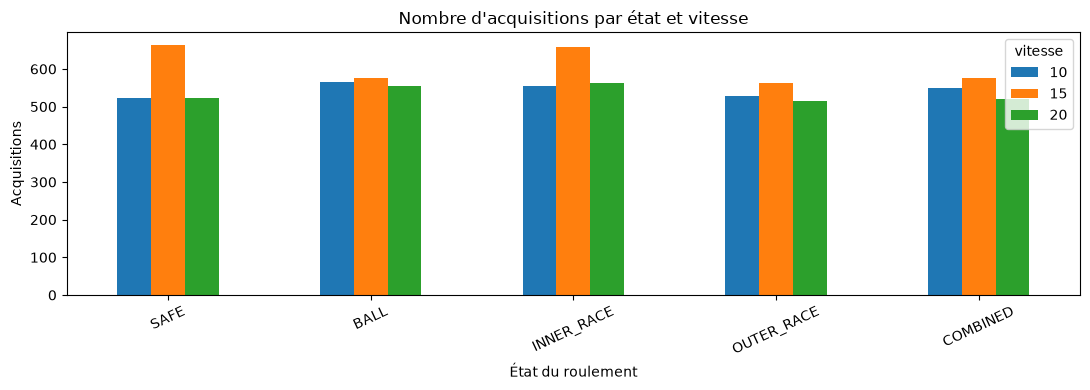

In [9]:
repartition = pd.crosstab([bd.classe, bd.vitesse], bd.split)
display(repartition)
fig, ax = plt.subplots(figsize=(11, 4))
bd.groupby(["classe", "vitesse"]).size().unstack("vitesse").loc[list(CLASSES)].plot.bar(ax=ax, rot=25)
ax.set(title="Nombre d'acquisitions par état et vitesse", xlabel="État du roulement", ylabel="Acquisitions")
plt.tight_layout(); plt.show()

## 2. Analyse exploratoire sur le train (V4, section 4)

Les données résumées sont accessibles : distributions de descripteurs, influence de la vitesse et spectres moyens. Les **formes d'onde temporelles** du notebook original nécessitent les Excel et ne sont pas reconstruites artificiellement.

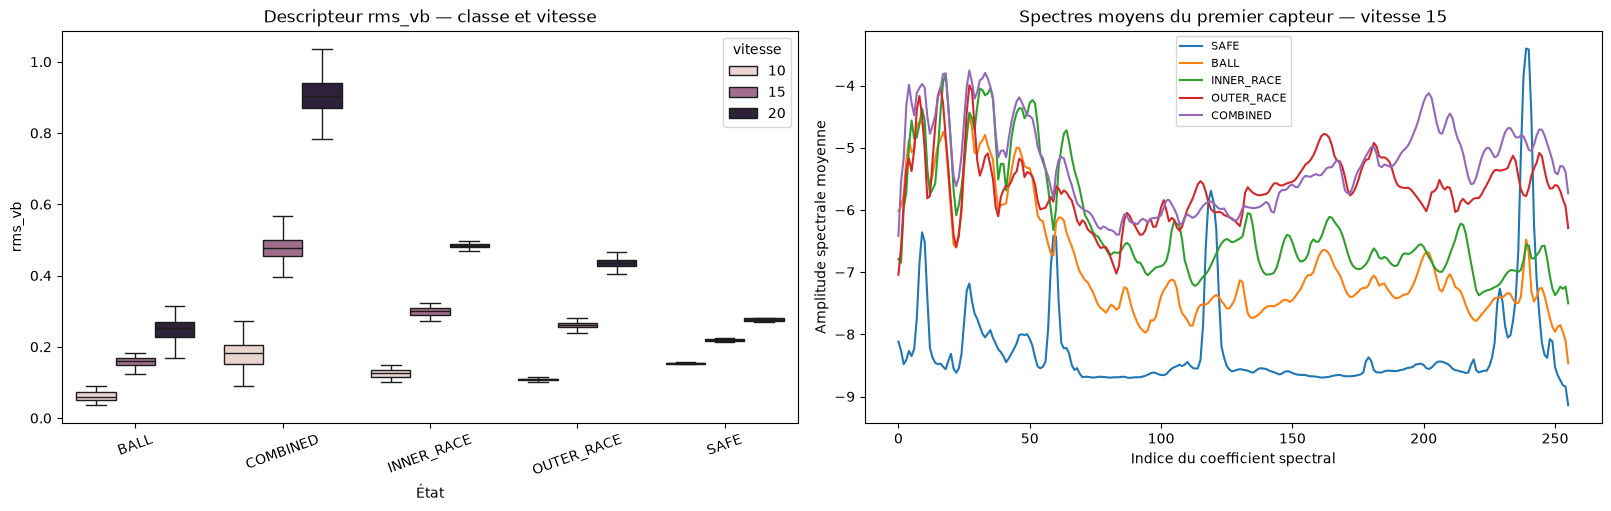

In [10]:
train = bd[bd.split == "train"]
choix = next((f for f in features if f.lower().startswith("rms_")), features[0])
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
sns.boxplot(data=train, x="classe", y=choix, hue="vitesse", ax=axes[0], showfliers=False)
axes[0].set(title=f"Descripteur {choix} — classe et vitesse", xlabel="État", ylabel=choix)
axes[0].tick_params(axis="x", rotation=20)
for classe in CLASSES:
    masque = (bd.classe == classe) & (bd.vitesse == 15) & (bd.split == "train")
    axes[1].plot(np.arange(256), spectra[masque.to_numpy(), :256].mean(axis=0), label=classe)
axes[1].set(title="Spectres moyens du premier capteur — vitesse 15", xlabel="Indice du coefficient spectral", ylabel="Amplitude spectrale moyenne")
axes[1].legend(fontsize=8)
plt.show()

## 3. Familles d'autoencodeurs et comparabilité (V4, section 5)

| Famille | Entrée | Espace latent | Particularité |
|---|---|---:|---|
| **MLP-AE** | 26 descripteurs | 6 | Référence V4, activation `tanh`, structure 16–6–16 |
| **Denoising-AE** | 26 descripteurs | 6 | Bruit sur l'entrée à l'apprentissage, cible propre |
| **VAE** | 26 descripteurs | 6 | Régularisation variationnelle avec KL |
| **CNN-AE spectral** | 512 coefficients (2 × 256) | 6 | Convolutions exploitant la structure spectrale |

Pour mieux comparer les architectures, l'espace latent a une dimension commune de 6 et les mêmes fichiers composent chaque split. **Attention :** CNN-AE exploite une représentation d'entrée différente (spectre plutôt que descripteurs), ce qui doit être distingué de l'effet de l'architecture. Le MLP conserve son optimiseur Scikit-learn et les autres familles utilisent PyTorch : les budgets d'entraînement ne sont pas parfaitement équivalents.

## 4. Détection d'anomalies (V4, section 6)

**Protocole commun :** entraîner chaque autoencodeur uniquement sur les acquisitions SAFE du train, calibrer son seuil au 99e percentile des SAFE de validation, puis mesurer AUROC, rappel, précision et fausses alarmes sur le test. Standardisation globale ajustée sur SAFE train, comme la stratégie de détection de la V4.

### A4.1 Métriques

In [11]:
affichage_detection = resultats["detection"].set_index("famille")
display(affichage_detection[["auroc", "rappel", "precision", "taux_fausses_alarmes", "fp", "fn", "seuil_p99_validation"]].round(5))

,auroc,rappel,precision,taux_fausses_alarmes,fp,fn,seuil_p99_validation
famille,,,,,,,
MLP-AE,1.0,1.0,0.99704,0.01172,3,0,0.15711
Denoising-AE,1.0,1.0,0.99704,0.01172,3,0,0.19264
VAE,1.0,1.0,0.99213,0.03125,8,0,0.32814
CNN-AE spectral,1.0,1.0,0.99605,0.01562,4,0,0.19772


**Lecture du tableau A4.1.** Le TEST comporte 1 009 acquisitions défectueuses et 256 SAFE. Les quatre familles détectent les 1 009 défauts (rappel = 1), mais MLP-AE et Denoising-AE déclenchent chacun **3 fausses alarmes**, CNN-AE **4** et VAE **8**. Avec une AUROC identique, c'est la calibration du seuil et le coût qui permettent de différencier les détecteurs ; la partie C3 les compare aux méthodes sans AE.

### A4.2 Courbes d'apprentissage et de validation

Les courbes proviennent des entraînements effectivement réalisés pendant la préparation du rapport. Pour PyTorch, les pertes train/validation sont disponibles. Pour le MLP (Scikit-learn), la courbe est l'évolution de la perte et la validation interne repose sur un score R², qu'il ne faut **pas confondre avec une MSE**. Les différences de protocole et de fonction de perte empêchent de comparer naïvement les hauteurs de courbe entre familles ; on analyse surtout leur évolution et l'absence de divergence manifeste.

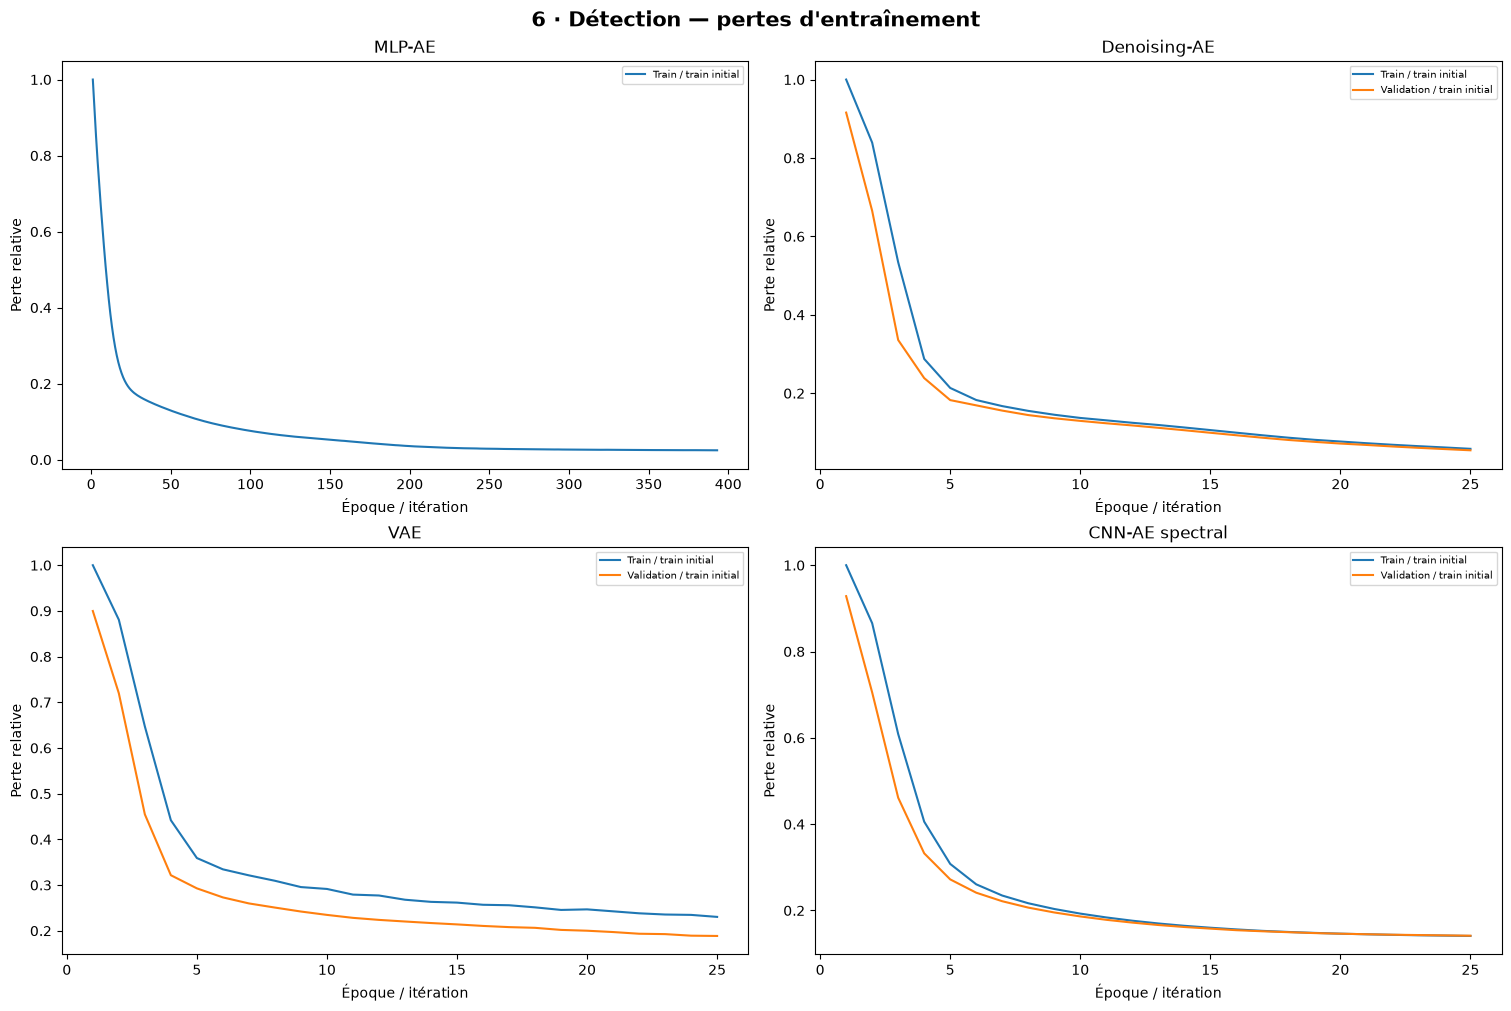

In [12]:
_ = courbes_apprentissage(resultats, "detection")

### A4.3 ROC, distribution des erreurs et matrices de confusion

Les quatre courbes ROC présentent **AUROC = 1,0000** sur le TEST. Cela mesure la qualité du classement des scores, mais **n'implique pas** zéro fausse alarme au seuil choisi. Les matrices montrent **0 défaut manqué** parmi 1 009 acquisitions défectueuses, mais **3 à 8 fausses alarmes** parmi 256 acquisitions SAFE selon l'architecture.

**Lisibilité :** les distributions d'erreurs de reconstruction ci-dessous sont visuellement compressées par des valeurs extrêmes. Les amplitudes ne sont pas comparables entre architectures : pour comparer les détecteurs au seuil opérationnel, se reporter aux matrices de confusion et au graphique de synthèse de C3.

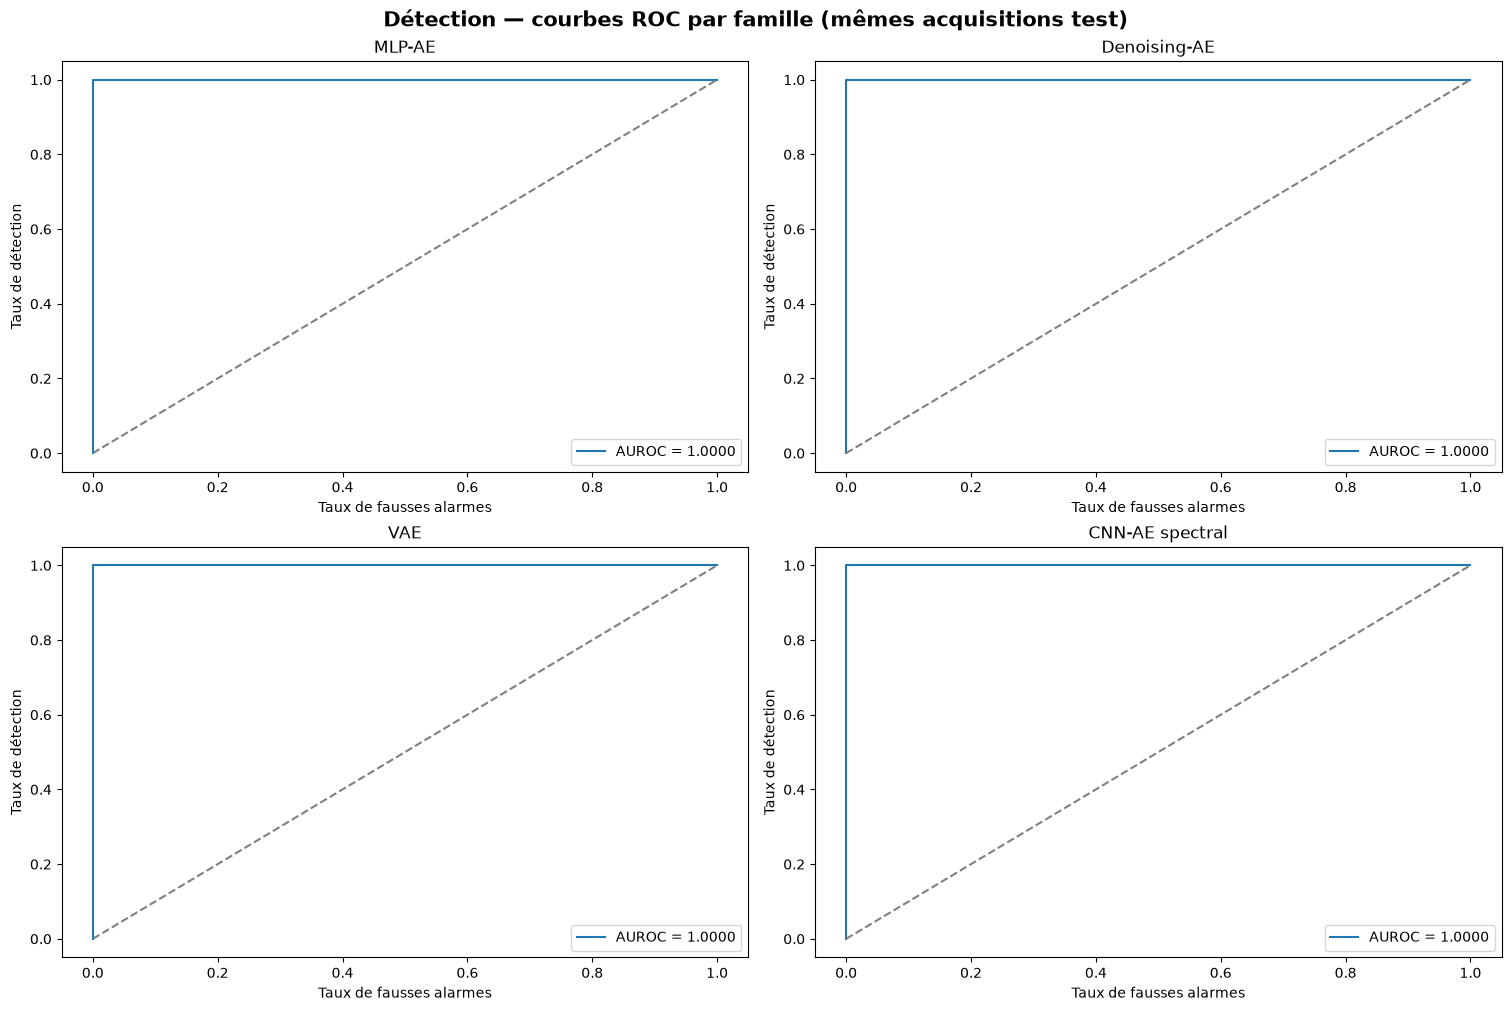

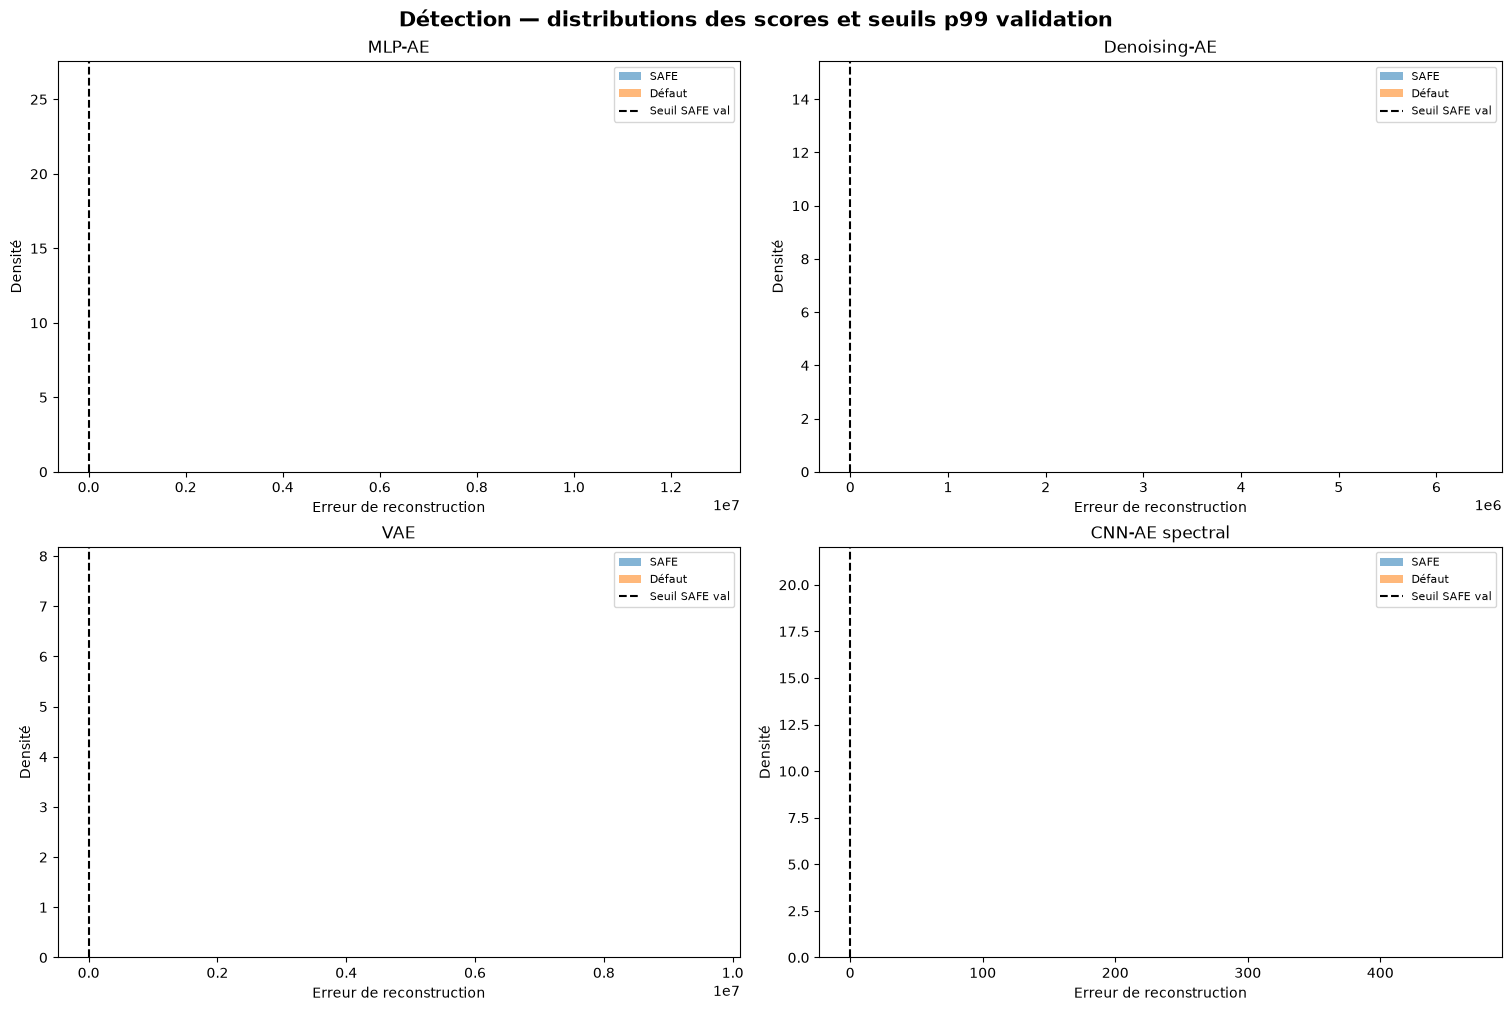

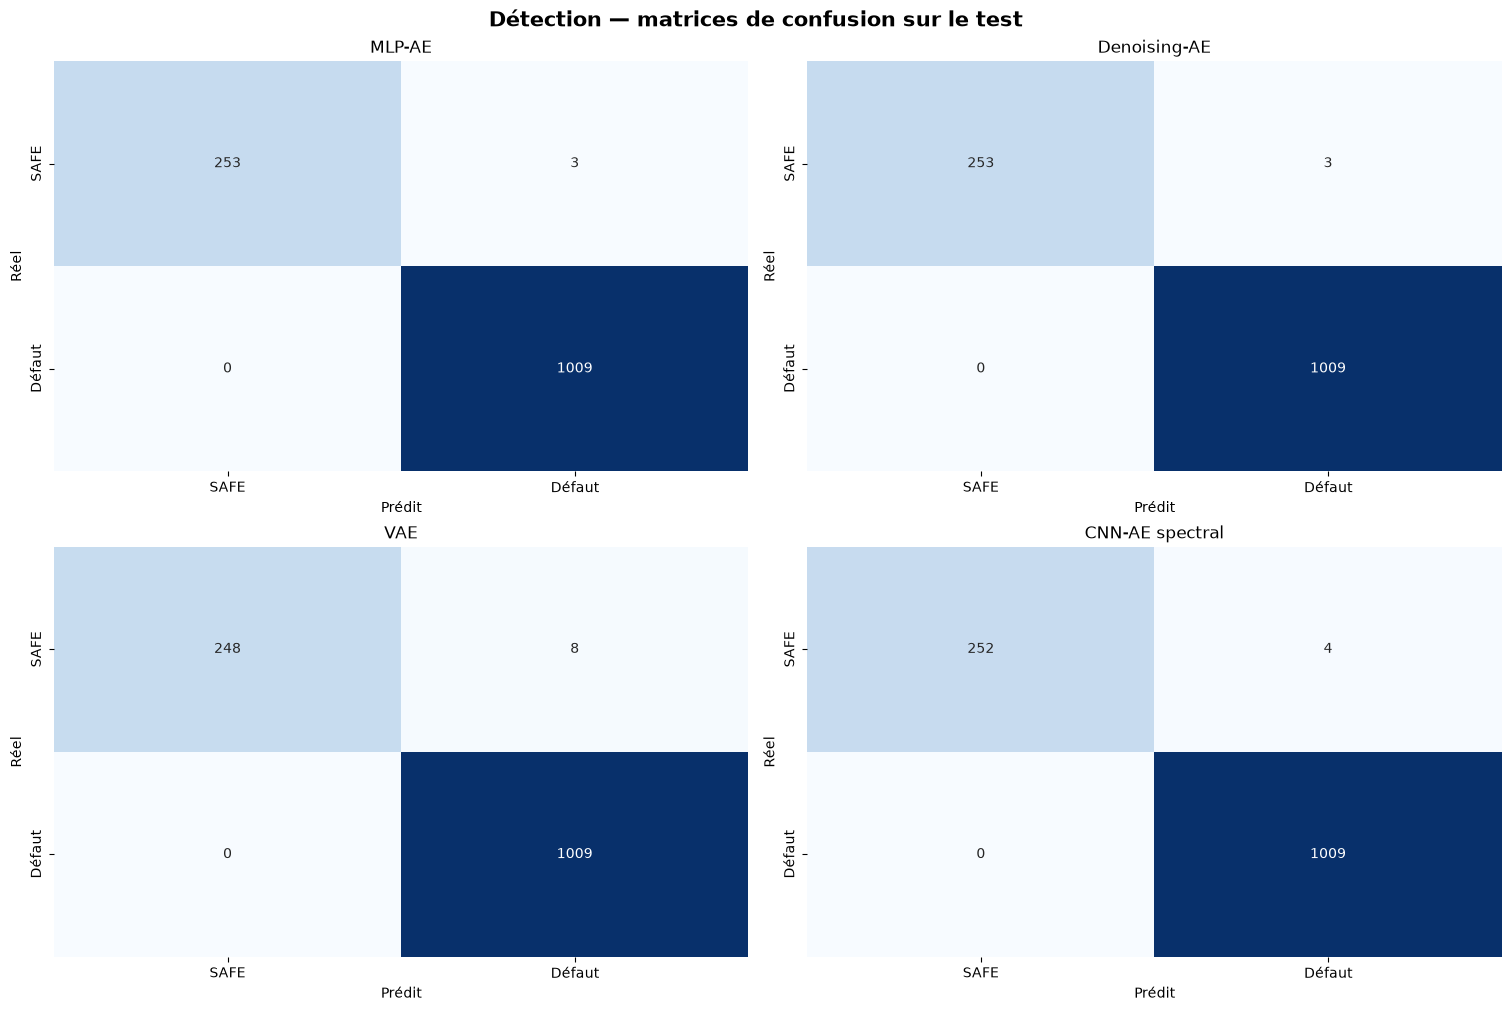

In [13]:
_ = roc_detection(resultats)
_ = scores_detection(resultats)
_ = confusions_detection(resultats)

### A4.4 Vérification par vitesse *connue*

Les trois vitesses 10, 15 et 20 figurent **déjà dans l'entraînement** de ces modèles. Le rappel reste de 1 sur chaque régime présent ; les fausses alarmes ne sont pas uniformément réparties. **Ce graphique ne constitue pas un test de vitesse inconnue**, étudié séparément pour des méthodes classiques en C3 bis.

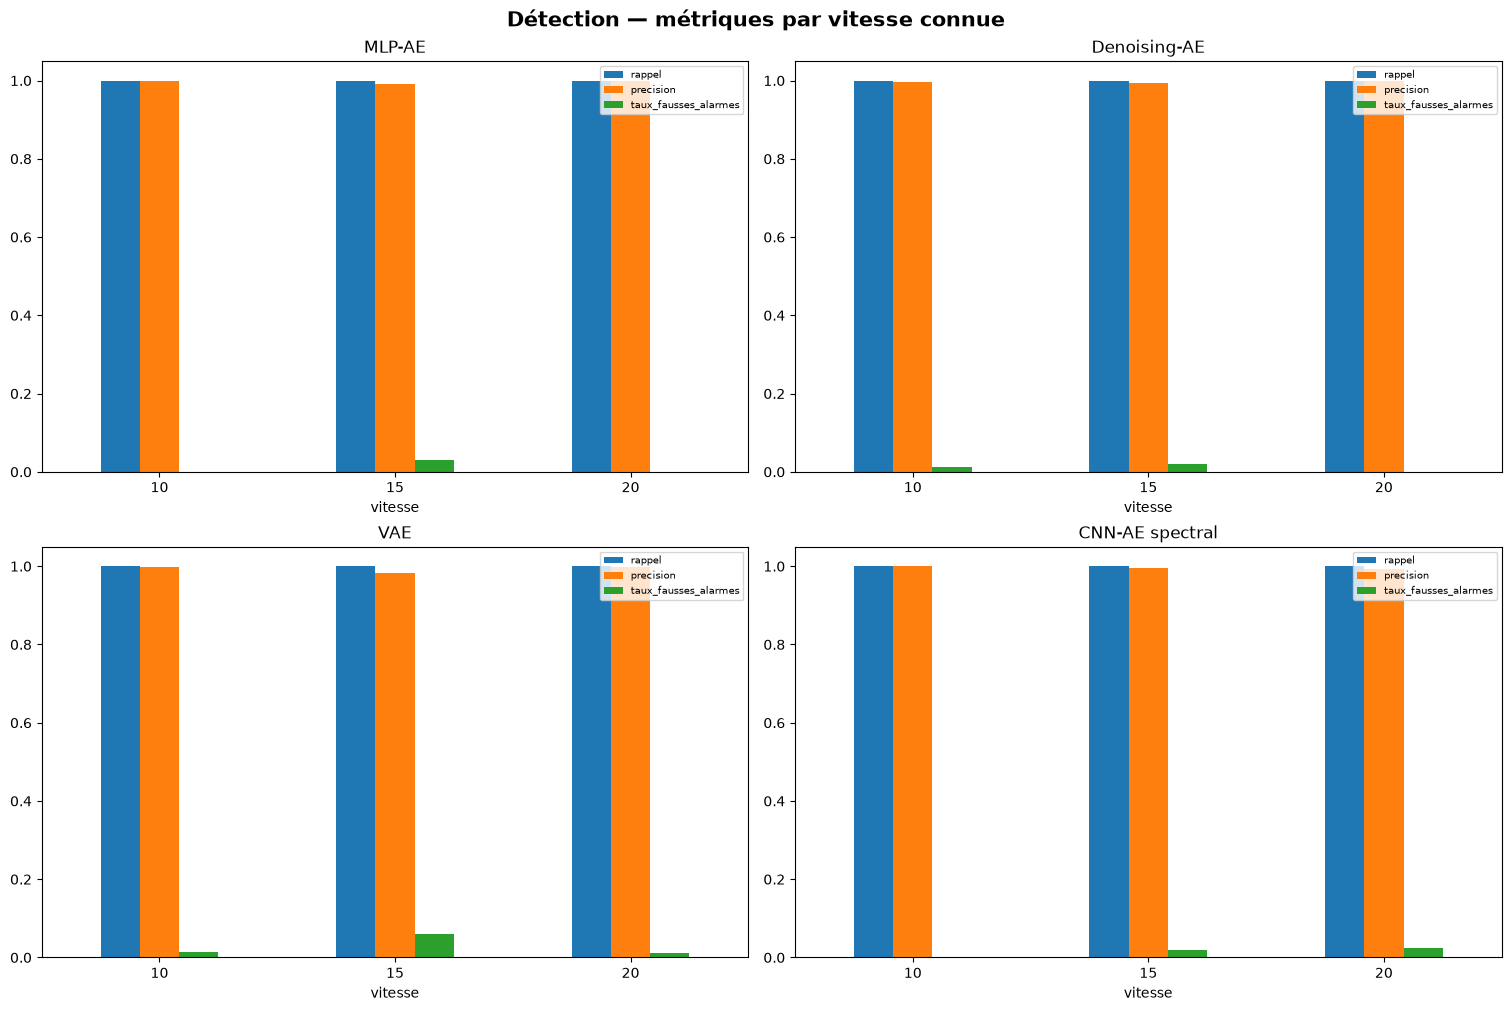

,famille,vitesse,rappel,taux_fausses_alarmes,precision
0,MLP-AE,10,1.0,0.00000,1.00000
1,MLP-AE,15,1.0,0.03030,0.99167
2,MLP-AE,20,1.0,0.00000,1.00000
3,Denoising-AE,10,1.0,0.01282,0.99698
4,Denoising-AE,15,1.0,0.02020,0.99443
5,Denoising-AE,20,1.0,0.00000,1.00000
6,VAE,10,1.0,0.01282,0.99698
7,VAE,15,1.0,0.06061,0.98347
8,VAE,20,1.0,0.01266,0.99690
9,CNN-AE spectral,10,1.0,0.00000,1.00000


In [14]:
detection_vitesses, _ = scores_par_vitesse(resultats)
display(detection_vitesses.round(5))

## 5. Clustering sans correction de vitesse (V4, section 7)

**Protocole :** standardisation globale ajustée sur tous les états du train ; un autoencodeur par famille entraîné sur les acquisitions du train ; extraction de l'espace latent ; K-means K=5 ajusté sur le train ; mesure ARI, NMI et silhouette. Comparaison systématique à K-means directement appliqué à l'entrée du modèle, comme la baseline V4.

,famille,approche,ari,nmi,silhouette_train,ari_vs_vitesse
0,MLP-AE,autoencodeur,0.5101,0.6657,0.5073,0.2260
1,MLP-AE,baseline_kmeans,0.5248,0.6937,0.4840,0.1038
2,Denoising-AE,autoencodeur,0.4911,0.6198,0.4744,0.1990
3,Denoising-AE,baseline_kmeans,0.5248,0.6937,0.4840,0.1038
4,VAE,autoencodeur,0.6296,0.7453,0.4588,0.1909
5,VAE,baseline_kmeans,0.5248,0.6937,0.4840,0.1038
6,CNN-AE spectral,autoencodeur,0.5133,0.6687,0.5293,0.2153
7,CNN-AE spectral,baseline_kmeans,0.5269,0.6705,0.4920,0.1399


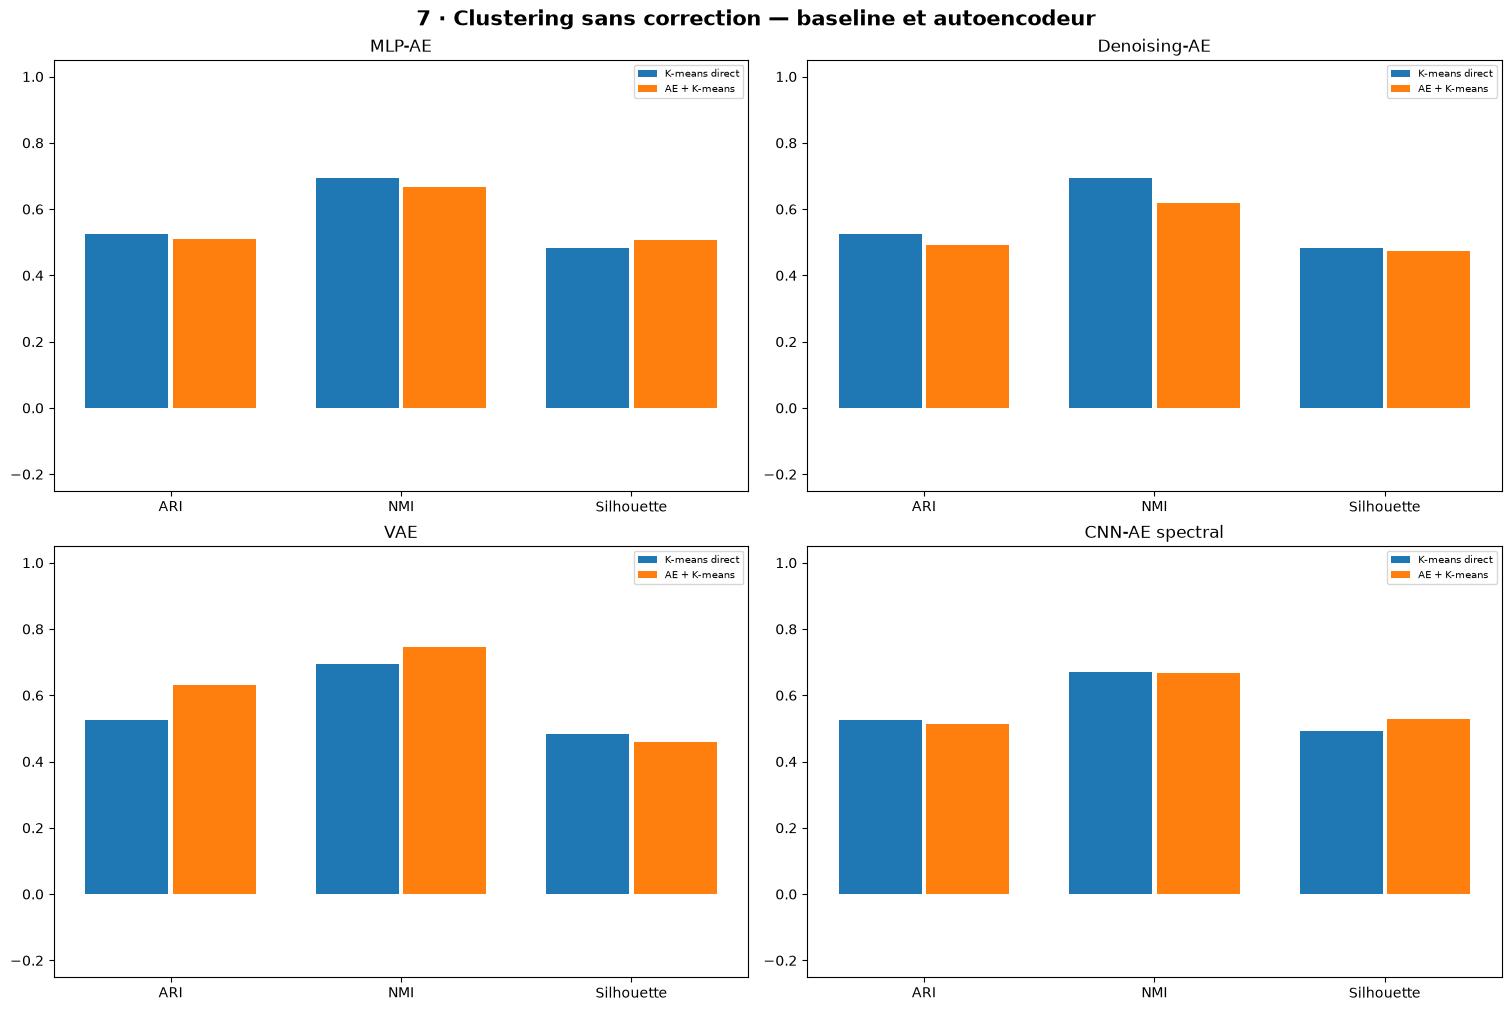

In [15]:
d = resultats["clustering"]
display(d[(d.strategie == "sans_correction")][["famille", "approche", "ari", "nmi", "silhouette_train", "ari_vs_vitesse"]].round(4))
_ = comparaison_baseline(resultats, "sans_correction")

### A5.1 Choix de K : coude et silhouette par famille

Chaque espace latent est examiné sur un **même sous-échantillon des acquisitions d'entraînement**. La ligne K=5 matérialise le nombre d'états connu ; silhouette et inertie donnent une indication sans recourir aux étiquettes.

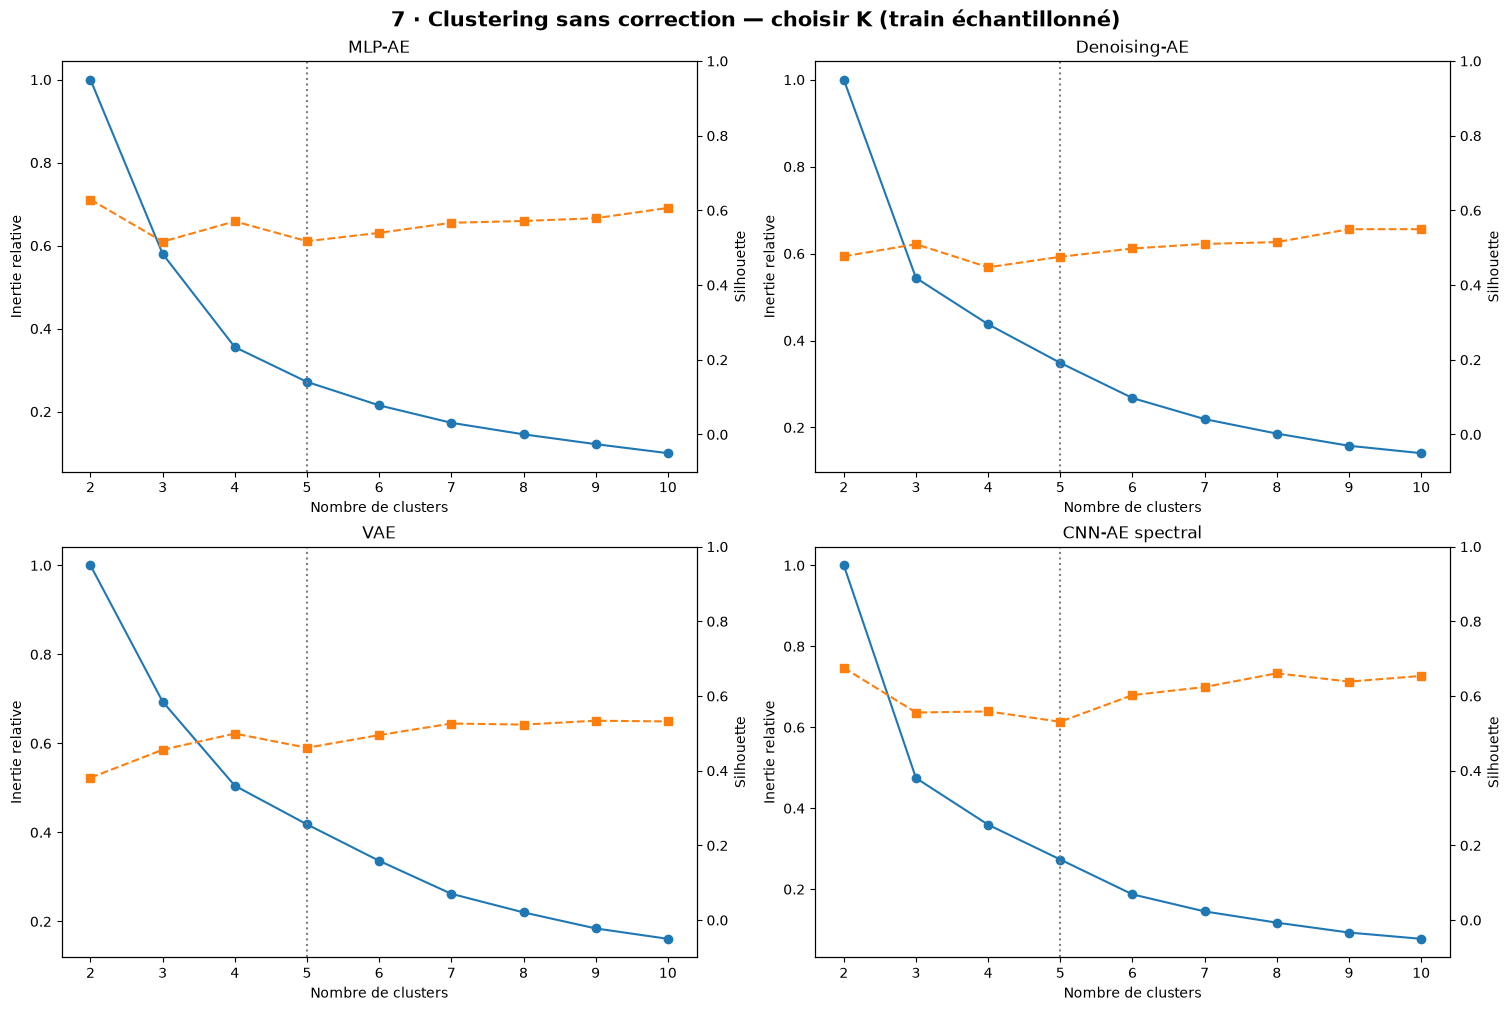

In [16]:
AFFICHER_CHOIX_K = True
if AFFICHER_CHOIX_K:
    _ = choix_k(resultats, "sans_correction")

### 5.2 Représentations latentes par classe et par vitesse

Les projections 2D sont calculées indépendamment pour chaque famille : comparer la séparation et la structure des groupes plutôt que les coordonnées numériques.

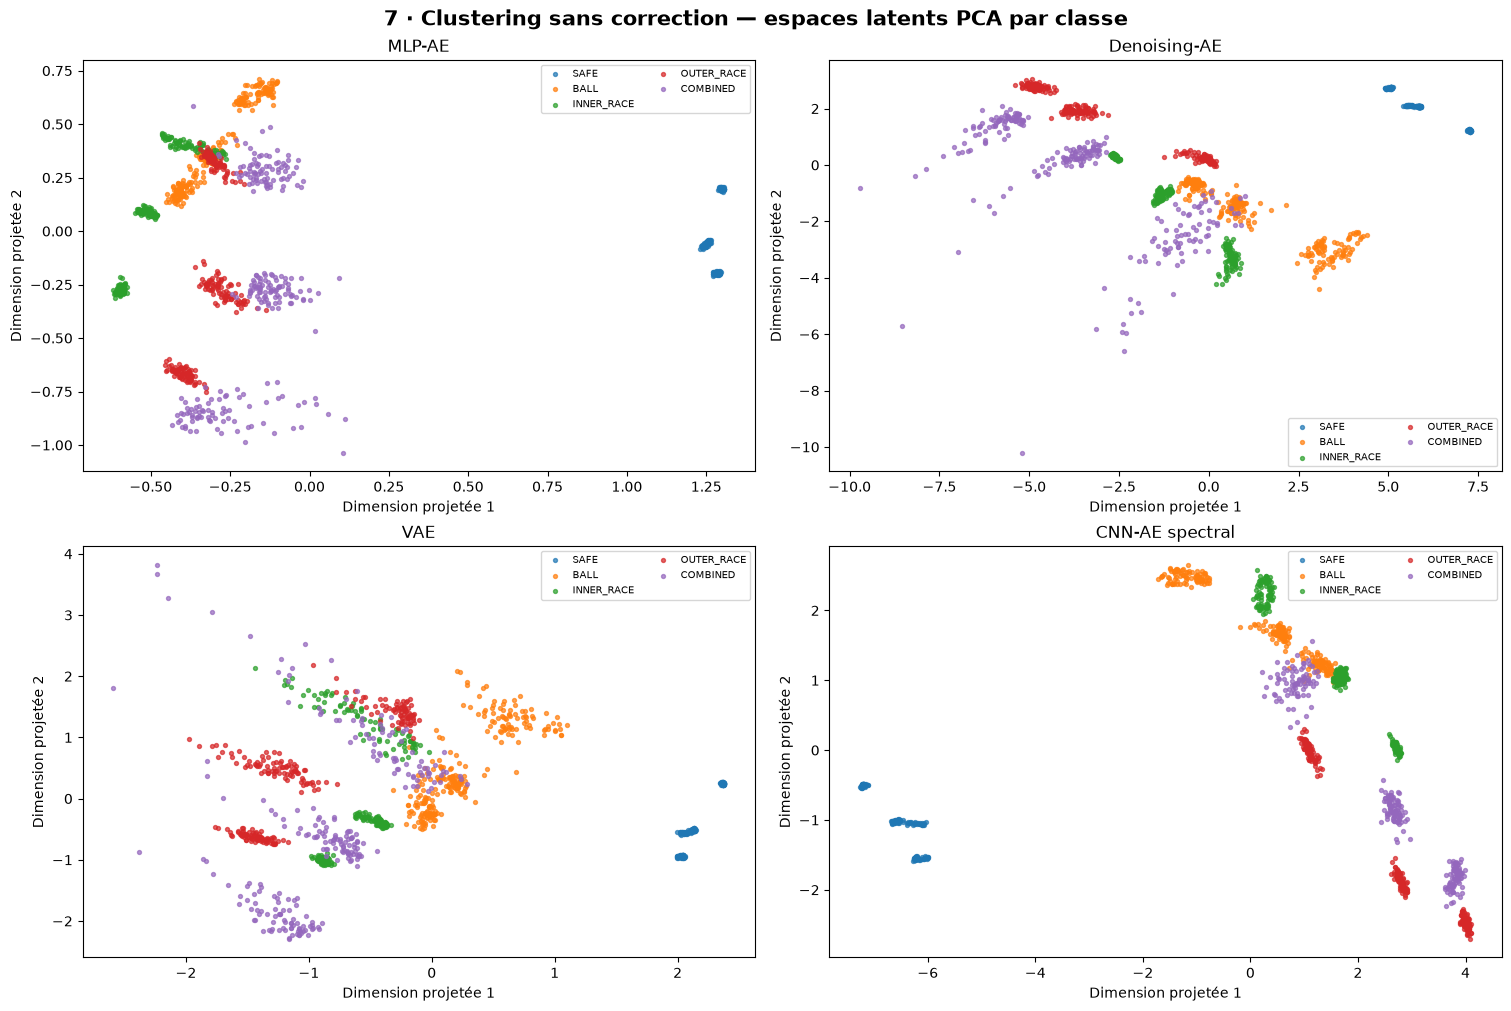

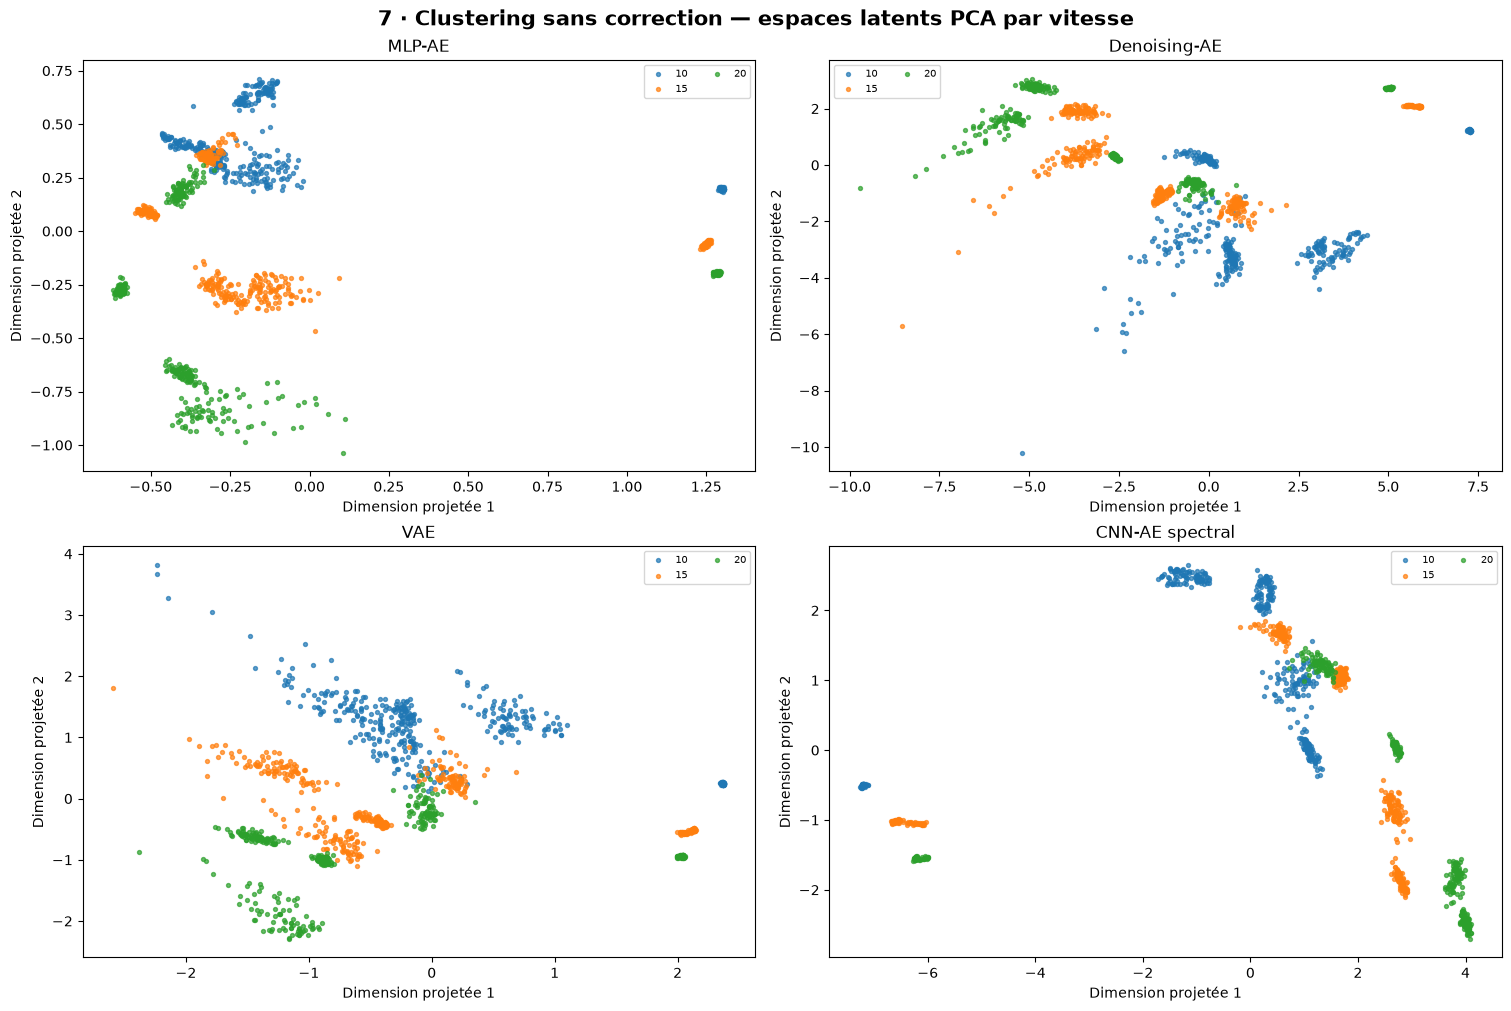

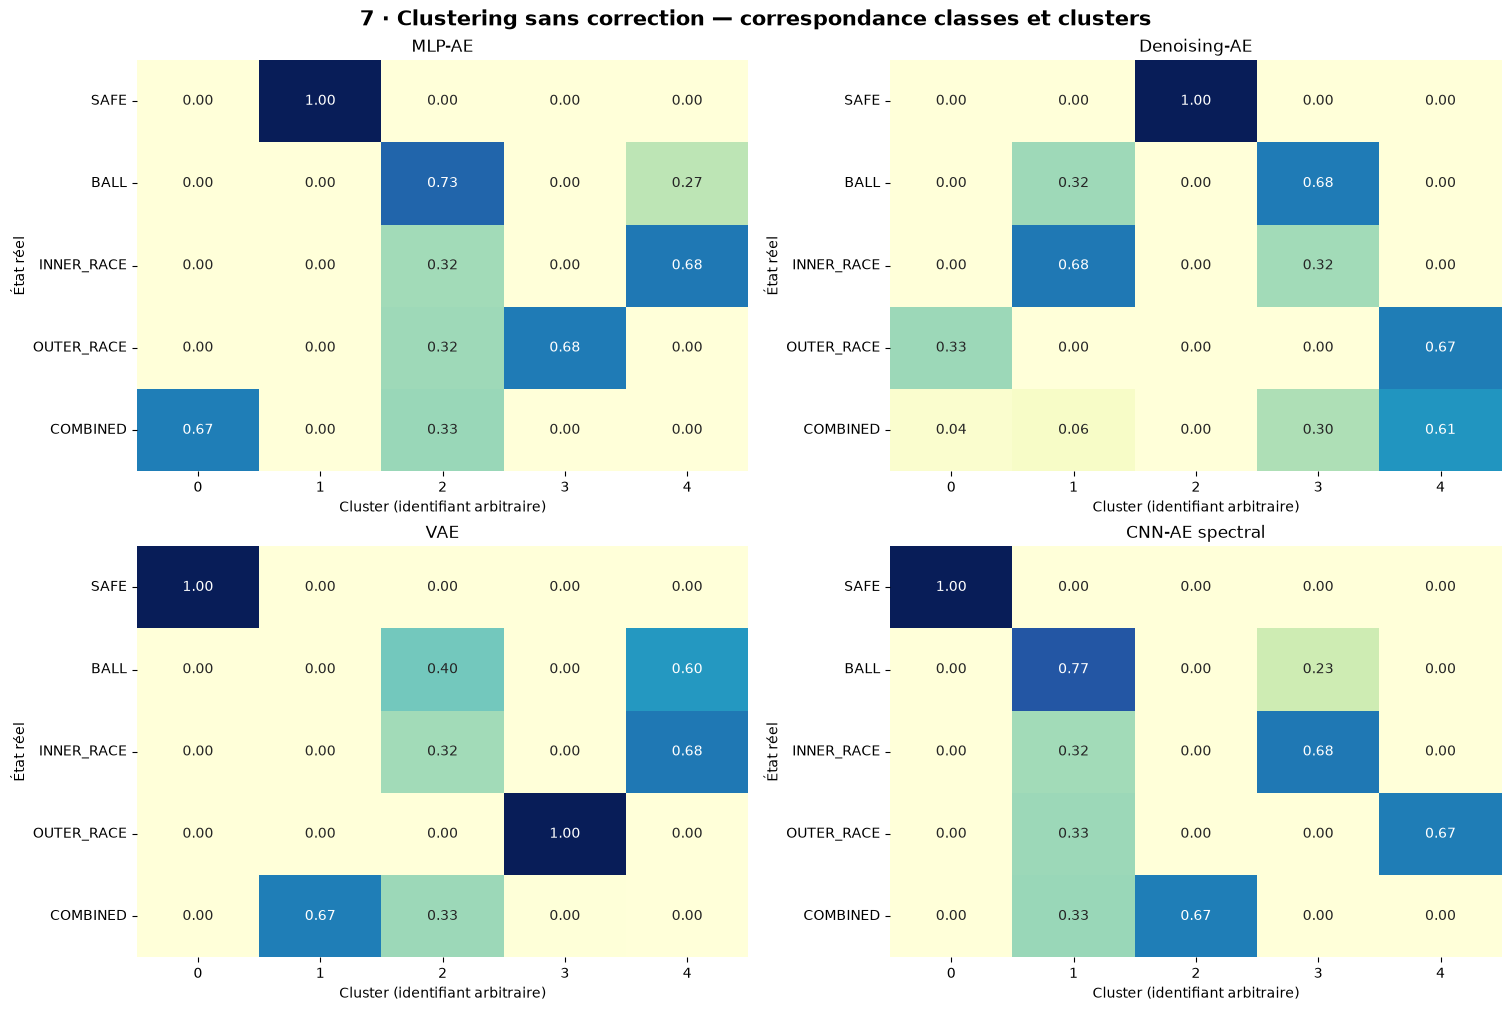

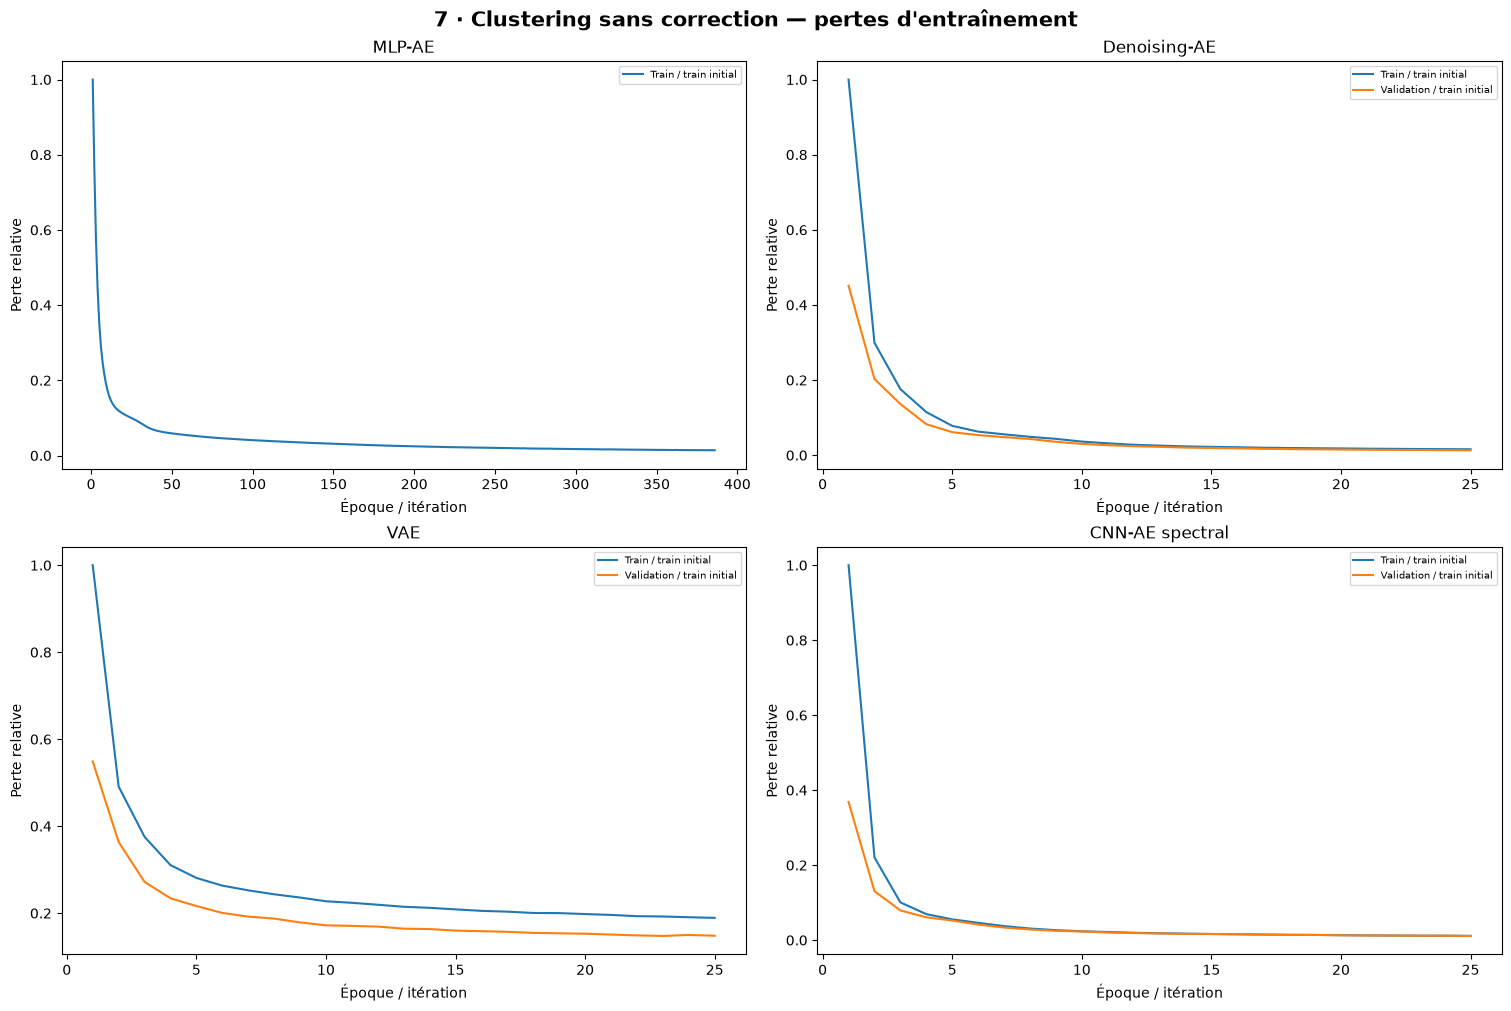

In [17]:
_ = vues_latentes(resultats, "sans_correction", colorer="classe")
_ = vues_latentes(resultats, "sans_correction", colorer="vitesse")
_ = tableaux_clustering(resultats, "sans_correction")
_ = courbes_apprentissage(resultats, "sans_correction")

## 6. Un modèle distinct par vitesse (V4, section 8)

**Protocole :** pour chaque vitesse, préparer uniquement les acquisitions de ce régime, entraîner quatre autoencodeurs et leur K-means sur le train correspondant et évaluer sur le test de la même vitesse. Les numéros de cluster sont **locaux à chaque vitesse** ; on ne doit pas calculer un ARI global en confondant leurs numéros.

Cette étape représente **12 entraînements de clustering** (4 familles × 3 vitesses), en plus des autres expériences.

,famille,vitesse_modele,approche,ari,nmi,silhouette_train
8,MLP-AE,10,autoencodeur,1.0000,1.0000,0.7518
9,MLP-AE,10,baseline_kmeans,0.9522,0.9593,0.6638
10,Denoising-AE,10,autoencodeur,0.8999,0.9307,0.6827
11,Denoising-AE,10,baseline_kmeans,0.9522,0.9593,0.6638
12,VAE,10,autoencodeur,0.9875,0.9835,0.7226
13,VAE,10,baseline_kmeans,0.9522,0.9593,0.6638
14,CNN-AE spectral,10,autoencodeur,1.0000,1.0000,0.8508
15,CNN-AE spectral,10,baseline_kmeans,1.0000,1.0000,0.7591
16,MLP-AE,15,autoencodeur,1.0000,1.0000,0.7765
17,MLP-AE,15,baseline_kmeans,1.0000,1.0000,0.6643


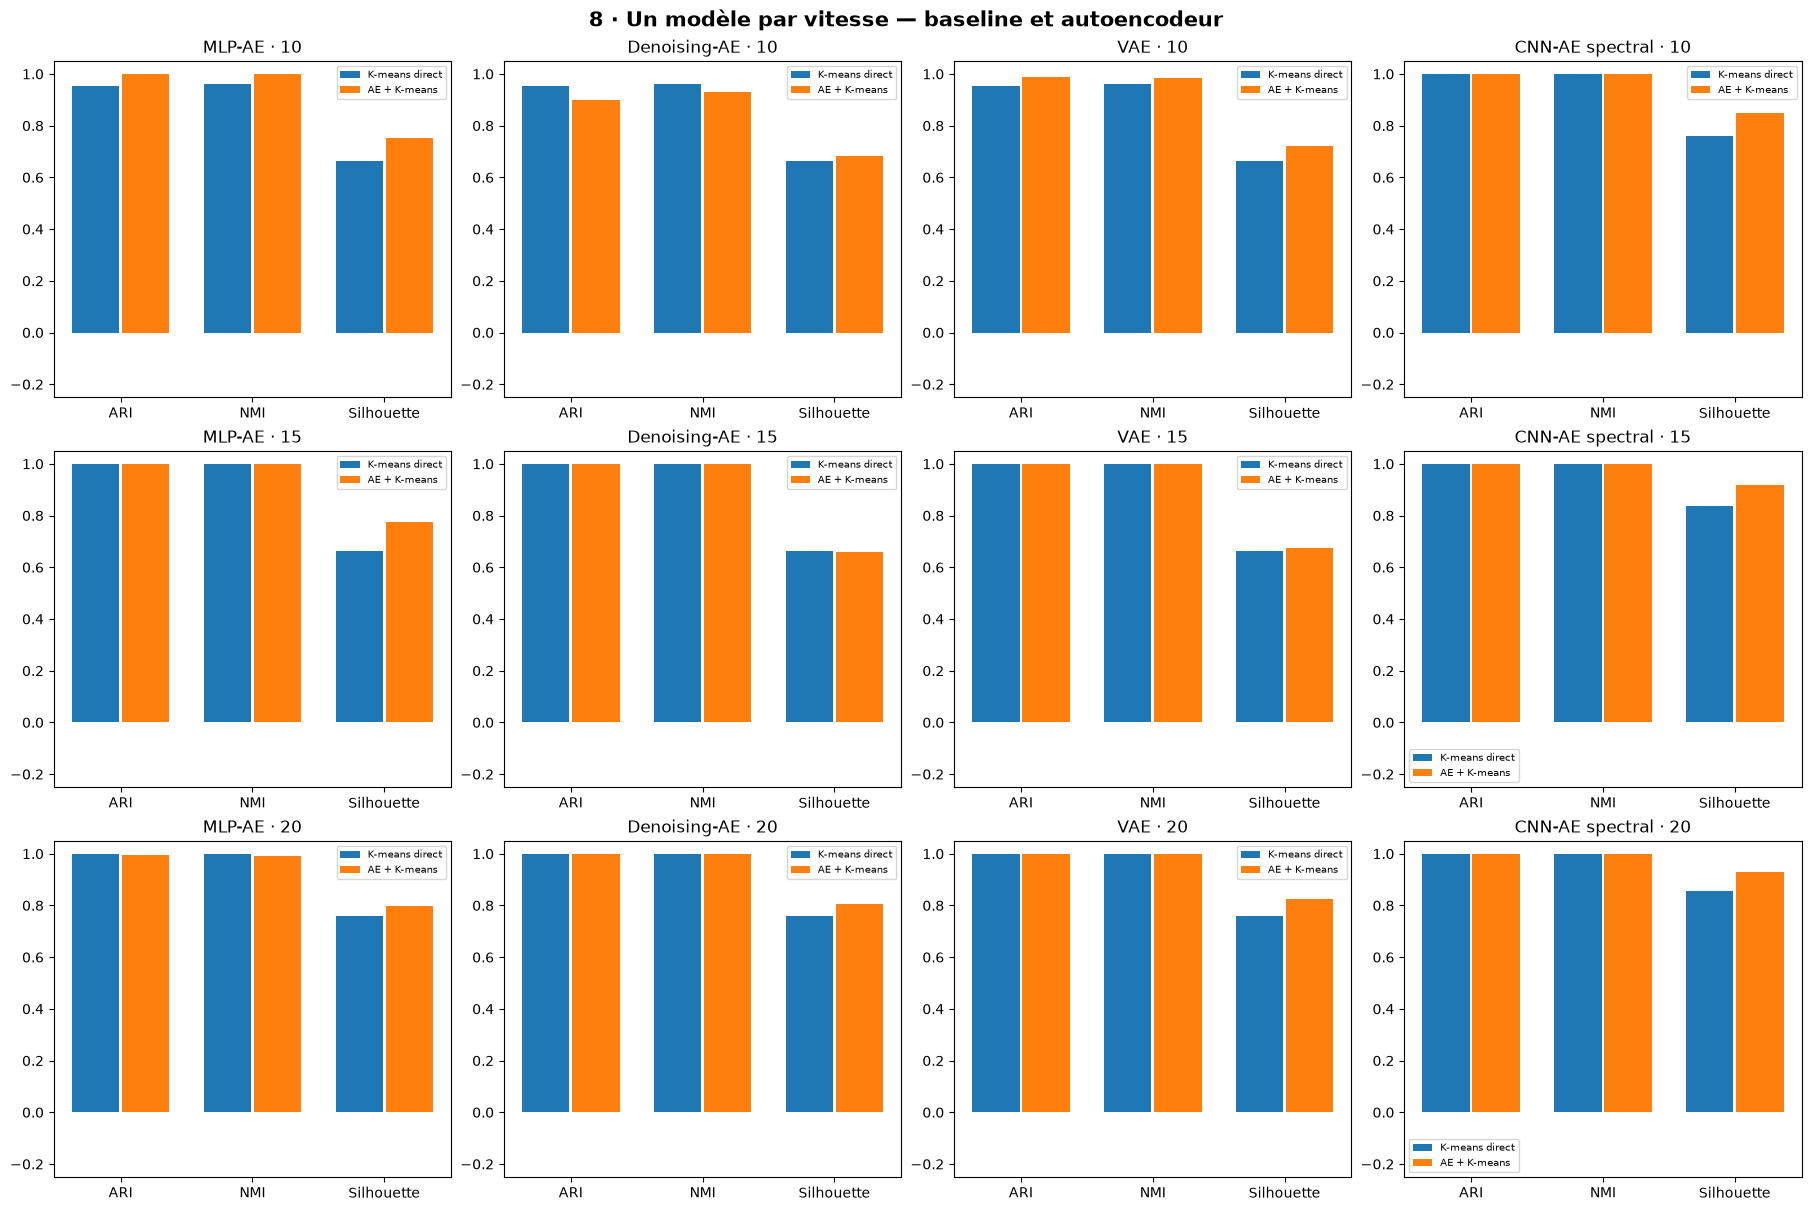

In [18]:
d = resultats["clustering"]
display(d[(d.strategie == "par_vitesse")][["famille", "vitesse_modele", "approche", "ari", "nmi", "silhouette_train"]].round(4))
_ = comparaison_baseline(resultats, "par_vitesse")

### 6.1 Espaces latents et correspondances — 3 lignes × 4 familles

Chaque ligne représente une vitesse 10, 15 ou 20 ; chaque colonne une famille. Les panneaux mettent en évidence les états de roulement, puis la correspondance entre les groupes K-means et les classes de test.

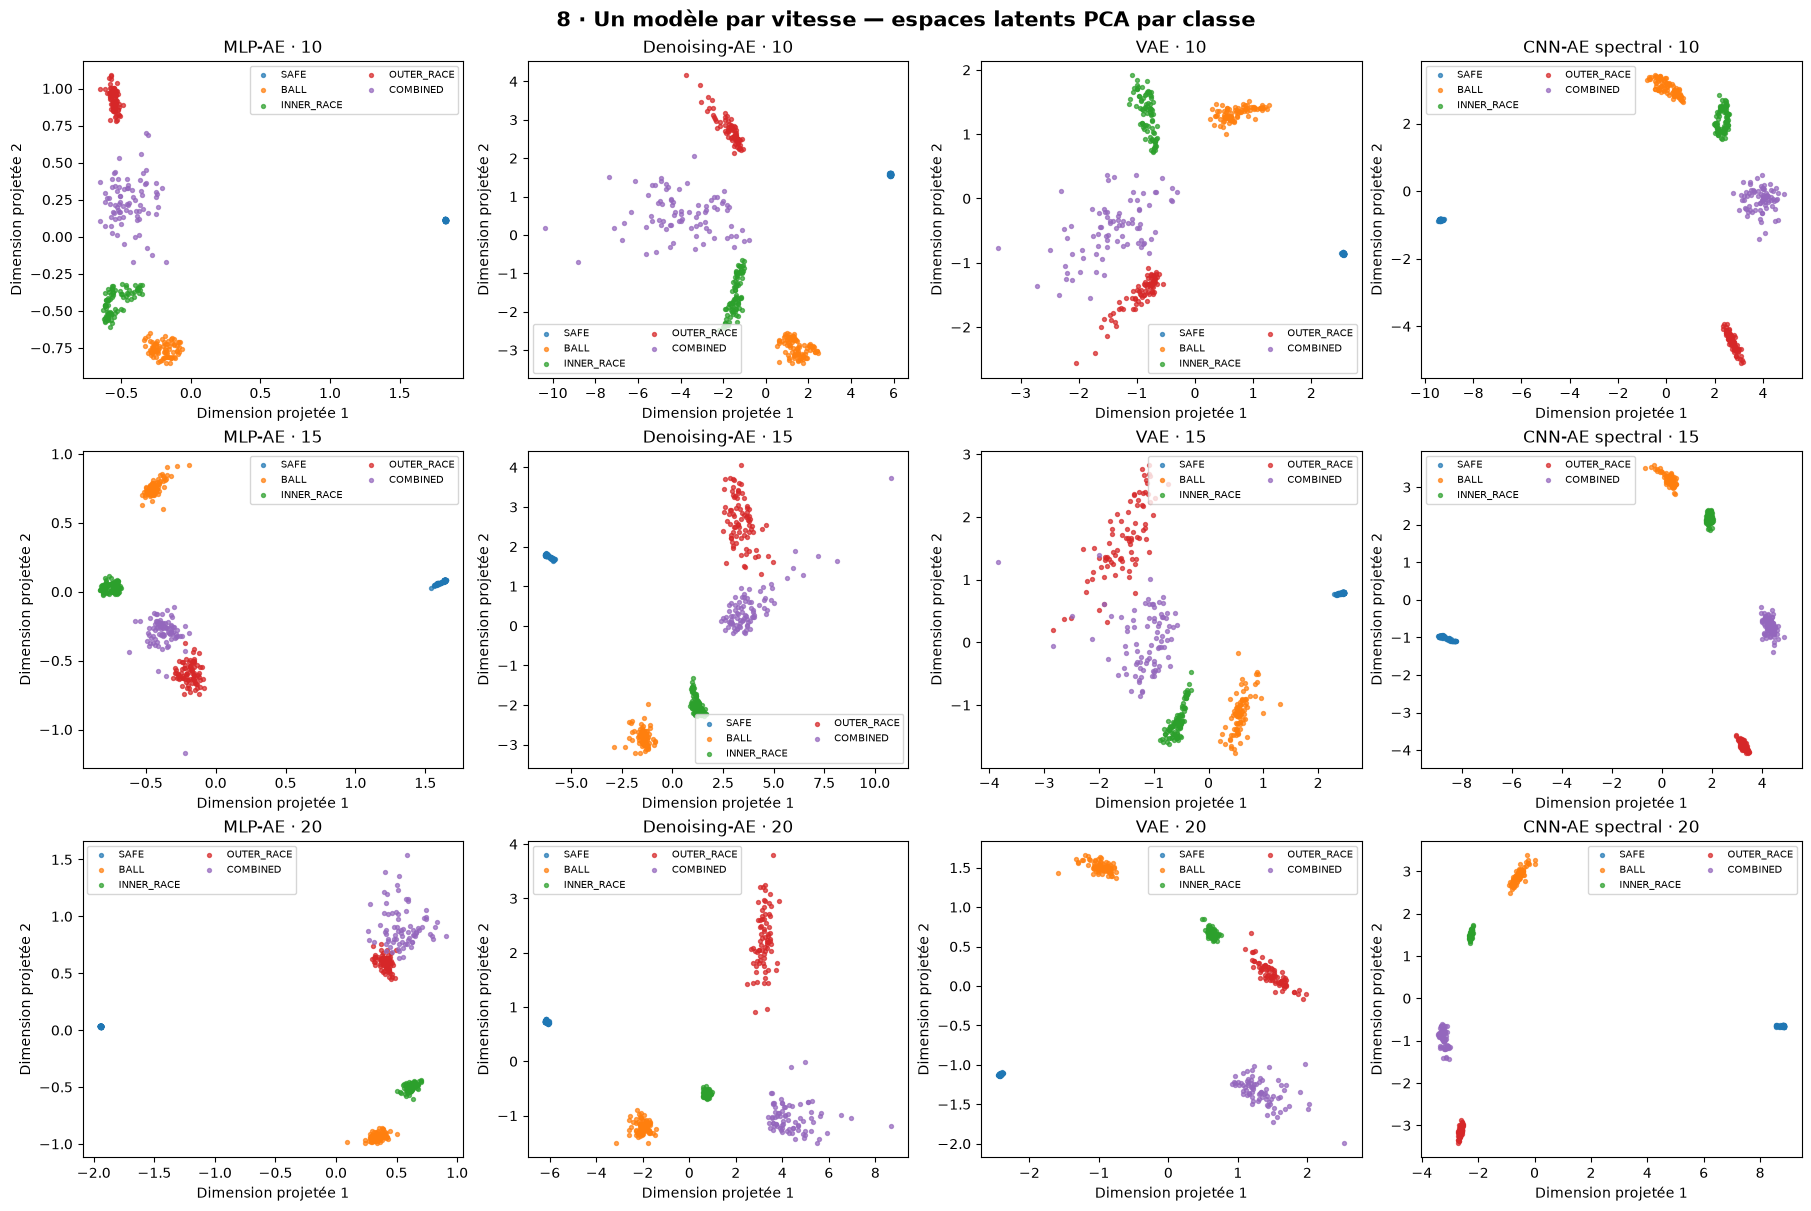

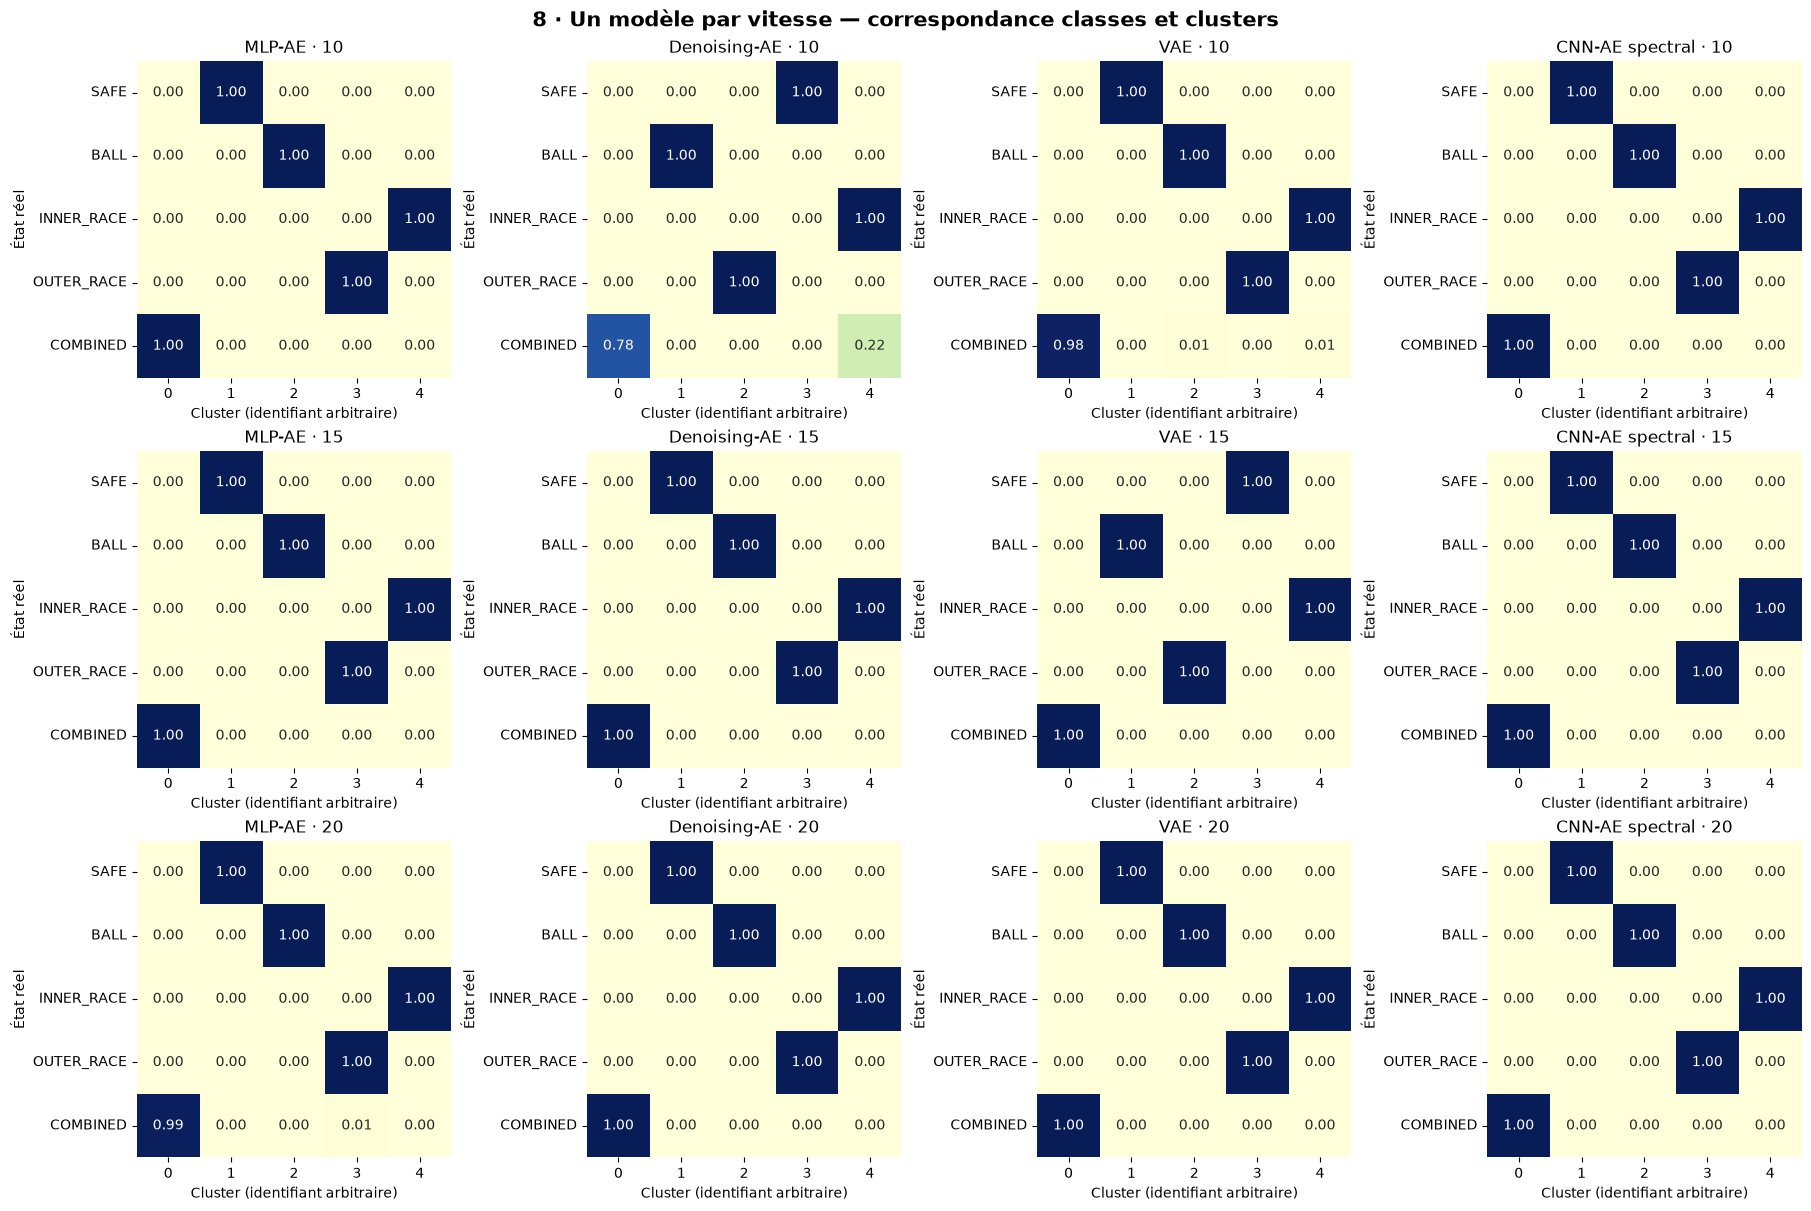

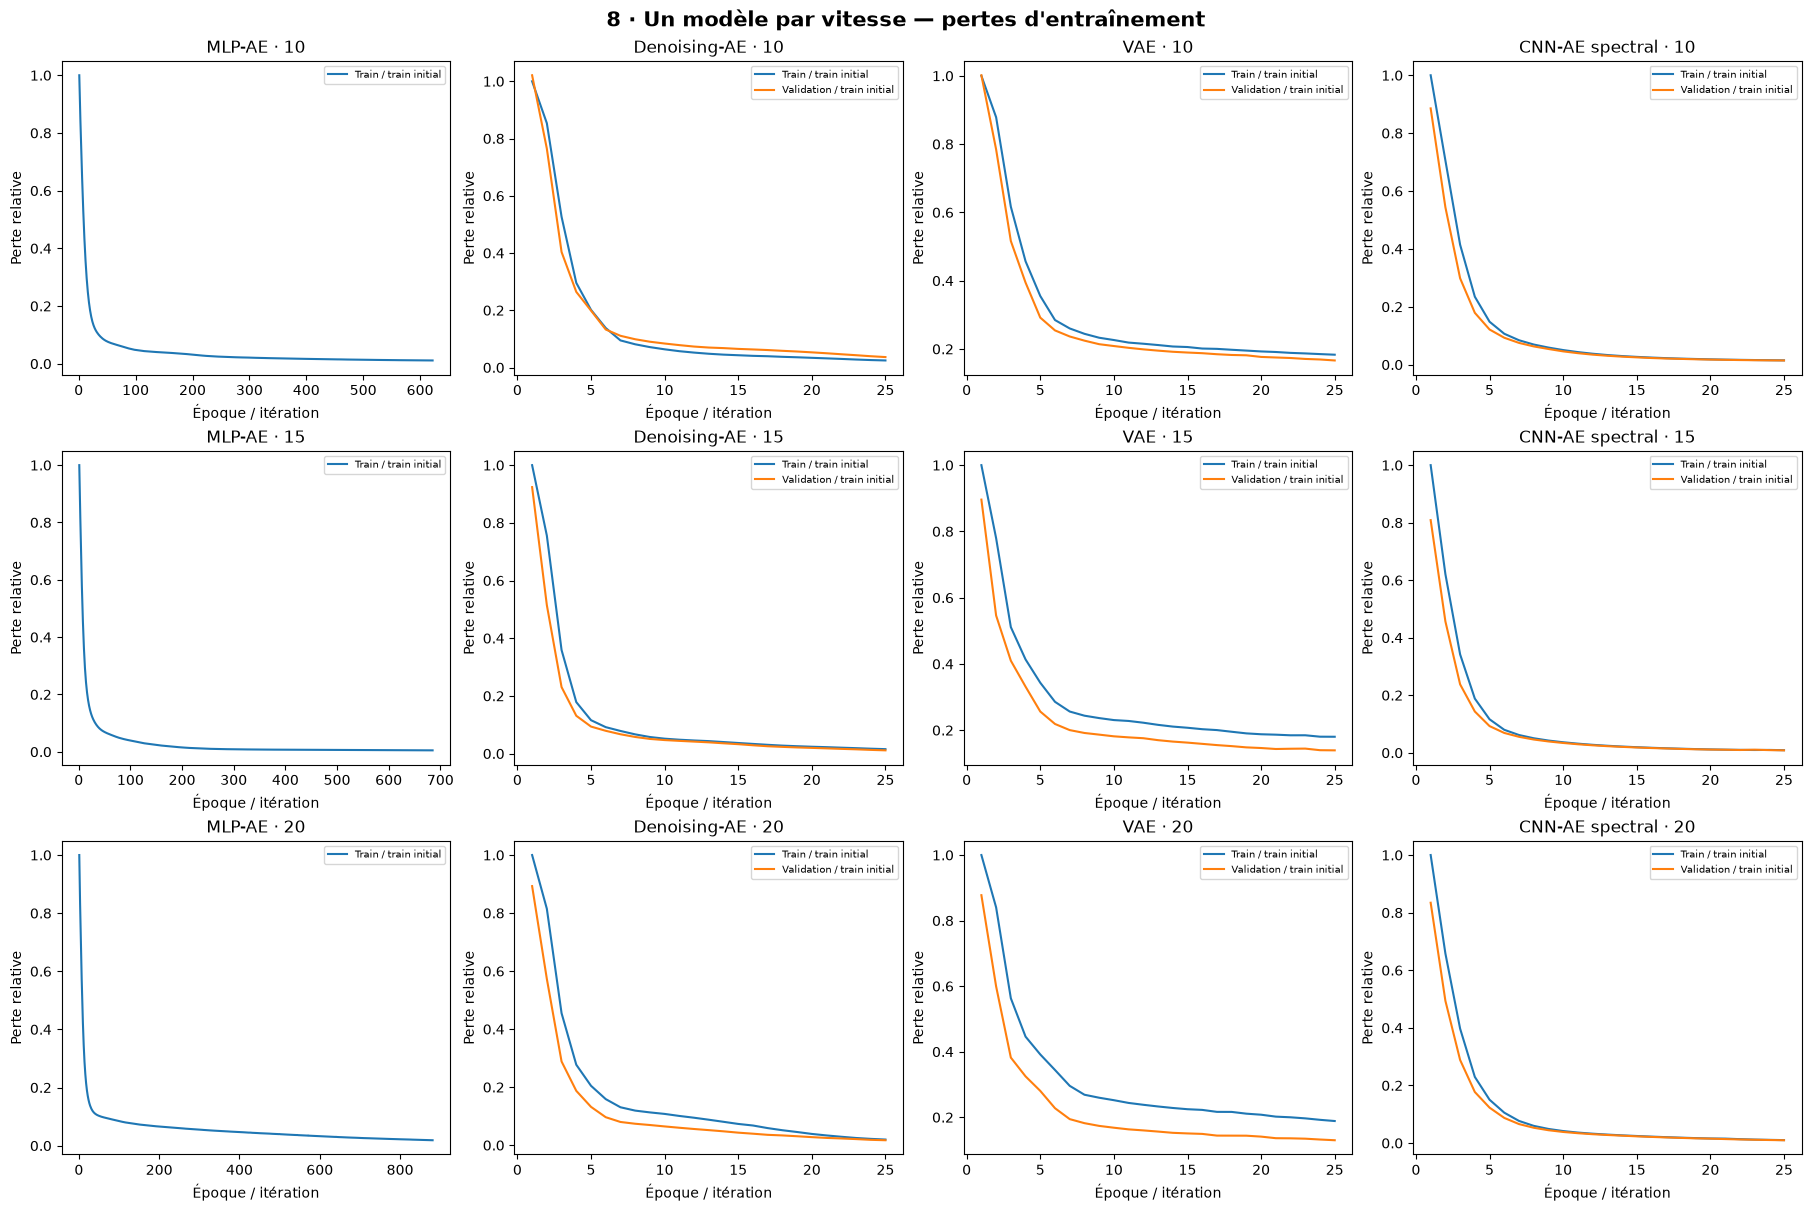

In [19]:
_ = vues_latentes(resultats, "par_vitesse", colorer="classe")
_ = tableaux_clustering(resultats, "par_vitesse")
_ = courbes_apprentissage(resultats, "par_vitesse")

### 6.2 Choix du nombre de clusters pour les modèles par vitesse (optionnel)

Le calcul du coude et de la silhouette peut être plus coûteux ; les résultats K=5 sont déjà sauvegardés. Activer cette figure si nécessaire pour le rapport.

In [20]:
AFFICHER_CHOIX_K_PAR_VITESSE = False
if AFFICHER_CHOIX_K_PAR_VITESSE:
    _ = choix_k(resultats, "par_vitesse")
else:
    print("Coude/silhouette par vitesse désactivé pour accélérer l'affichage.")

Coude/silhouette par vitesse désactivé pour accélérer l'affichage.


## 7. Correction de vitesse — modèle commun (V4, section 9)

**Densités/26 descripteurs :** `log10` sur RMS, crête, kurtosis, etc. positifs, puis standardisation distincte pour chaque vitesse à partir du **train de cette vitesse**, suivie d'un modèle unique pour les trois vitesses.

**CNN/spectres :** standardisation spectrale par vitesse sans log des 26 descripteurs (qui ne sont pas son entrée). Cette différence est scientifiquement explicitée, et non dissimulée.

K-means est ajusté sur l'espace latent train commun aux trois vitesses, puis évalué sur le test.

,famille,approche,ari,nmi,silhouette_train,ari_vs_vitesse
32,MLP-AE,autoencodeur,0.9981,0.9968,0.7024,-0.0017
33,MLP-AE,baseline_kmeans,0.9922,0.9885,0.6023,-0.0017
34,Denoising-AE,autoencodeur,0.9842,0.9824,0.6366,-0.0016
35,Denoising-AE,baseline_kmeans,0.9922,0.9885,0.6023,-0.0017
36,VAE,autoencodeur,0.9960,0.9942,0.5406,-0.0017
37,VAE,baseline_kmeans,0.9922,0.9885,0.6023,-0.0017
38,CNN-AE spectral,autoencodeur,1.0000,1.0000,0.7970,-0.0017
39,CNN-AE spectral,baseline_kmeans,1.0000,1.0000,0.7118,-0.0017


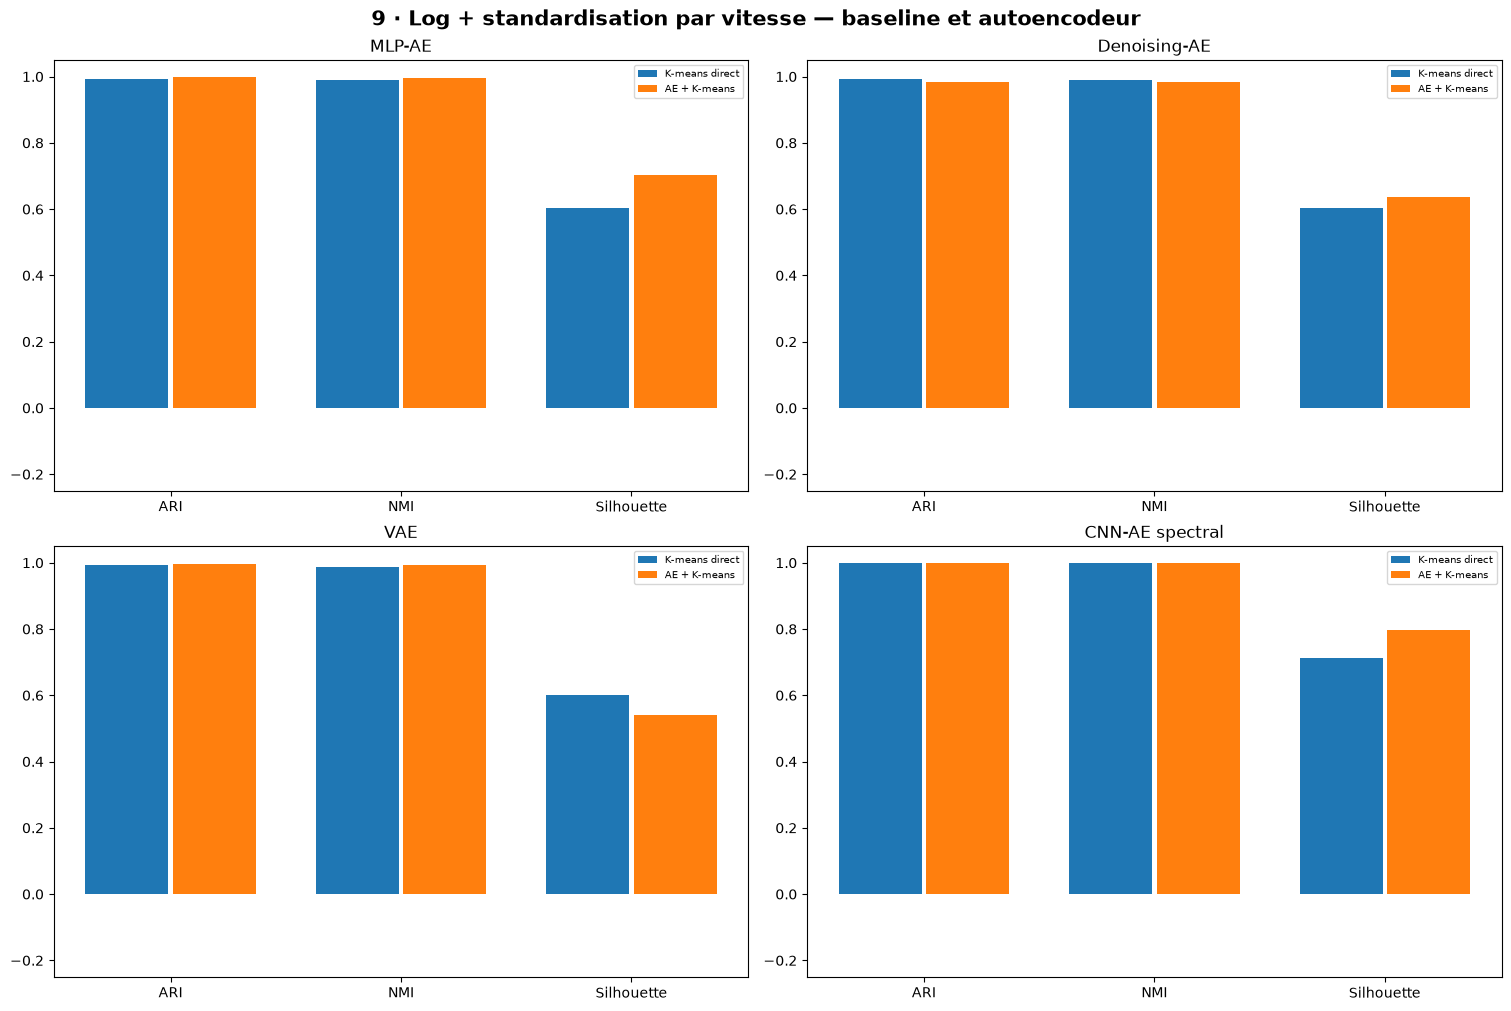

In [21]:
display(resultats["clustering"].query("strategie == 'correction_vitesse'")[["famille", "approche", "ari", "nmi", "silhouette_train", "ari_vs_vitesse"]].round(4))
_ = comparaison_baseline(resultats, "correction_vitesse")

### Figure de synthèse A — effet de la correction de vitesse

La figure suivante compare **uniquement K-means sur les codes latents** des quatre familles, à protocole train/test comparable. Elle visualise le saut de performance et évite d'attribuer automatiquement l'amélioration à l'architecture neuronale. *Visualisation réalisée à partir des valeurs du tableau A5/A7 déjà calculées ; aucun entraînement supplémentaire.*

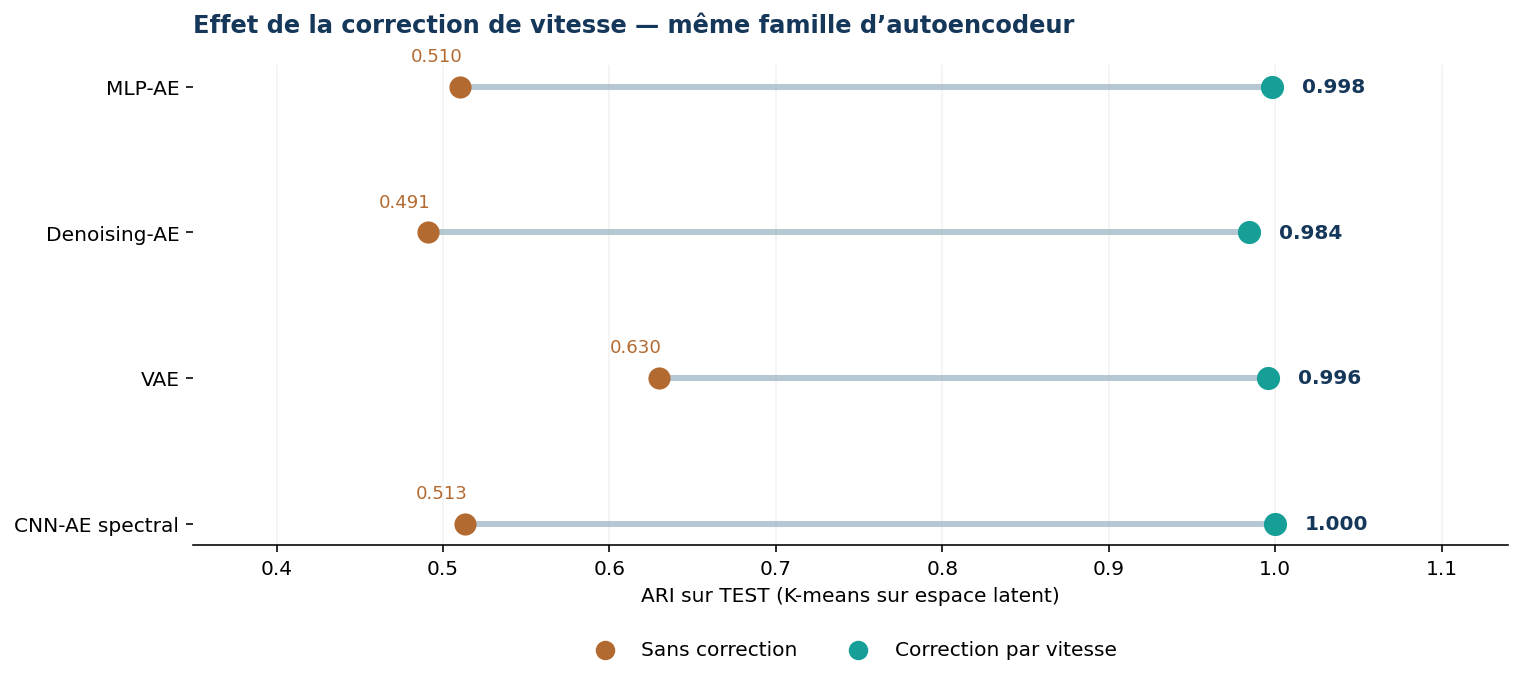

In [ ]:
# Visualisation complémentaire : mêmes valeurs que les tableaux de l'étude A.
_fams = ['MLP-AE','Denoising-AE','VAE','CNN-AE spectral']
_df = resultats['clustering']
_fig,_ax=plt.subplots(figsize=(10.6,4.9))
for _i,_f in enumerate(_fams):
    _sub=_df[(_df.famille==_f)&(_df.approche=='autoencodeur')&( _df.vitesse_modele.astype(str)=='toutes')]
    _a=float(_sub.loc[_sub.strategie=='sans_correction','ari'].iloc[0])
    _b=float(_sub.loc[_sub.strategie=='correction_vitesse','ari'].iloc[0])
    _ax.plot([_a,_b],[_i,_i],lw=3,color='#b6c8d4',zorder=1)
    _ax.scatter(_a,_i,s=100,color='#b36a30',zorder=2)
    _ax.scatter(_b,_i,s=110,color='#159f96',zorder=2)
    _ax.text(_a-.014,_i-.21,f'{_a:.3f}',ha='center',va='center',fontsize=9,color='#b36a30')
    _ax.text(min(_b+.018,1.10),_i,f'{_b:.3f}',va='center',fontsize=10,color='#15375a',fontweight='bold')
_ax.set_yticks(range(len(_fams)),_fams);_ax.invert_yaxis();_ax.set_xlim(.35,1.14)
_ax.set_xlabel('ARI sur TEST (K-means sur espace latent)')
_ax.set_title('Effet de la correction de vitesse — même famille d’autoencodeur',loc='left',fontweight='bold',color='#15375a',pad=16)
_ax.grid(axis='x',alpha=.17);_ax.spines[['top','right','left']].set_visible(False)
_ax.scatter([],[],s=75,color='#b36a30',label='Sans correction')
_ax.scatter([],[],s=75,color='#159f96',label='Correction par vitesse')
_ax.legend(loc='upper center',frameon=False,ncol=2,bbox_to_anchor=(0.5,-0.16))
plt.tight_layout();plt.show()

### 7.1 Coude, silhouette, projections et matrices côte à côte

Ces visuels permettent d'observer si les quinze conditions classe × vitesse se regroupent en cinq états après correction.

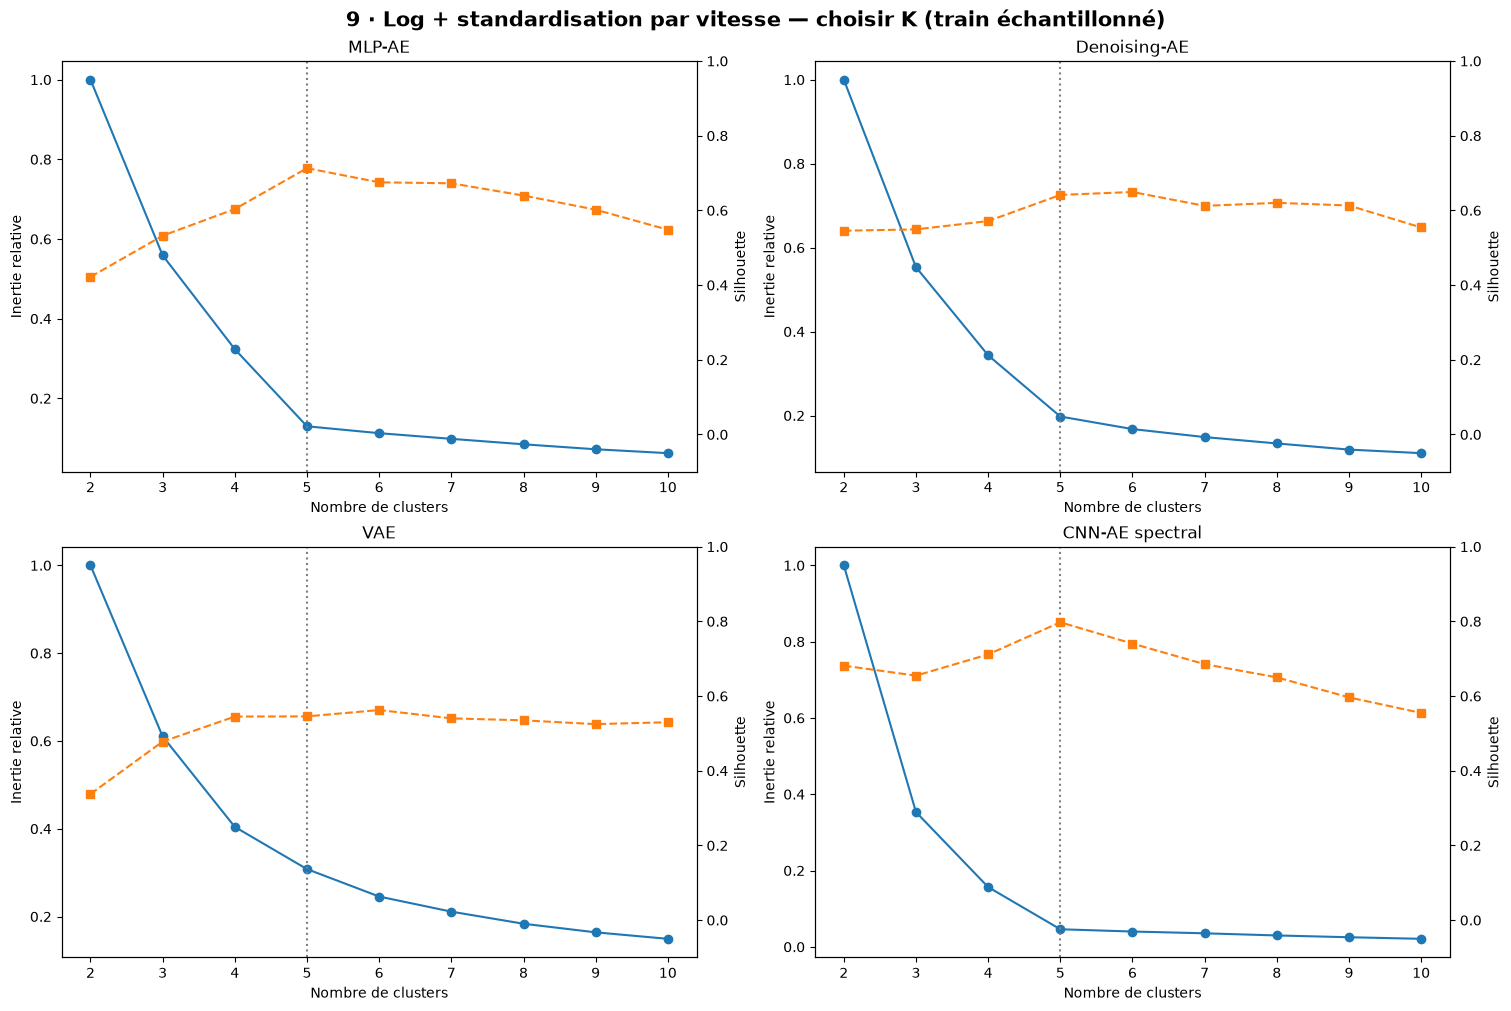

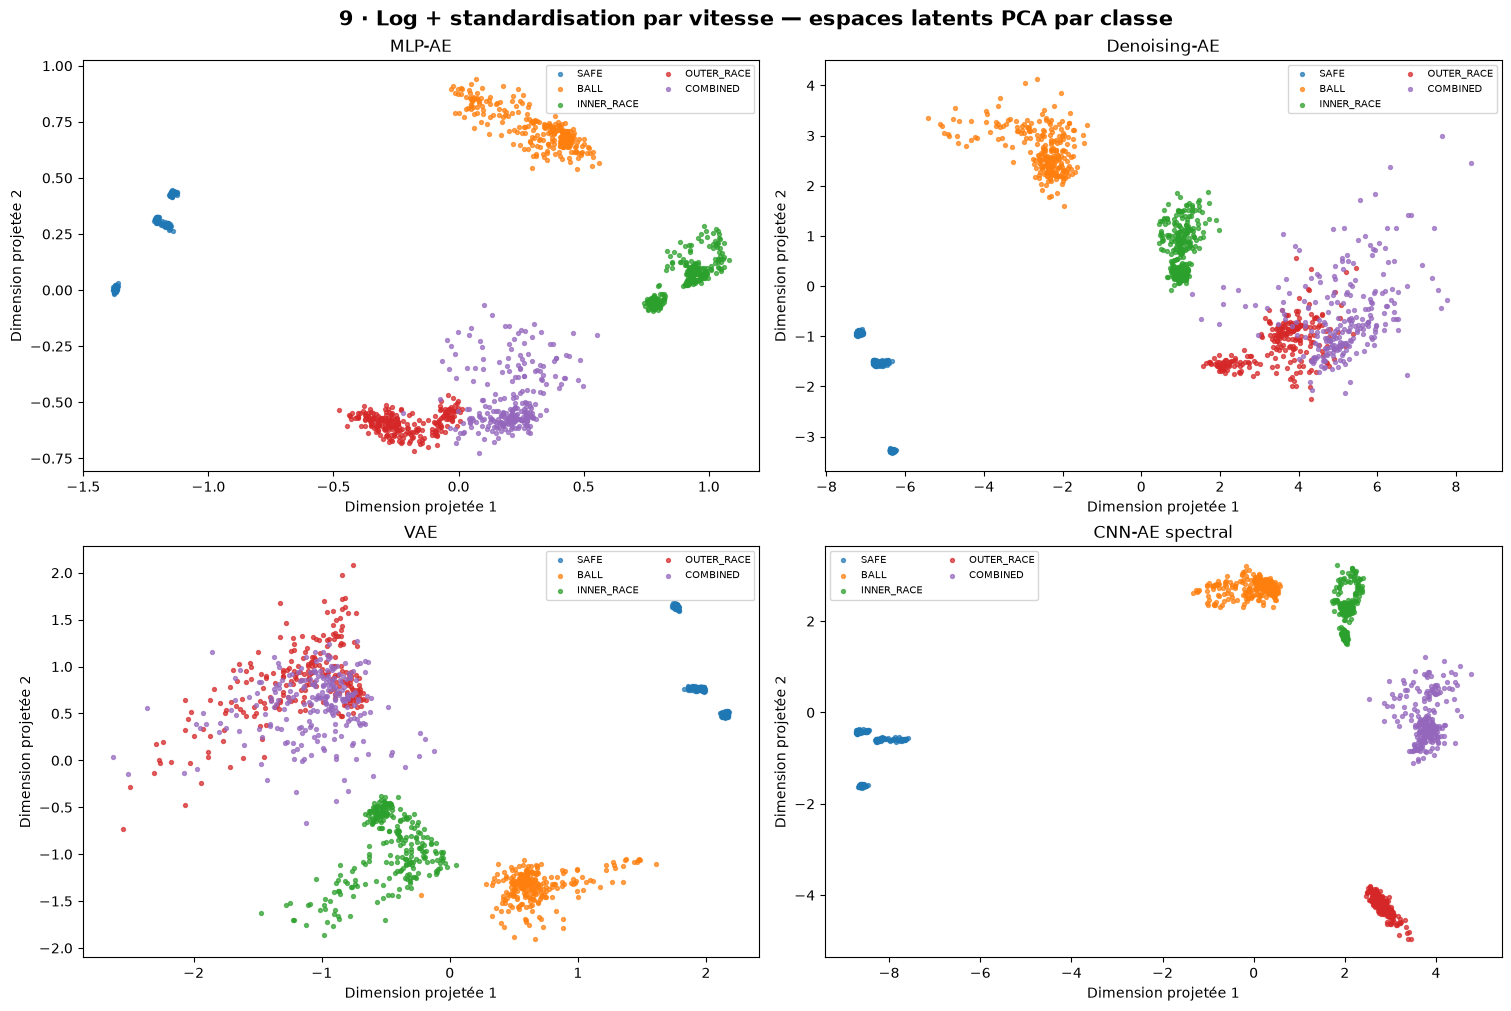

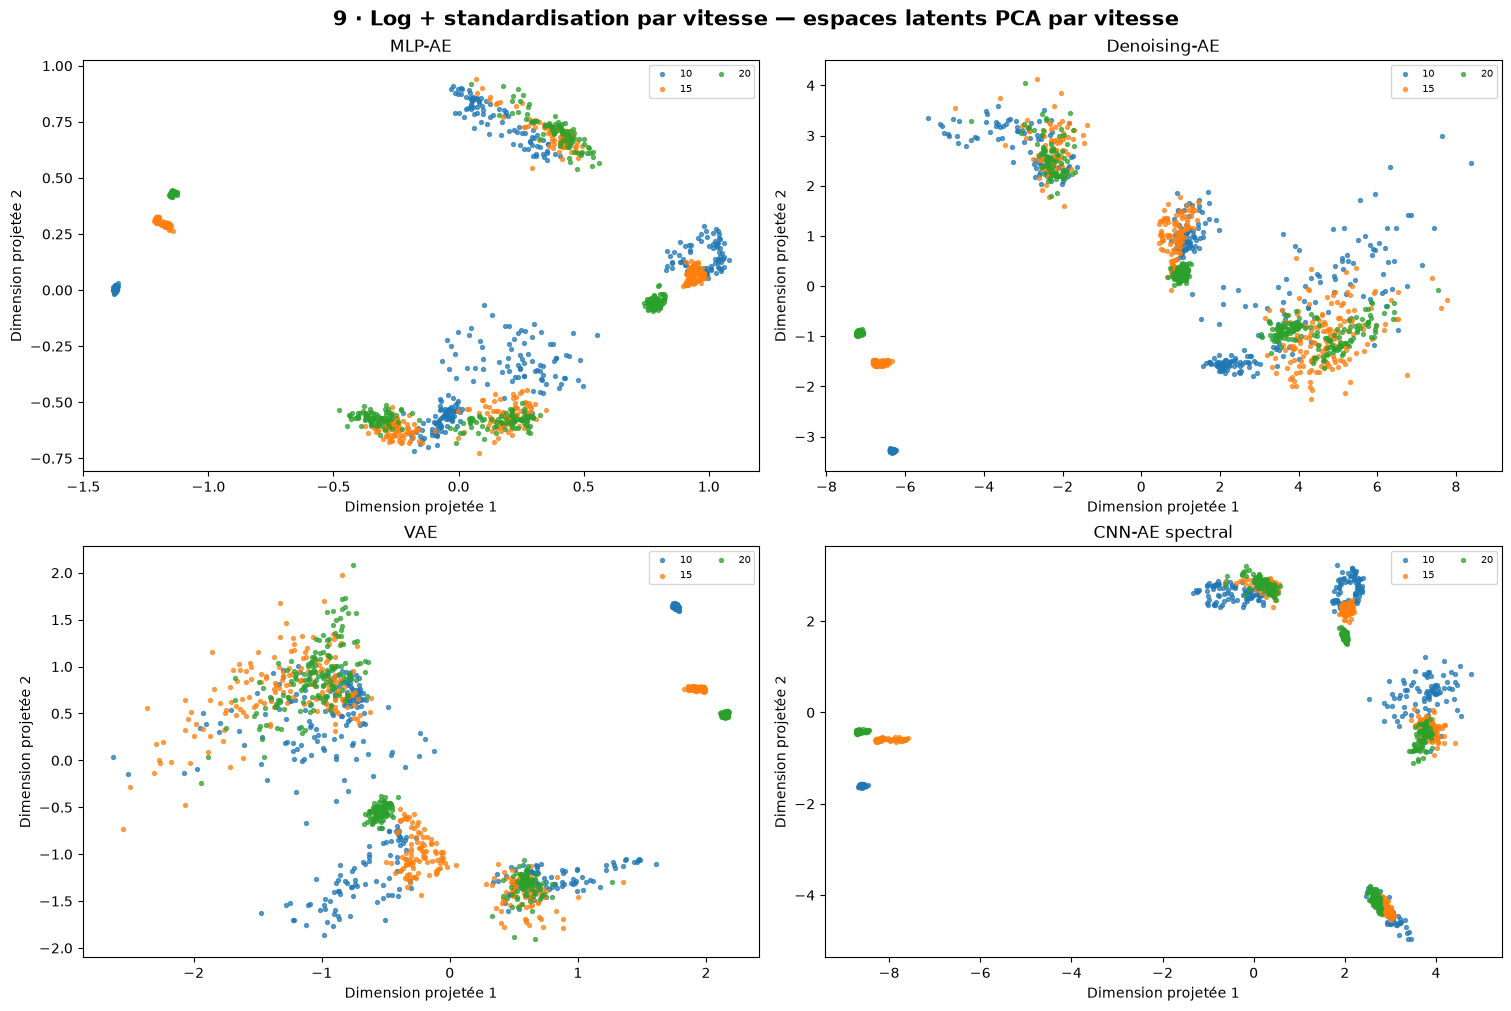

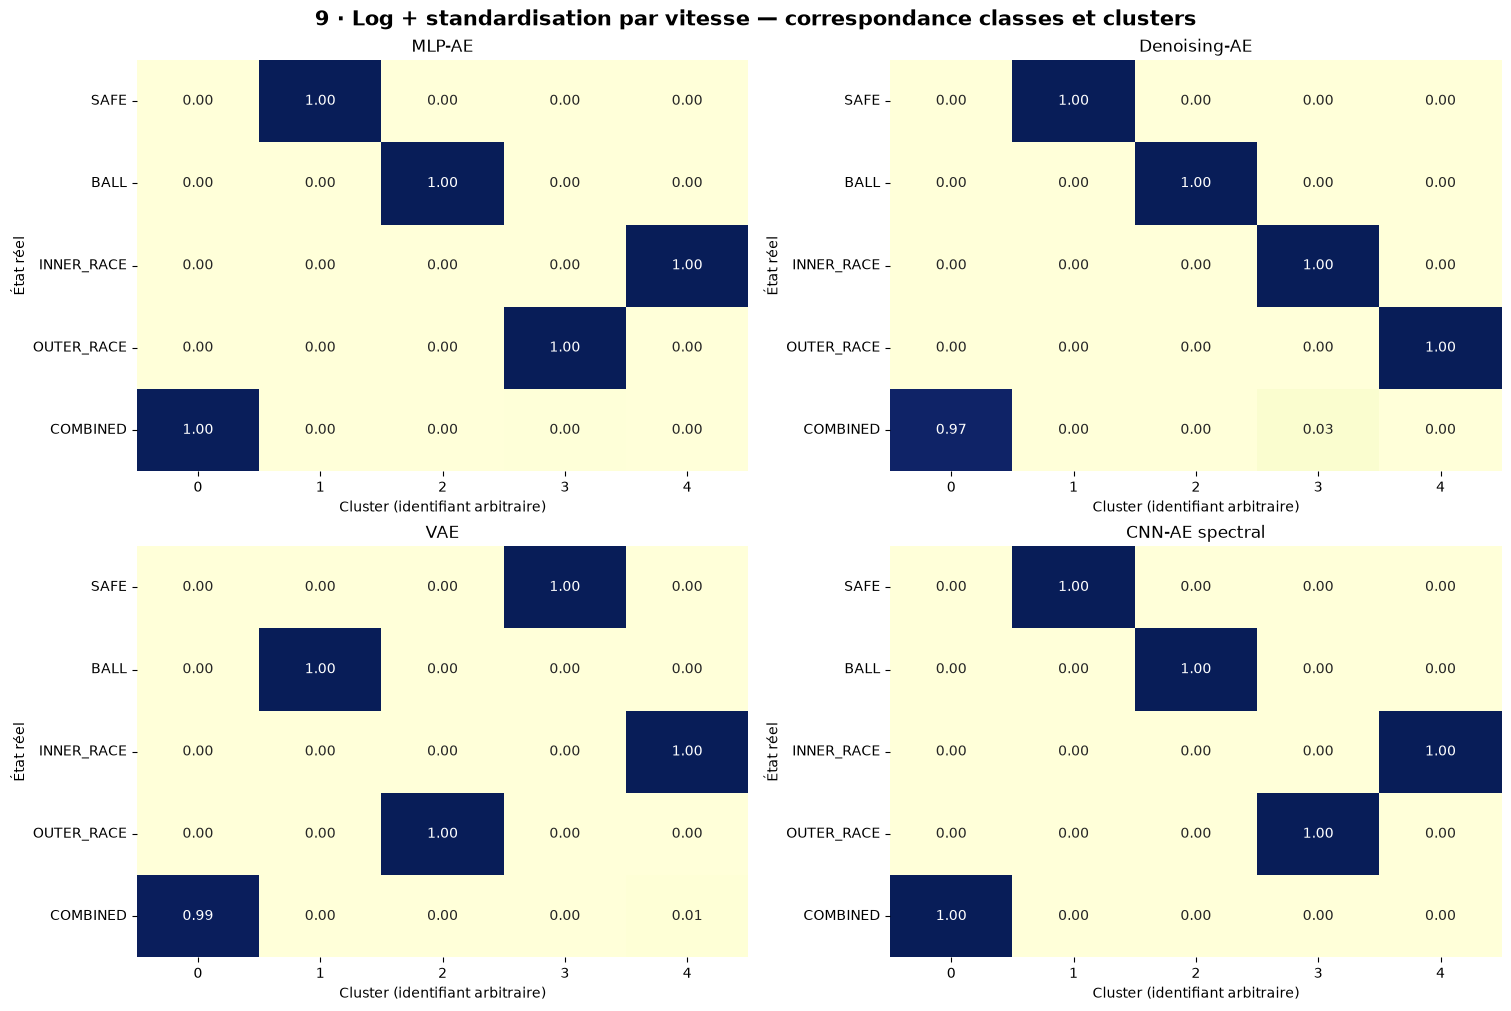

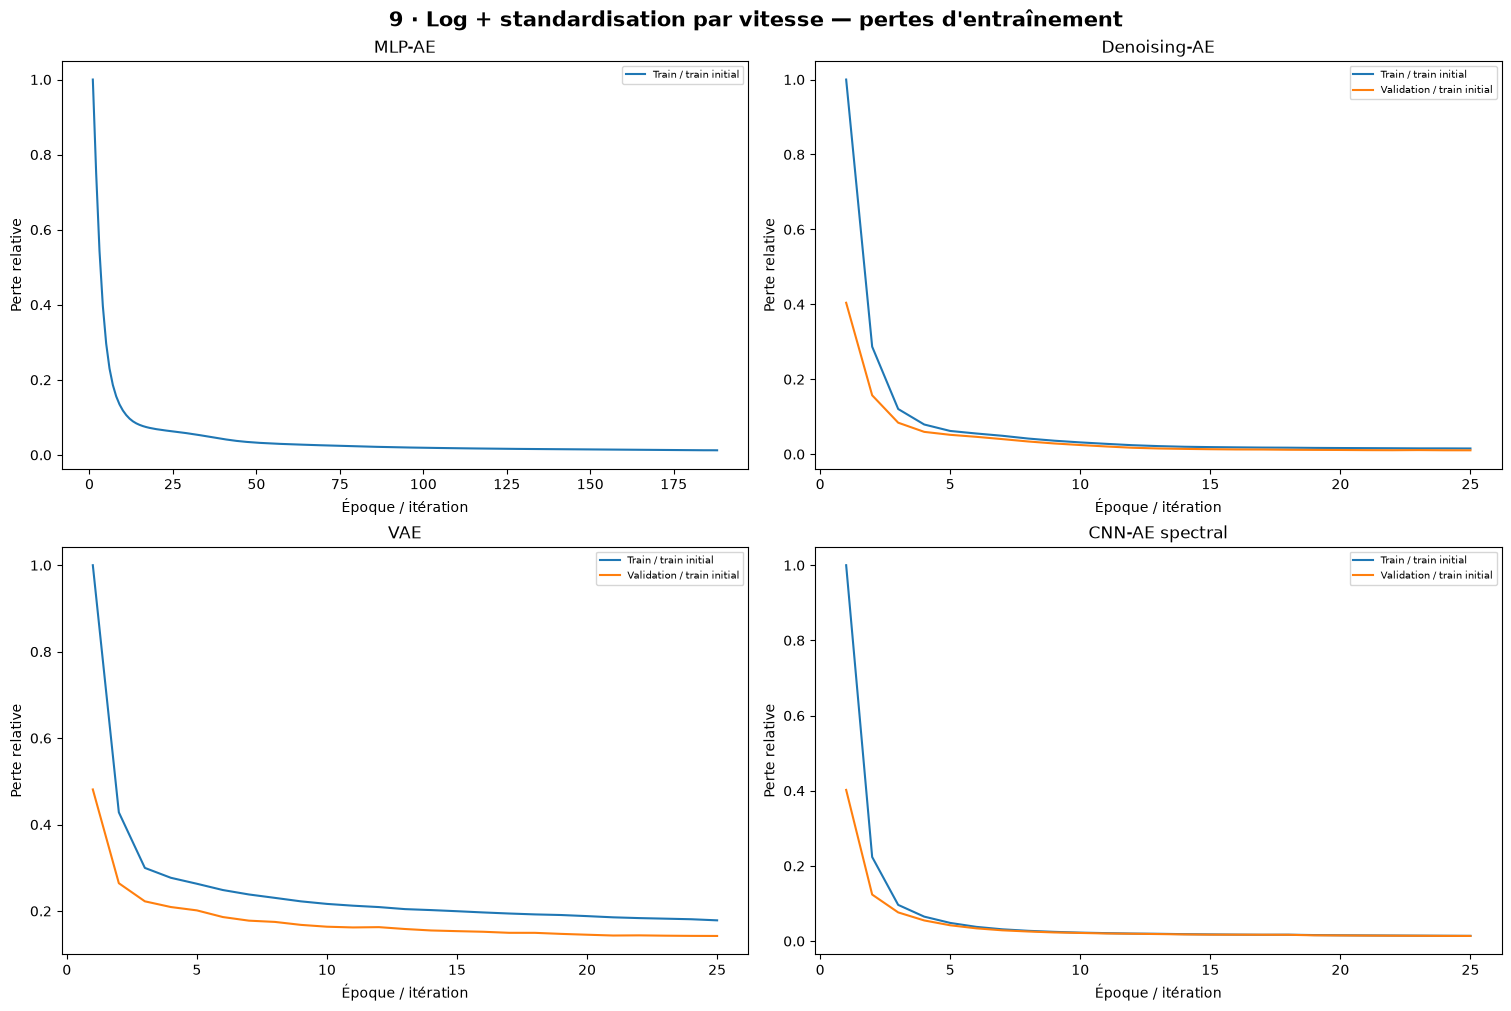

In [22]:
if AFFICHER_CHOIX_K:
    _ = choix_k(resultats, "correction_vitesse")
_ = vues_latentes(resultats, "correction_vitesse", colorer="classe")
_ = vues_latentes(resultats, "correction_vitesse", colorer="vitesse")
_ = tableaux_clustering(resultats, "correction_vitesse")
_ = courbes_apprentissage(resultats, "correction_vitesse")

## 8. Bilan des trois stratégies (V4, section 10)

Comparaison ARI et NMI sur le test : sans correction ; une architecture indépendante à chaque vitesse (moyenne des trois scores) ; correction de vitesse avec modèle unique. **Ne pas comparer des identifiants de clusters venant d'espaces distincts.**

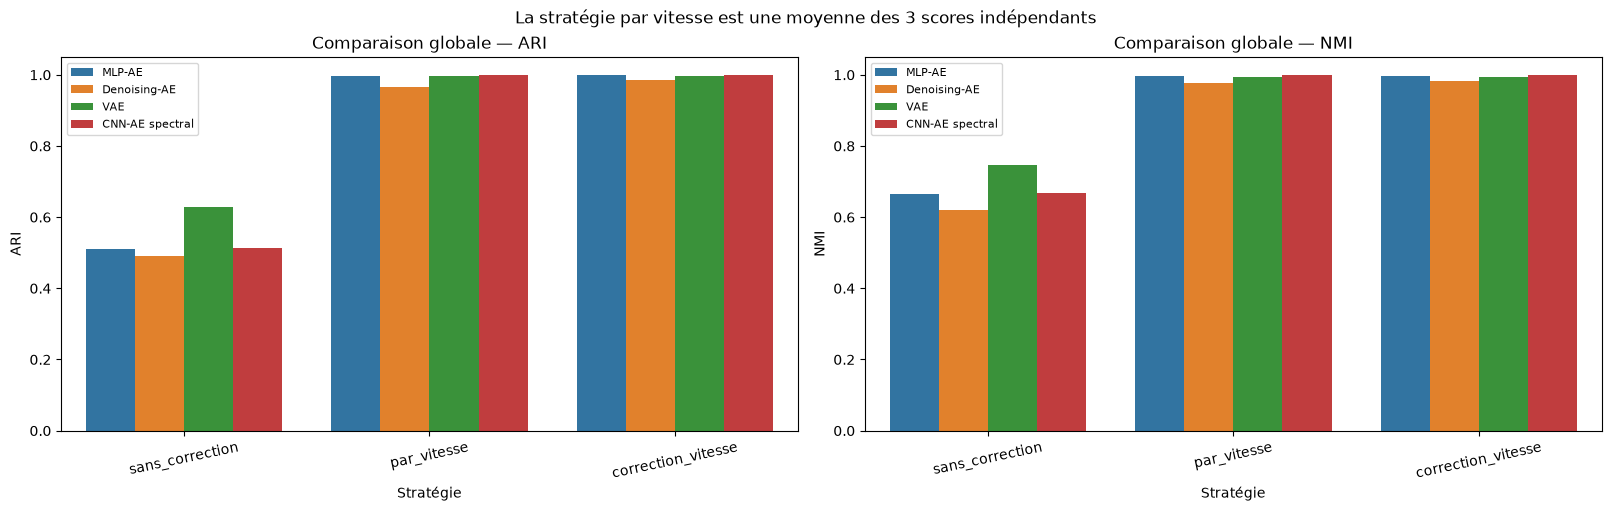

,famille,strategie,ari,nmi
7,CNN-AE spectral,correction_vitesse,1.0000,1.0000
8,CNN-AE spectral,par_vitesse,1.0000,1.0000
3,CNN-AE spectral,sans_correction,0.5133,0.6687
5,Denoising-AE,correction_vitesse,0.9842,0.9824
9,Denoising-AE,par_vitesse,0.9666,0.9769
1,Denoising-AE,sans_correction,0.4911,0.6198
4,MLP-AE,correction_vitesse,0.9981,0.9968
10,MLP-AE,par_vitesse,0.9980,0.9972
0,MLP-AE,sans_correction,0.5101,0.6657
6,VAE,correction_vitesse,0.9960,0.9942


In [23]:
bilan, _ = bilan_methodologique(resultats)
display(bilan[["famille", "strategie", "ari", "nmi"]].sort_values(["famille", "strategie"]).round(4))

## A9. Interprétation de l'étude A — portée des résultats

La correction de vitesse modifie considérablement la séparation des cinq états : **sans correction**, l'ARI de K-means sur les latents va de **0,4911 (Denoising-AE)** à **0,6296 (VAE)** ; **après correction**, il atteint **0,9842 à 1,0000** selon la famille. Les représentations PCA deviennent plus nettement séparées et l'association résiduelle des clusters à la vitesse (`ari_vs_vitesse`) se rapproche de zéro. Ce constat vaut pour les **vitesses déjà représentées en TRAIN**.

Avec une correction de vitesse et un modèle global, le **CNN-AE spectral + K-means** obtient **ARI = 1,0000**, **NMI = 1,0000**, silhouette TRAIN ≈ **0,7970**. Le MLP-AE + K-means atteint **ARI = 0,9981** ; VAE **0,9960** ; Denoising-AE **0,9842**. Les quatre AE détectent tous les défauts du TEST au seuil de validation retenu, mais leur taux de fausses alarmes varie.

**Conclusion partielle :** CNN-AE est un **candidat prioritaire pour le clustering** de cette représentation spectrale, pas une preuve de supériorité intrinsèque de l'architecture convolutive. Il utilise 512 coefficients, contre 26 descripteurs pour les AE denses. Il faut ensuite examiner la contribution propre du clustering (B) et l'absence possible de nécessité d'un AE (C). Les séries physiques ne sont pas garantis indépendantes entre splits ; les résultats restent exploratoires.

## 10. Figures complémentaires (facultatives)

Les t-SNE donnent une vue non linéaire de l'espace latent ; leur résultat dépend de leurs paramètres, ce qui ne remplace pas les métriques de clustering.

In [24]:
FAIRE_TSNE = False
if FAIRE_TSNE:
    _ = vues_latentes(resultats, "sans_correction", colorer="classe", projection="t-SNE")
    _ = vues_latentes(resultats, "correction_vitesse", colorer="classe", projection="t-SNE")
else:
    print("t-SNE désactivé ; PCA et tableaux disponibles ci-dessus.")

t-SNE désactivé ; PCA et tableaux disponibles ci-dessus.


---
# Étude B — K-means, GMM et BIRCH sur les mêmes représentations latentes

Les **60 évaluations** B ont été produites et archivées à partir des sorties de l'étude A, dans le pipeline autonome. À entrée latente identique pour une famille et une stratégie données, on isole l'effet de l'algorithme de clustering ; aucun AE supplémentaire n'est entraîné dans cette étape.

## B0. Problématique et comparabilité

**Question :** un changement d'algorithme de clustering améliore-t-il la séparation des cinq états pour une même représentation latente ?

Les codes latents sont ceux entraînés en A ; les algorithmes K-means, GMM et BIRCH reçoivent les **mêmes codes** dans chaque configuration. Les paramètres GMM sont choisis par BIC sur le TRAIN, ceux de BIRCH par silhouette TRAIN. Les **60 comparaisons sont déjà exécutées** dans ce notebook, avec leurs métriques et figures.

**Limitation :** les scores TEST ont déjà été consultés au cours des itérations du projet et les séries physiques ne sont pas confirmées indépendantes. Ces résultats servent à sélectionner des hypothèses à vérifier, pas à annoncer une performance industrielle.

## B0.1 Résultats chargés automatiquement

Les 20 configurations latentes de A (quatre familles × [sans correction, un modèle par vitesse, correction de vitesse]) sont comparées avec trois algorithmes, soit **60 évaluations**. Le pipeline autonome a déjà produit/rechargé les résultats dans `results_v6_autonome/etude_b/`.

**Aucune commande externe n'est requise.** Lors d'une exécution neuve depuis les données, le pipeline réalise A puis B avant l'affichage ; à la réouverture du présent livrable les figures sont déjà intégrées.

**Choix sans optimisation sur les étiquettes TEST :** K-means K=5 connu du banc ; GMM sélectionné par BIC TRAIN ; BIRCH réglé par silhouette TRAIN. Le nombre de classes connu est une hypothèse a priori du protocole.

In [25]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from scripts.figures_clustering_algorithmes_v5 import (
    charger, panneaux_scores, matrice_performances,
    correspondance_classes, espaces_latents_cote_a_cote,
    comparaison_strategies, analyse_par_vitesse,
    accord_algorithmes, comparer_baseline_directe,
)
SOURCE_LATENTS = SORTIES_A
RESULTATS_ALGORITHMES = SORTIES_B
res = charger(RESULTATS_ALGORITHMES, SOURCE_LATENTS)
print("Protocole :", res["protocole"]["n_experiences"], "évaluations ;",
      len(res["predictions"]), "attributions de clusters sur le test")
print("Algorithmes :", ", ".join(res["protocole"]["algorithmes"]))

Protocole : 60 évaluations ; 45540 attributions de clusters sur le test
Algorithmes : K-means, GMM, BIRCH


## 1. Les algorithmes et les critères de comparaison

| Algorithme | Fonctionnement | Paramétrage retenu |
|---|---|---|
| **K-means** | Partition en groupes autour de cinq centroïdes | K=5, `n_init=10`, graine 42 |
| **GMM** | Mélange de cinq distributions gaussiennes | Type de covariance choisi par BIC sur le train |
| **BIRCH** | Construction d'une structure de sous-clusters, puis cinq groupes | Seuil choisi par silhouette du train |

**Indicateurs :** ARI/NMI sur les acquisitions de test, silhouette sur un sous-échantillon du train, et coût d'ajustement. ARI et NMI comparent les groupes prédits aux cinq états connus, sans utiliser les étiquettes pendant le clustering.

Le nombre **K=5** est fixé à partir des cinq états du banc d'essai : cette connaissance a priori doit être déclarée. Les trois algorithmes reçoivent **les mêmes codes latents**, sans transformation supplémentaire. K-means étant déjà proche de l'ARI maximal, un nouvel algorithme ne peut guère gagner sur le même test ; la stabilité et la forme des partitions sont aussi importantes.

In [26]:
display(res["scores"][["strategie", "vitesse_modele", "famille", "algorithme",
                       "ari", "nmi", "silhouette_train", "choix_parametre"]].head(12).round(4))
print("Recherche d'hyperparamètres effectuée exclusivement sur le train :",
      len(res["recherche"]), "candidats évalués")

,strategie,vitesse_modele,famille,algorithme,ari,nmi,silhouette_train,choix_parametre
0,sans_correction,toutes,MLP-AE,K-means,0.5101,0.6657,0.5175,"K=5, graine du protocole V5"
1,sans_correction,toutes,MLP-AE,GMM,0.5230,0.6689,0.4834,covariance=full; composants=5
2,sans_correction,toutes,MLP-AE,BIRCH,0.4487,0.6733,0.5591,threshold=0.100148; sous_clusters=112
3,sans_correction,toutes,Denoising-AE,K-means,0.4911,0.6198,0.4777,"K=5, graine du protocole V5"
4,sans_correction,toutes,Denoising-AE,GMM,0.4921,0.6462,0.4803,covariance=full; composants=5
5,sans_correction,toutes,Denoising-AE,BIRCH,0.1426,0.2460,0.3997,threshold=0.340995; sous_clusters=610
6,sans_correction,toutes,VAE,K-means,0.6296,0.7453,0.4701,"K=5, graine du protocole V5"
7,sans_correction,toutes,VAE,GMM,0.7196,0.8639,0.5182,covariance=full; composants=5
8,sans_correction,toutes,VAE,BIRCH,0.0013,0.0297,0.4836,threshold=0.869858; sous_clusters=38
9,sans_correction,toutes,CNN-AE spectral,K-means,0.5133,0.6687,0.5319,"K=5, graine du protocole V5"


Recherche d'hyperparamètres effectuée exclusivement sur le train : 160 candidats évalués


## 2. Étape 1 — Clustering sans correction de vitesse

À partir des espaces latents sans correction, comparaison côte à côte des trois algorithmes pour les quatre familles d'autoencodeurs. Les représentations et le test sont identiques pour les trois algorithmes d'une même ligne.

algorithme,K-means,GMM,BIRCH
famille,,,
MLP-AE,0.5101,0.5230,0.4487
Denoising-AE,0.4911,0.4921,0.1426
VAE,0.6296,0.7196,0.0013
CNN-AE spectral,0.5133,0.5995,0.5568


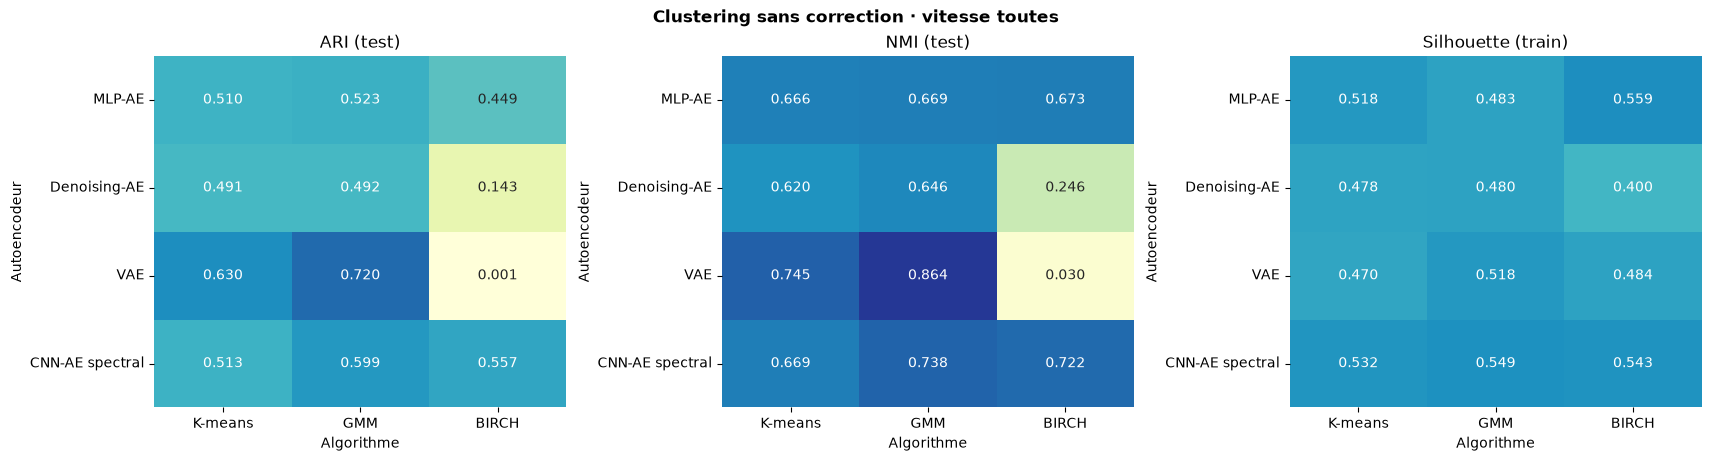

In [27]:
display(matrice_performances(res, "sans_correction").round(4))
_ = panneaux_scores(res, "sans_correction")

### 2.1 Correspondance entre les cinq états réels et les clusters

Chaque matrice est normalisée par classe : une valeur proche de 1 sur une colonne signifie que cette classe est majoritairement regroupée dans ce cluster. Les identifiants de clusters sont arbitraires et ne constituent pas à eux seuls des prédictions de classes.

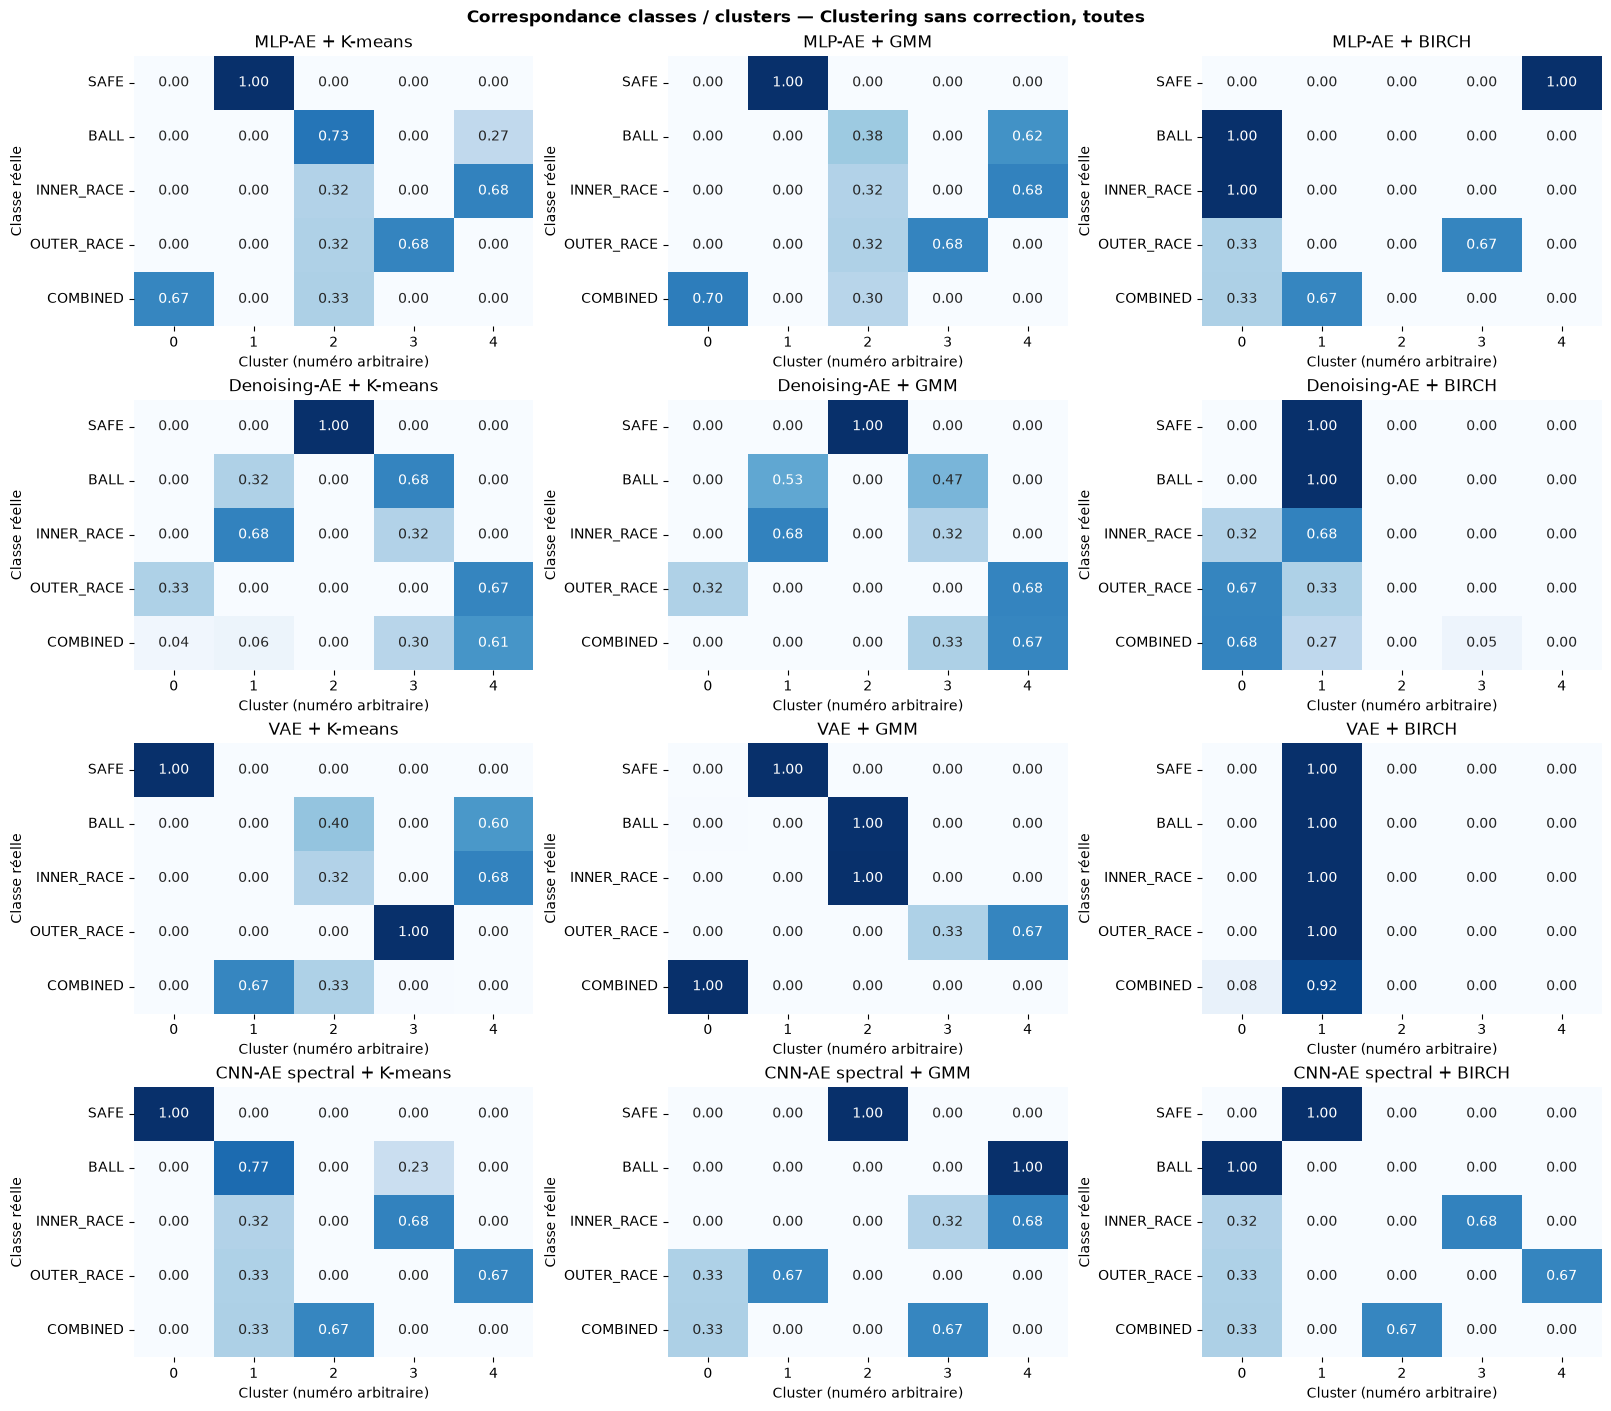

In [28]:
_ = correspondance_classes(res, "sans_correction")

### 2.2 Projections PCA des espaces latents

La projection PCA est apprise sur le **train** de la famille et appliquée au **test**. Les trois panneaux d'une même ligne partagent les coordonnées 2D mais sont colorés selon des partitions différentes. Les couleurs des groupes n'ont pas nécessairement les mêmes significations entre algorithmes.

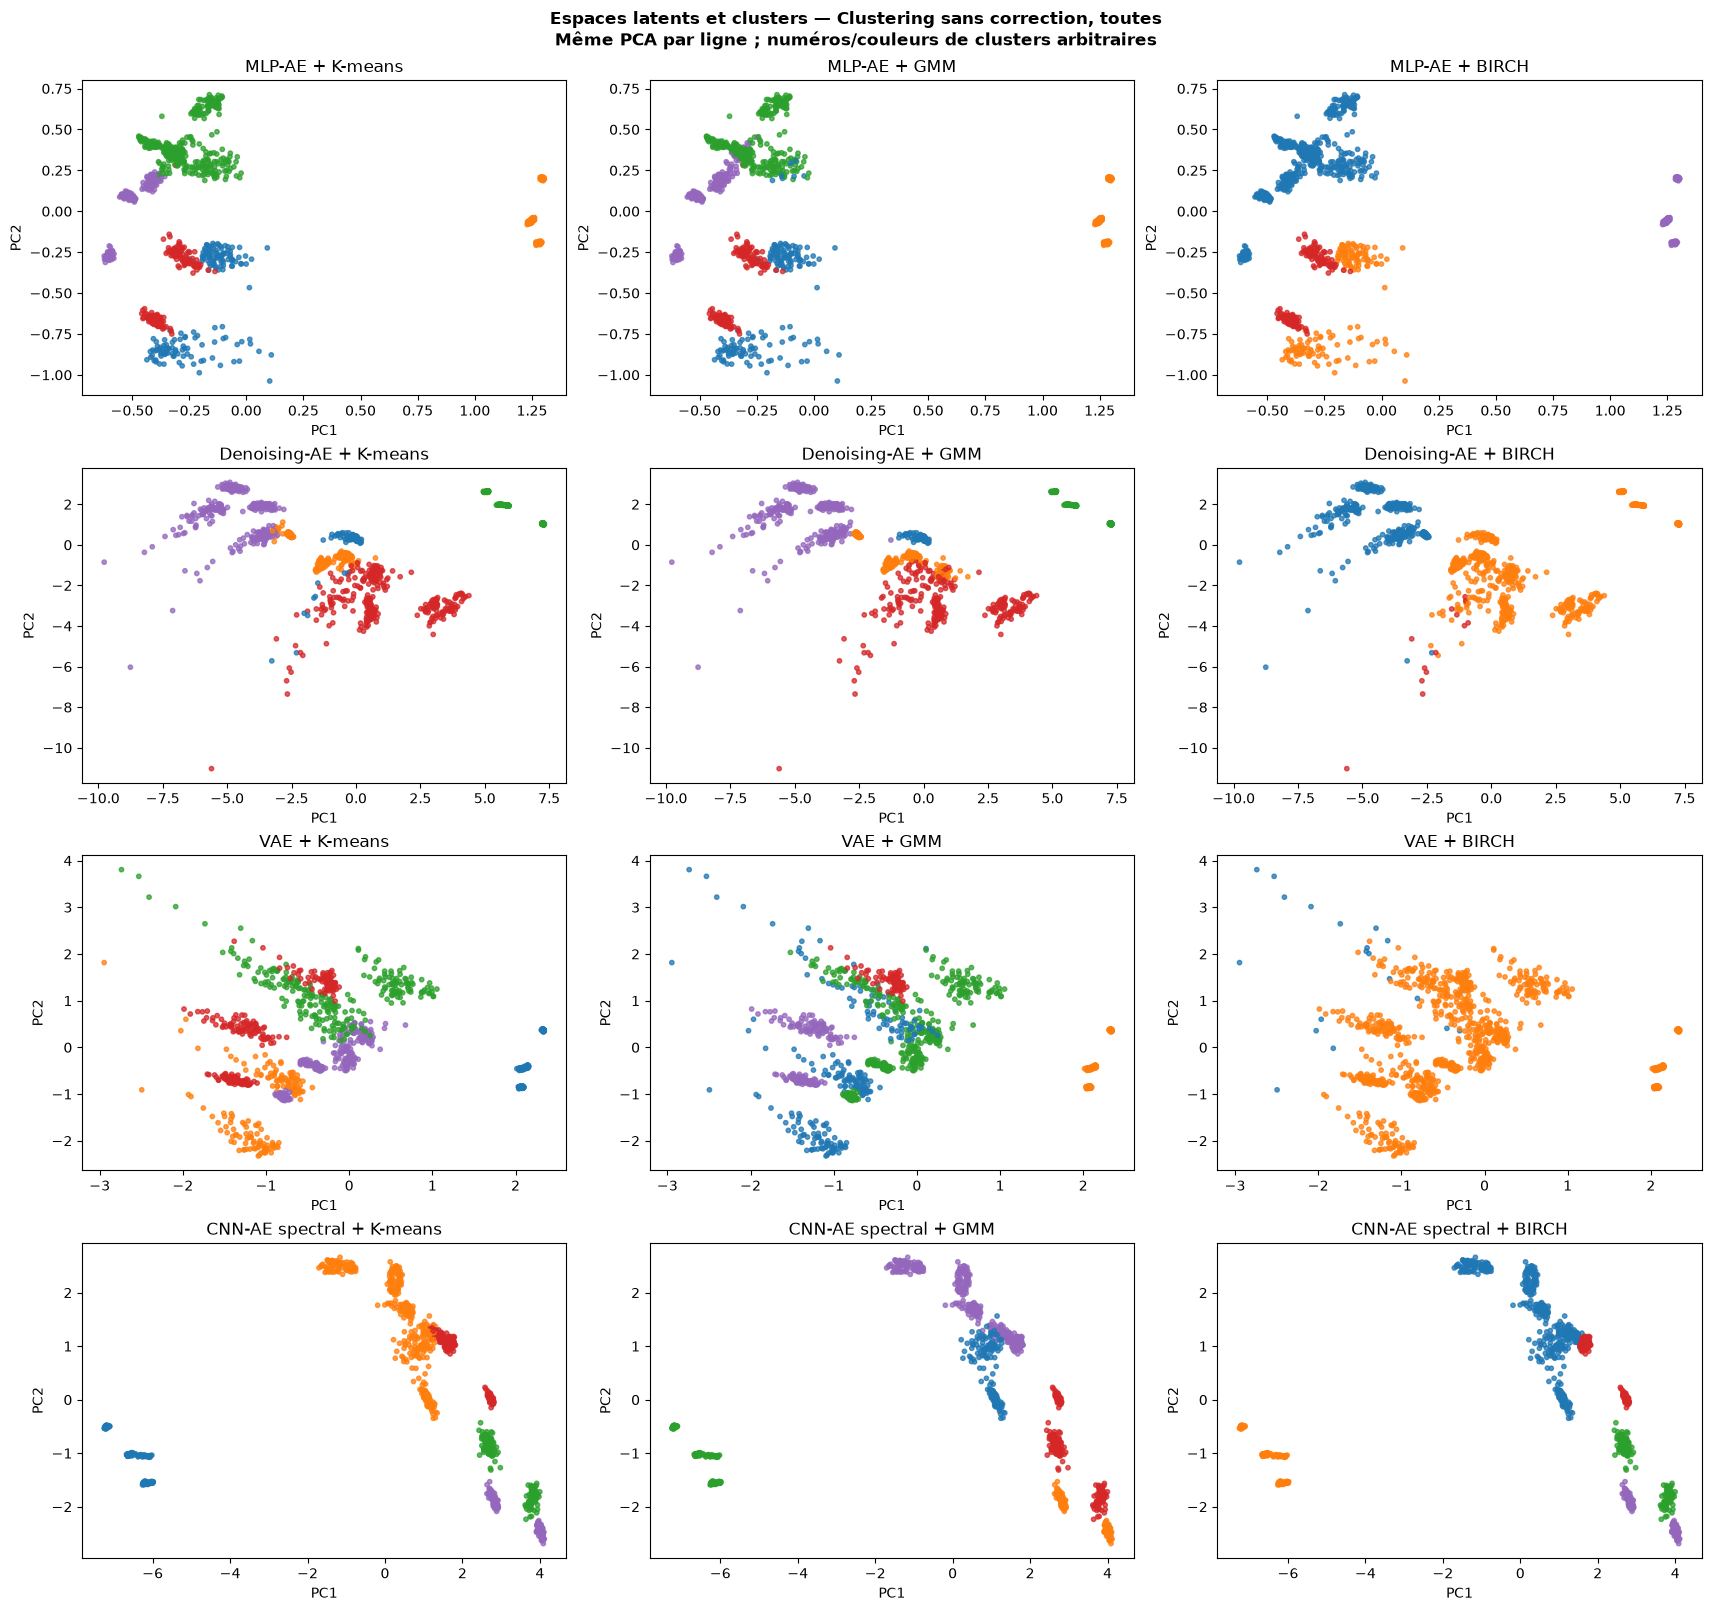

In [29]:
_ = espaces_latents_cote_a_cote(res, "sans_correction")

## 3. Étape 2 — Un modèle distinct pour chaque vitesse

Les représentations latentes proviennent des autoencodeurs spécialisés à 10, 15 et 20. Les algorithmes K-means, GMM et BIRCH sont ensuite ajustés séparément, sur le train de chaque vitesse. On ne mélange **pas** des numéros de clusters provenant de modèles de vitesse distincts.

VITESSE 10 — ARI (test)


algorithme,K-means,GMM,BIRCH
famille,,,
MLP-AE,1.0000,1.0,0.7675
Denoising-AE,0.8999,1.0,0.3115
VAE,0.9875,1.0,0.7847
CNN-AE spectral,1.0000,1.0,1.0000


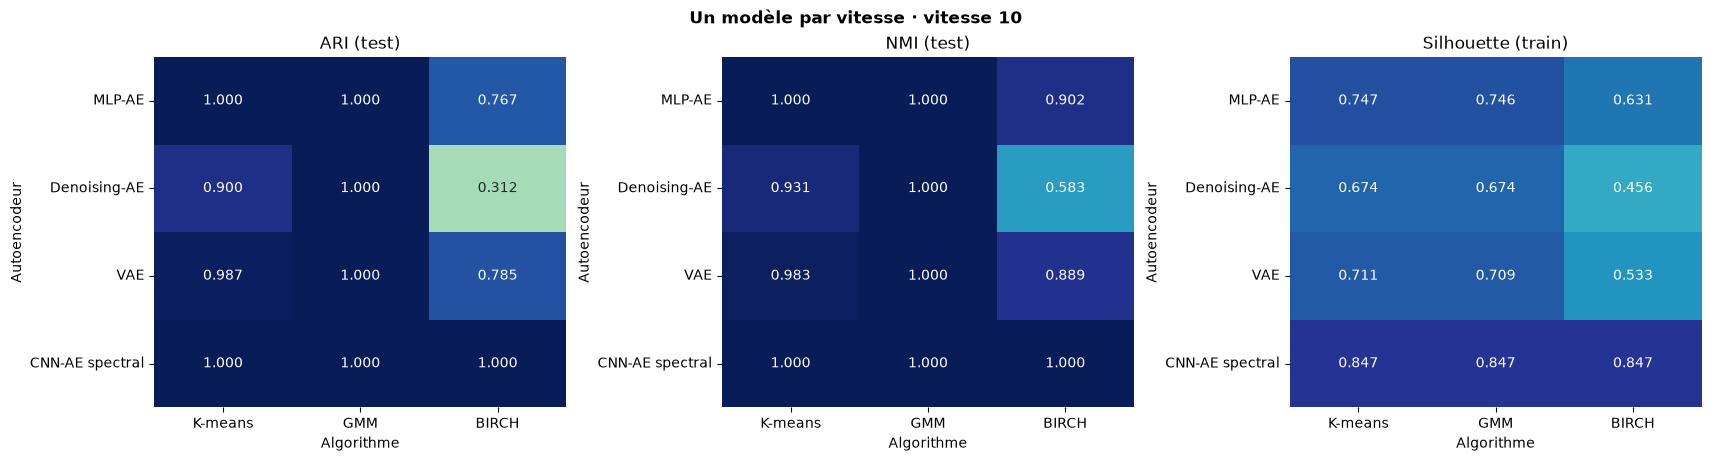

VITESSE 15 — ARI (test)


algorithme,K-means,GMM,BIRCH
famille,,,
MLP-AE,1.0,1.0,0.7772
Denoising-AE,1.0,1.0,0.3508
VAE,1.0,1.0,0.4895
CNN-AE spectral,1.0,1.0,1.0000


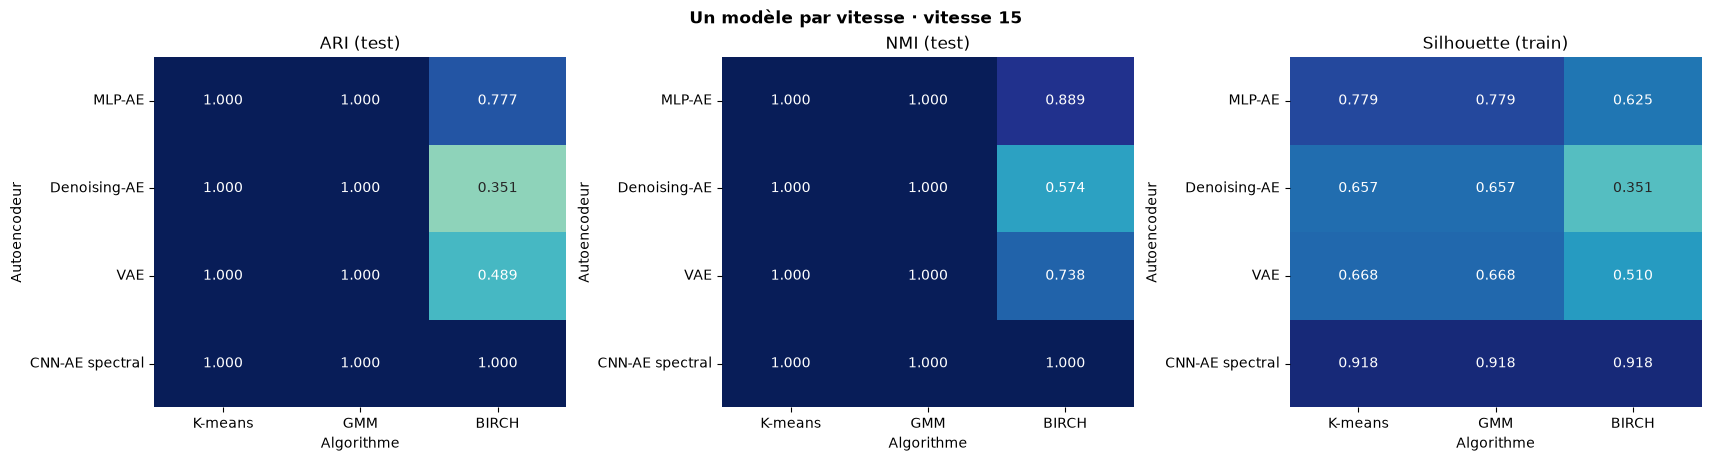

VITESSE 20 — ARI (test)


algorithme,K-means,GMM,BIRCH
famille,,,
MLP-AE,0.994,1.0,0.7653
Denoising-AE,1.000,1.0,0.6095
VAE,1.000,1.0,0.4646
CNN-AE spectral,1.000,1.0,1.0000


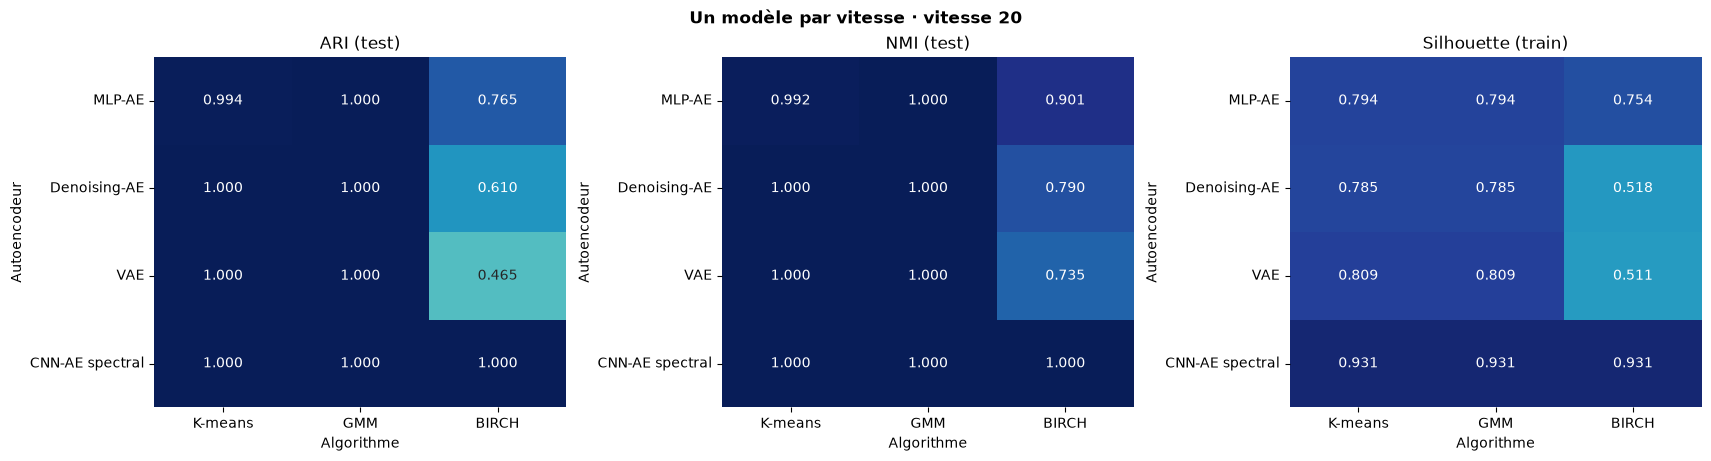

In [30]:
for vitesse in ("10", "15", "20"):
    print(f"VITESSE {vitesse} — ARI (test)")
    display(matrice_performances(res, "par_vitesse", vitesse).round(4))
    _ = panneaux_scores(res, "par_vitesse", vitesse)

### 3.1 Visualiser les clusters à une vitesse donnée

Le panneau ci-dessous illustre la vitesse 15. Pour afficher aussi toutes les matrices et les PCA aux vitesses 10 et 20, activer l'option correspondante. Par défaut, les métriques des trois vitesses sont déjà visibles ci-dessus.

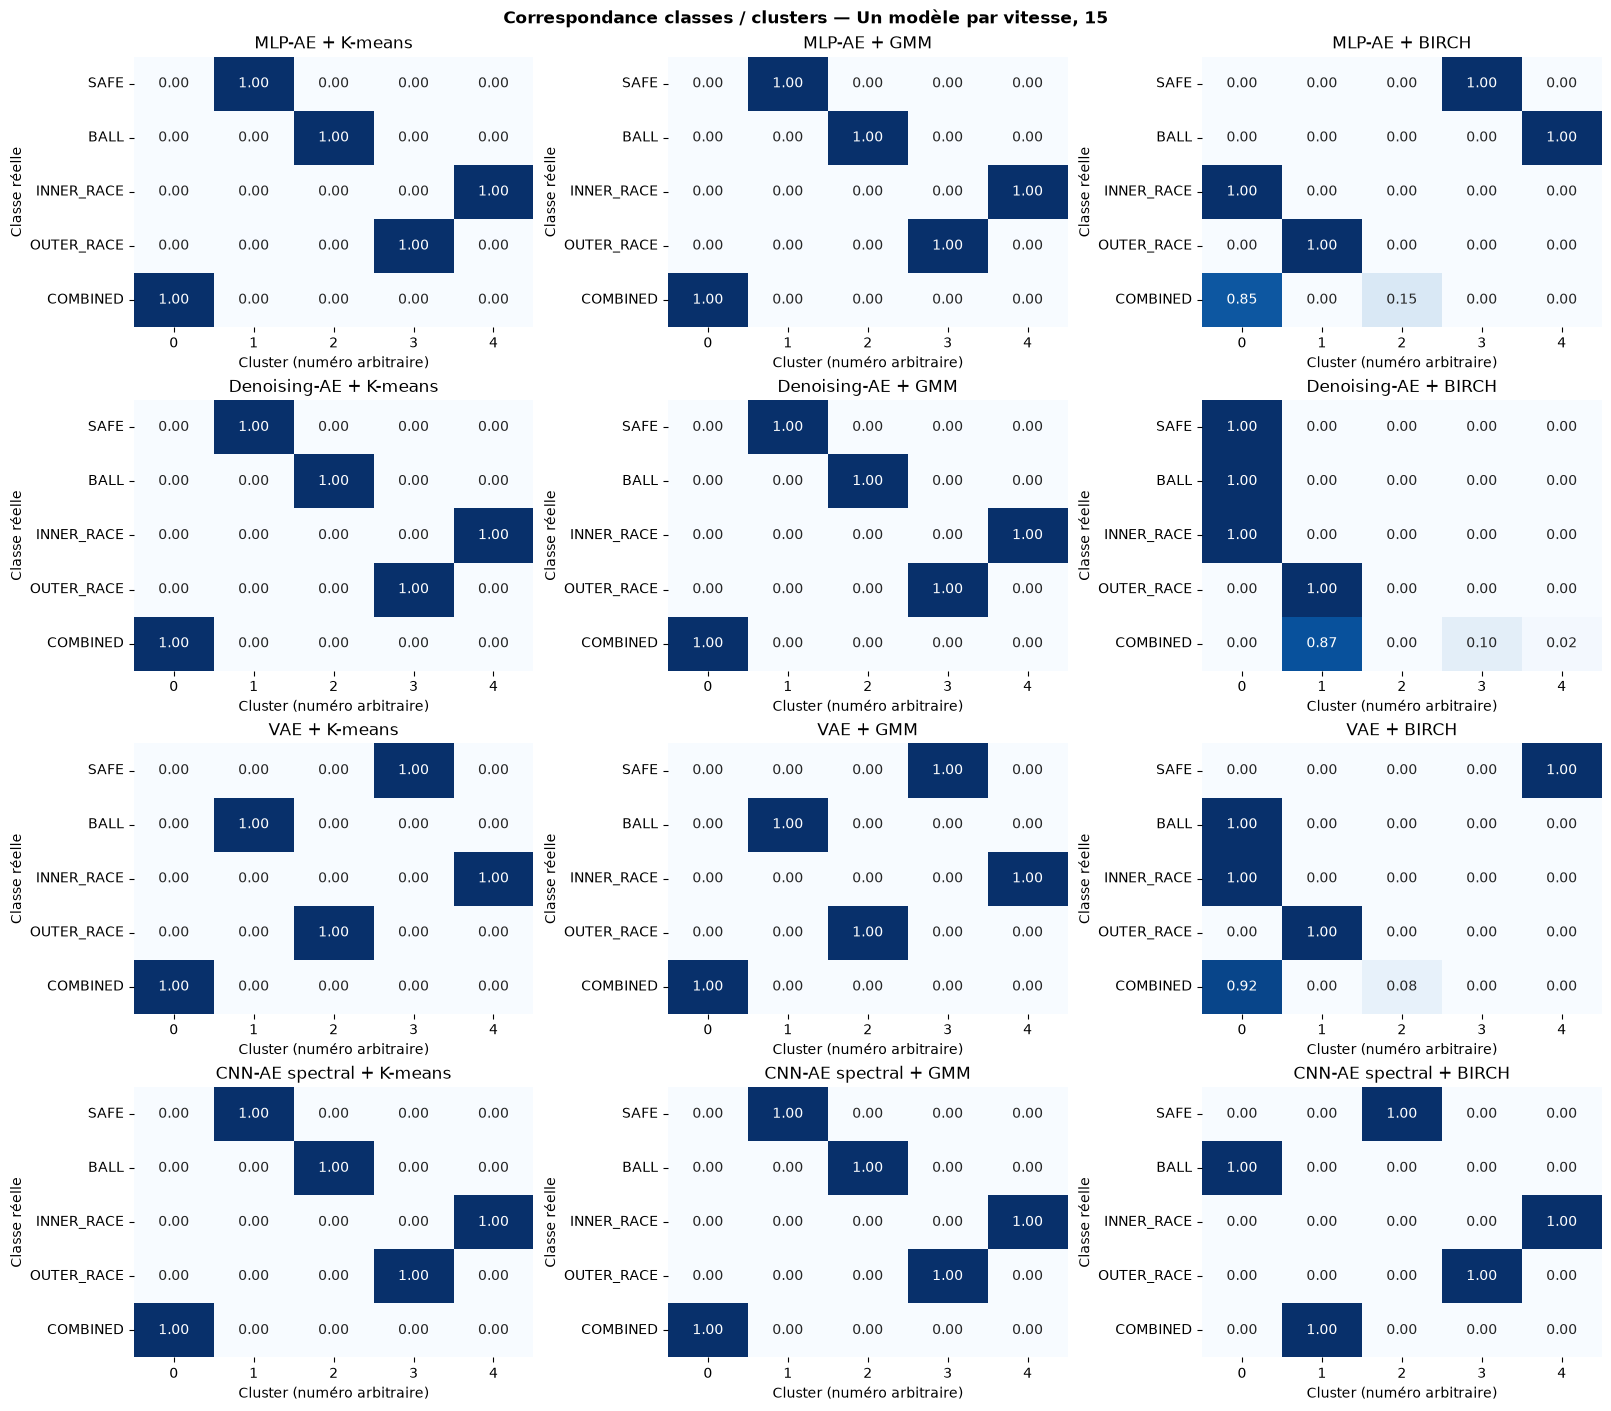

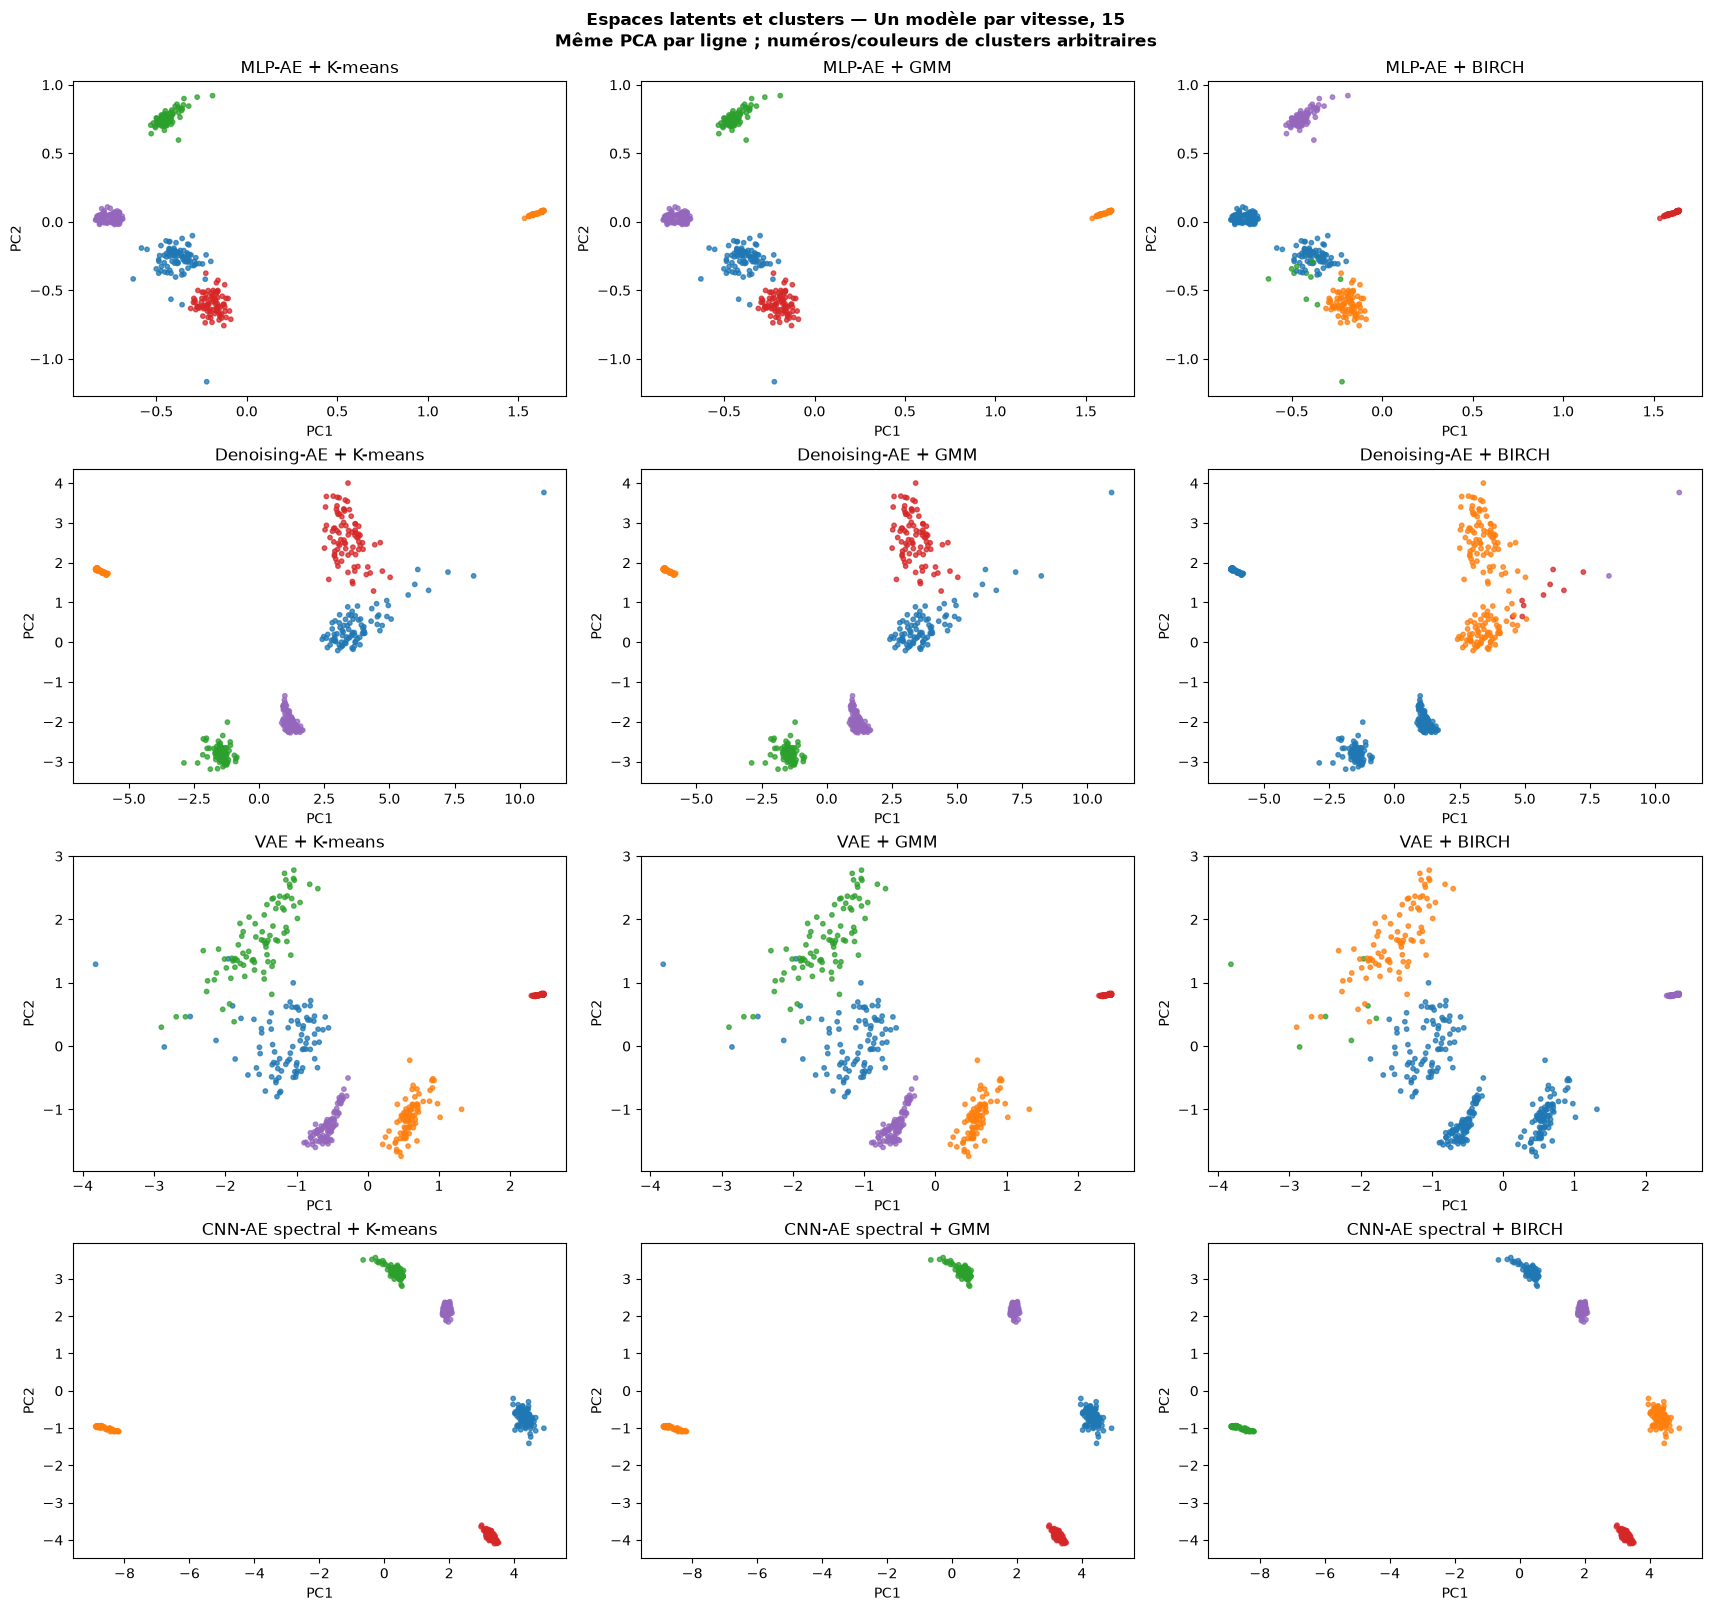

In [31]:
VITESSES_A_AFFICHER_EN_DETAIL = ("15",)   # remplacer par ("10", "15", "20") pour toutes les figures
for vitesse in VITESSES_A_AFFICHER_EN_DETAIL:
    _ = correspondance_classes(res, "par_vitesse", vitesse)
    _ = espaces_latents_cote_a_cote(res, "par_vitesse", vitesse)

## 4. Étape 3 — Modèle commun avec correction de vitesse

Comme dans l’étude A, les AE denses utilisent log + standardisation par vitesse sur les 26 descripteurs, tandis que le CNN reçoit les spectres standardisés par vitesse. **À famille fixée, l'entrée latente est exactement la même pour K-means, GMM et BIRCH.**

algorithme,K-means,GMM,BIRCH
famille,,,
MLP-AE,0.9981,1.0,0.9262
Denoising-AE,0.9842,1.0,0.3766
VAE,0.9960,1.0,0.4611
CNN-AE spectral,1.0000,1.0,1.0000


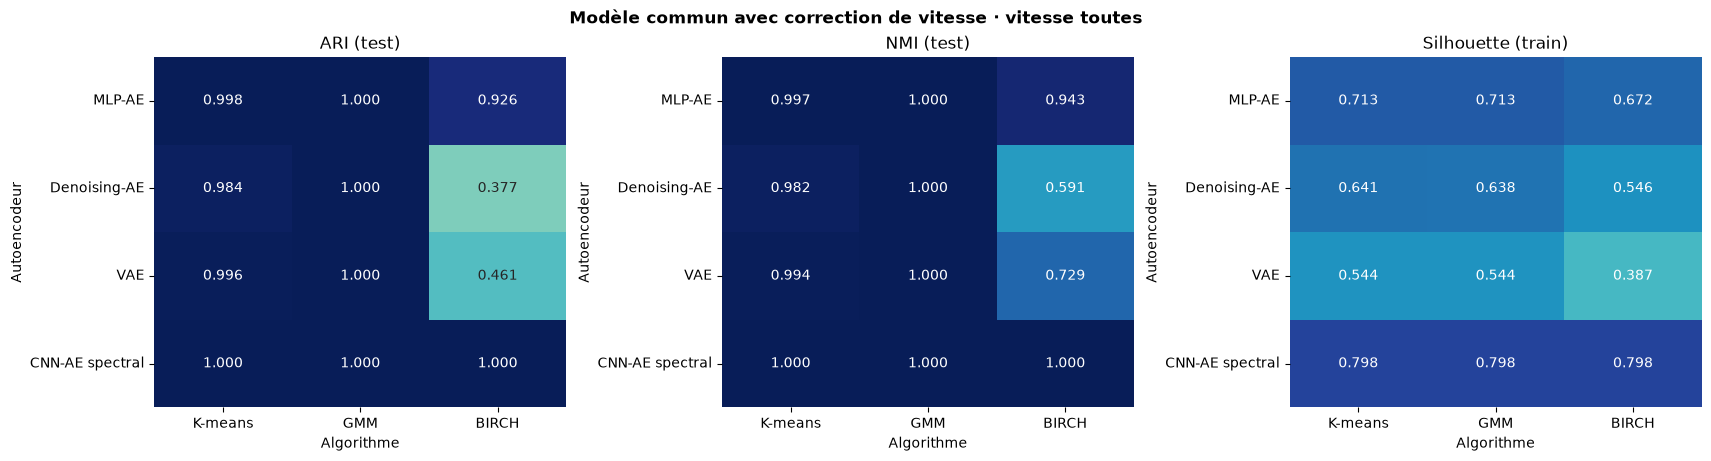

In [32]:
display(matrice_performances(res, "correction_vitesse").round(4))
_ = panneaux_scores(res, "correction_vitesse")

### Figure de synthèse B — comparer réellement K-means, GMM et BIRCH

Toutes les cellules de cette matrice sont des **ARI calculés sur les mêmes acquisitions TEST**, après correction de vitesse. Le mode de covariance de GMM est celui sélectionné sur le TRAIN pour l'étude B, **pas le GMM diagonal fixé dans l'expérience C5**. *Figure recomposée depuis le tableau B4 enregistré.*

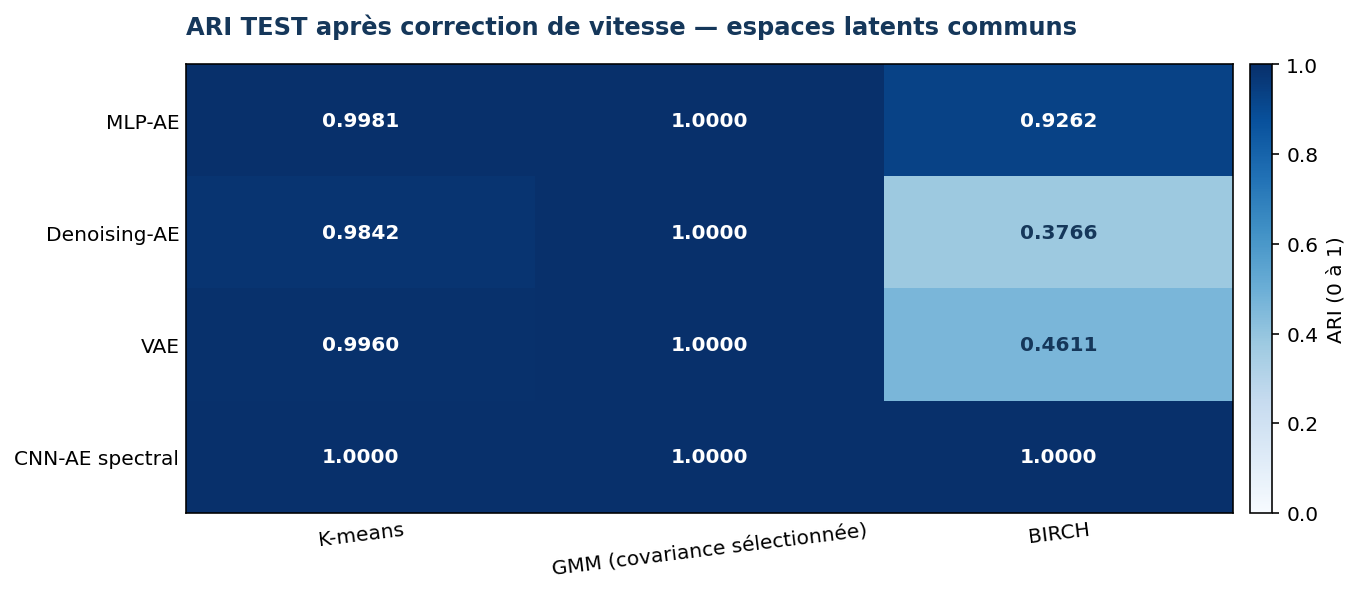

In [ ]:
# Visualisation complémentaire : performance par architecture × algorithme, après correction.
_fams=['MLP-AE','Denoising-AE','VAE','CNN-AE spectral']
_matrice=(res['scores'].query("strategie == 'correction_vitesse' and vitesse_modele == 'toutes'")
          .pivot(index='famille',columns='algorithme',values='ari')
          .reindex(index=_fams,columns=['K-means','GMM','BIRCH']))
_fig,_ax=plt.subplots(figsize=(9.5,4.2))
_im=_ax.imshow(_matrice.to_numpy(),cmap='Blues',vmin=0,vmax=1,aspect='auto')
_ax.set_xticks(range(3),['K-means','GMM (covariance sélectionnée)','BIRCH'])
_ax.set_yticks(range(4),_fams)
for _i in range(4):
    for _j in range(3):
        _val=float(_matrice.iloc[_i,_j]);_ax.text(_j,_i,f'{_val:.4f}',color='white' if _val>.72 else '#15375a',ha='center',va='center',fontweight='bold',fontsize=10)
_ax.set_title('ARI TEST après correction de vitesse — espaces latents communs',loc='left',fontweight='bold',color='#15375a',pad=15)
_ax.set_xticklabels(_ax.get_xticklabels(),rotation=7)
_ax.tick_params(length=0);_fig.colorbar(_im,ax=_ax,pad=.015,label='ARI (0 à 1)',fraction=.035)
plt.tight_layout();plt.show()

### 4.1 Visualisations après correction

Quatre familles × trois algorithmes : correspondance classe-cluster puis projection PCA. Ces graphiques permettent d'inspecter les erreurs et les changements de partition que les métriques globales ne montrent pas.

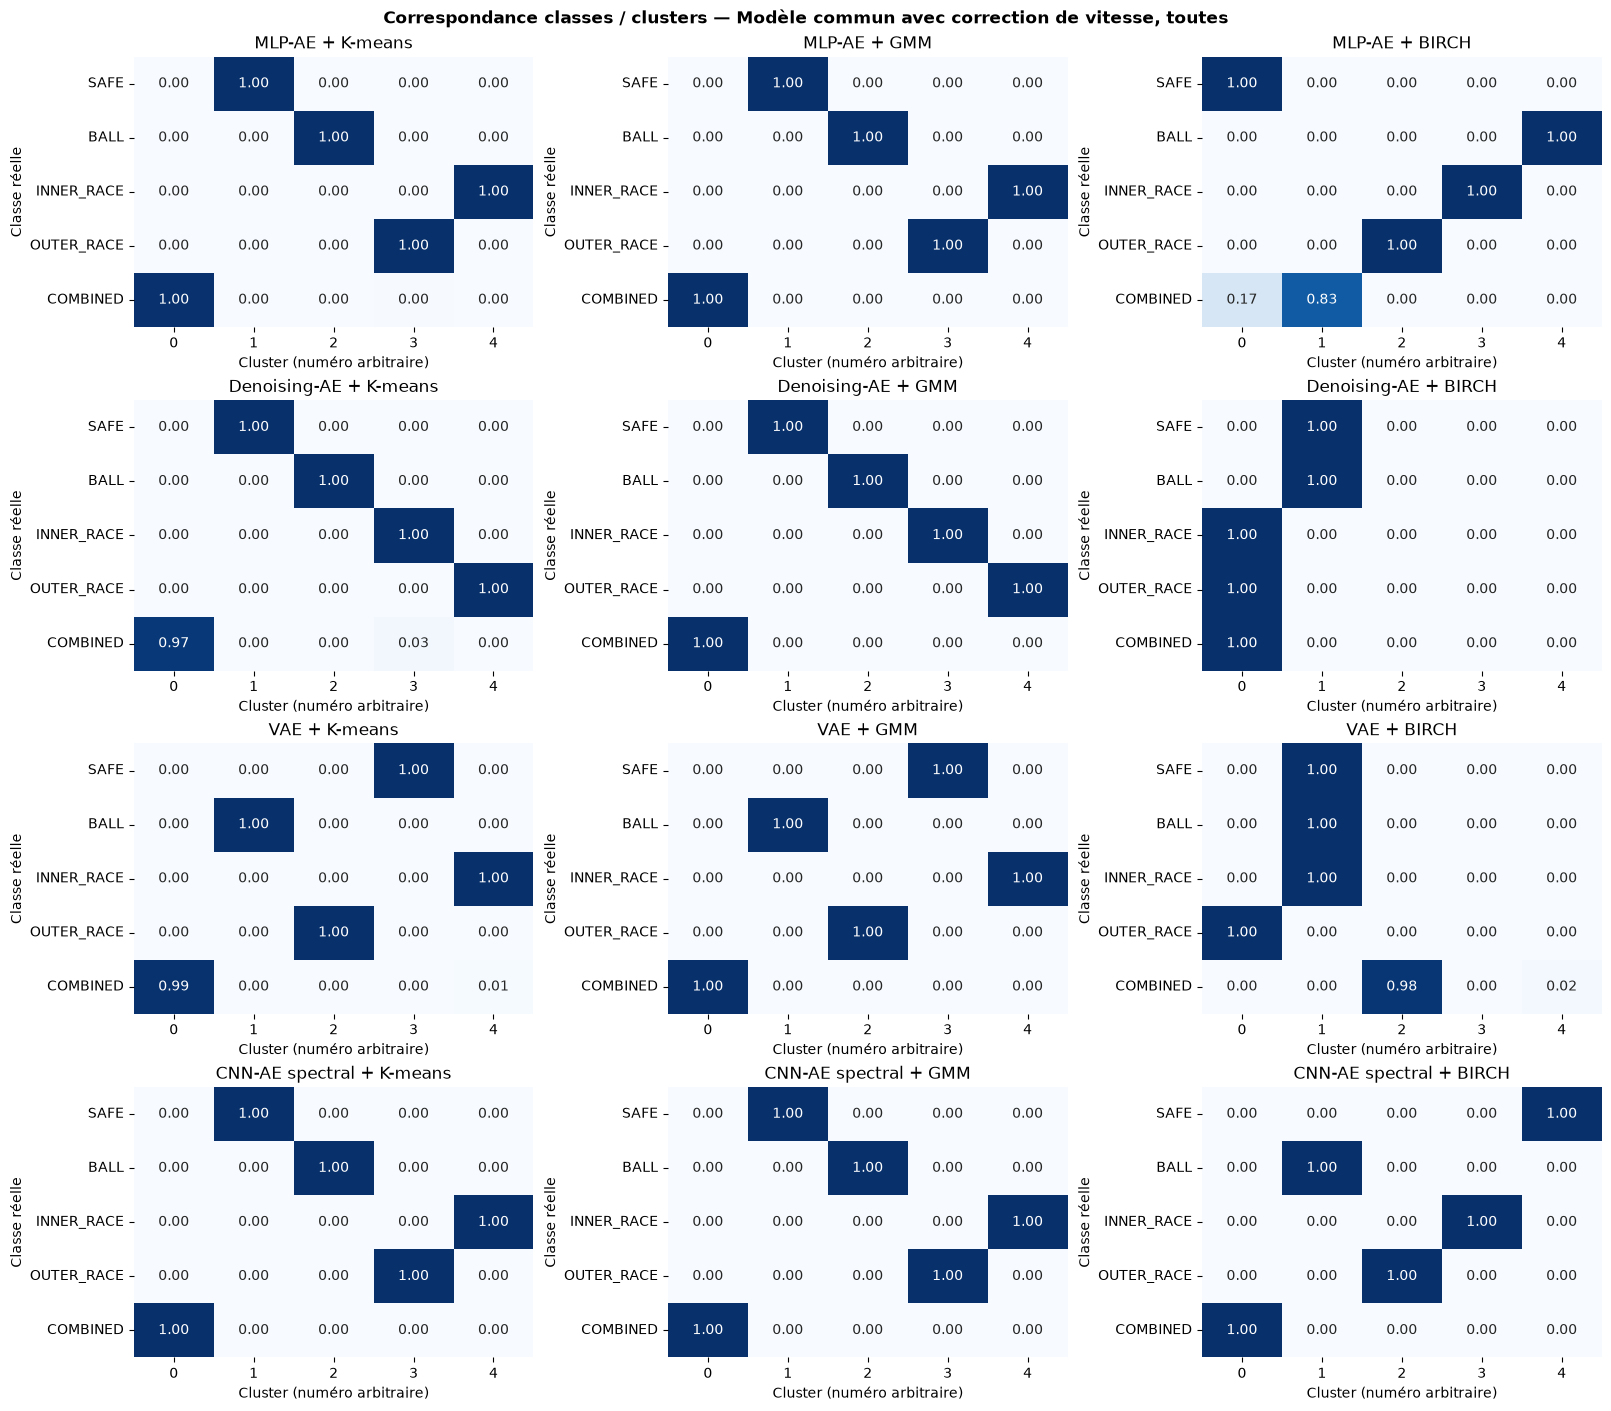

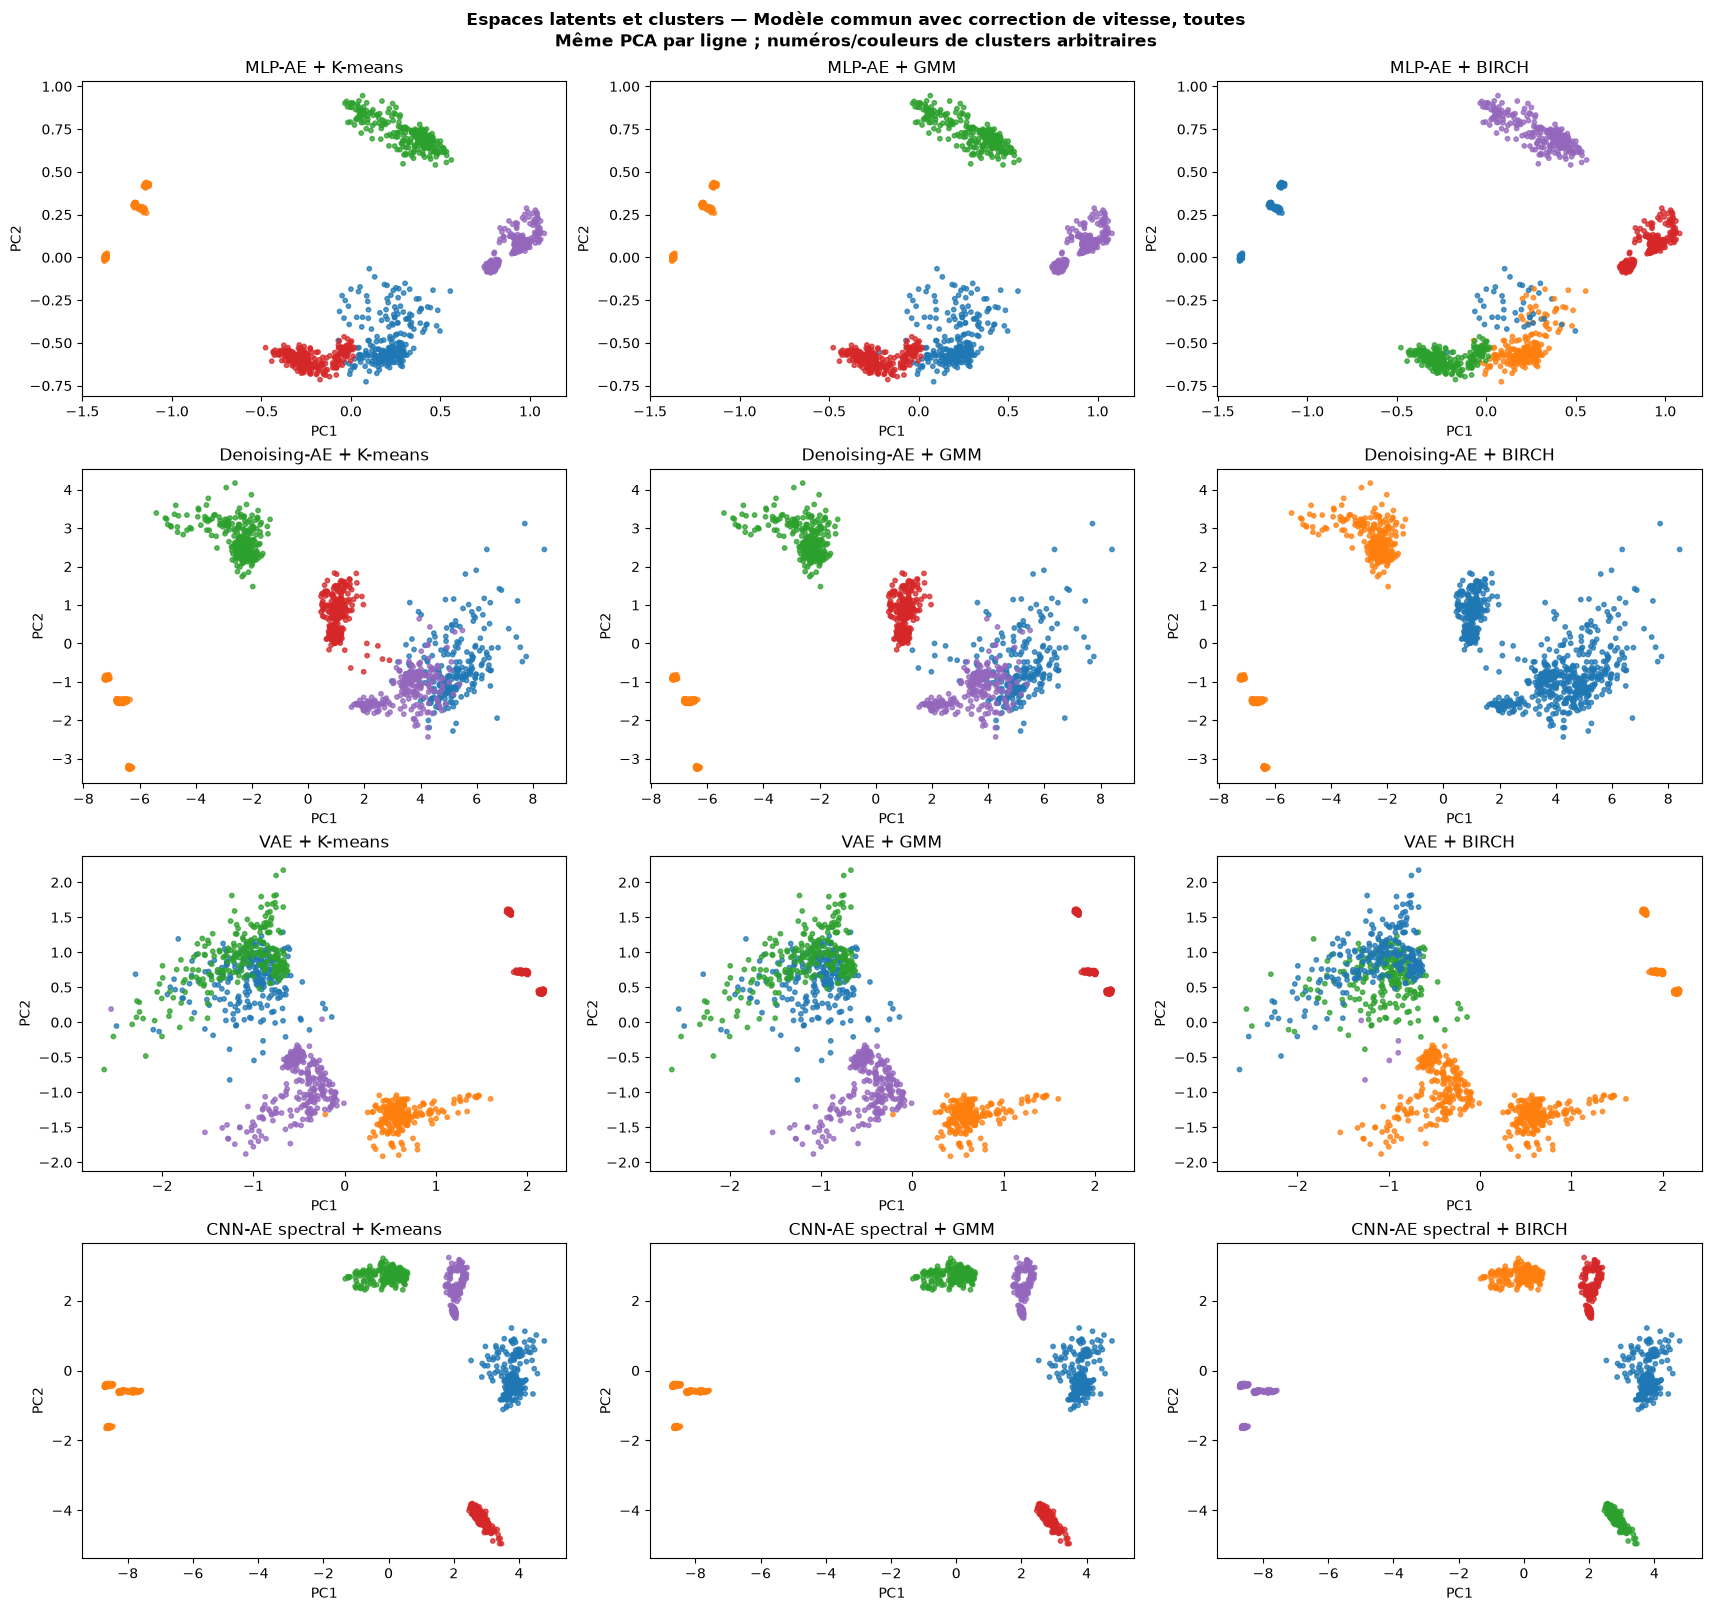

In [33]:
_ = correspondance_classes(res, "correction_vitesse")
_ = espaces_latents_cote_a_cote(res, "correction_vitesse")

### 4.2 Qualité du clustering à 10, 15 et 20

Pour le modèle global, on calcule séparément l'ARI sur le test de chaque vitesse. Ce n'est pas un test à une vitesse nouvelle : les trois régimes ont été rencontrés à l'entraînement.

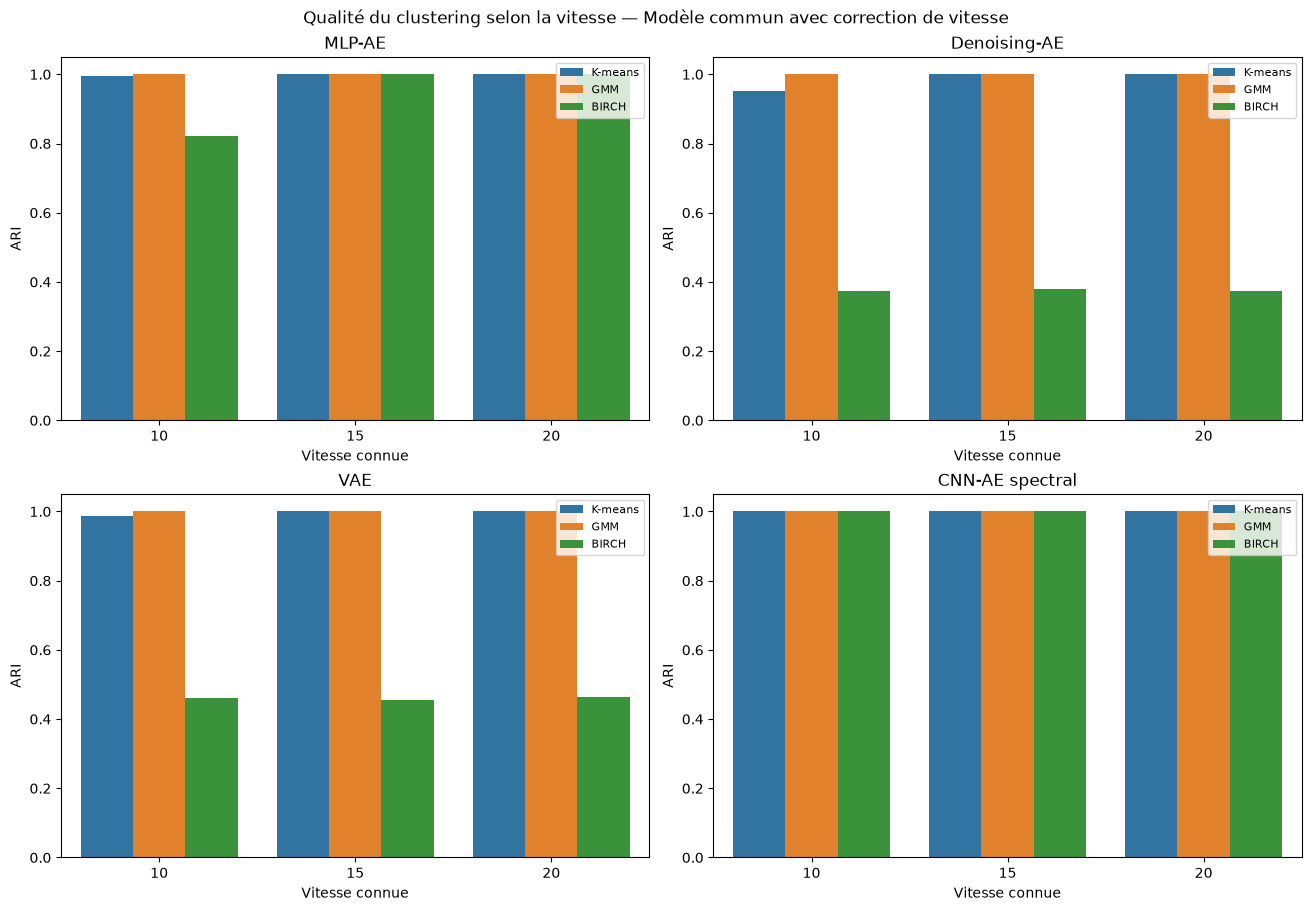

,famille,algorithme,vitesse,n_test,ari
0,MLP-AE,K-means,10,408,0.9939
1,MLP-AE,K-means,15,456,1.0000
2,MLP-AE,K-means,20,401,1.0000
3,MLP-AE,GMM,10,408,1.0000
4,MLP-AE,GMM,15,456,1.0000
5,MLP-AE,GMM,20,401,1.0000
6,MLP-AE,BIRCH,10,408,0.8214
7,MLP-AE,BIRCH,15,456,1.0000
8,MLP-AE,BIRCH,20,401,1.0000
9,Denoising-AE,K-means,10,408,0.9522


In [34]:
scores_vitesses, _ = analyse_par_vitesse(res, "correction_vitesse")
display(scores_vitesses.round(4))

### 4.3 Les trois algorithmes produisent-ils les mêmes groupes ?

On compare chaque paire de partitions par ARI entre algorithmes. Contrairement à une comparaison naïve des numéros de cluster, cette mesure ne dépend pas de leur permutation. Un ARI proche de 1 indique que les algorithmes attribuent les acquisitions aux mêmes groupes.

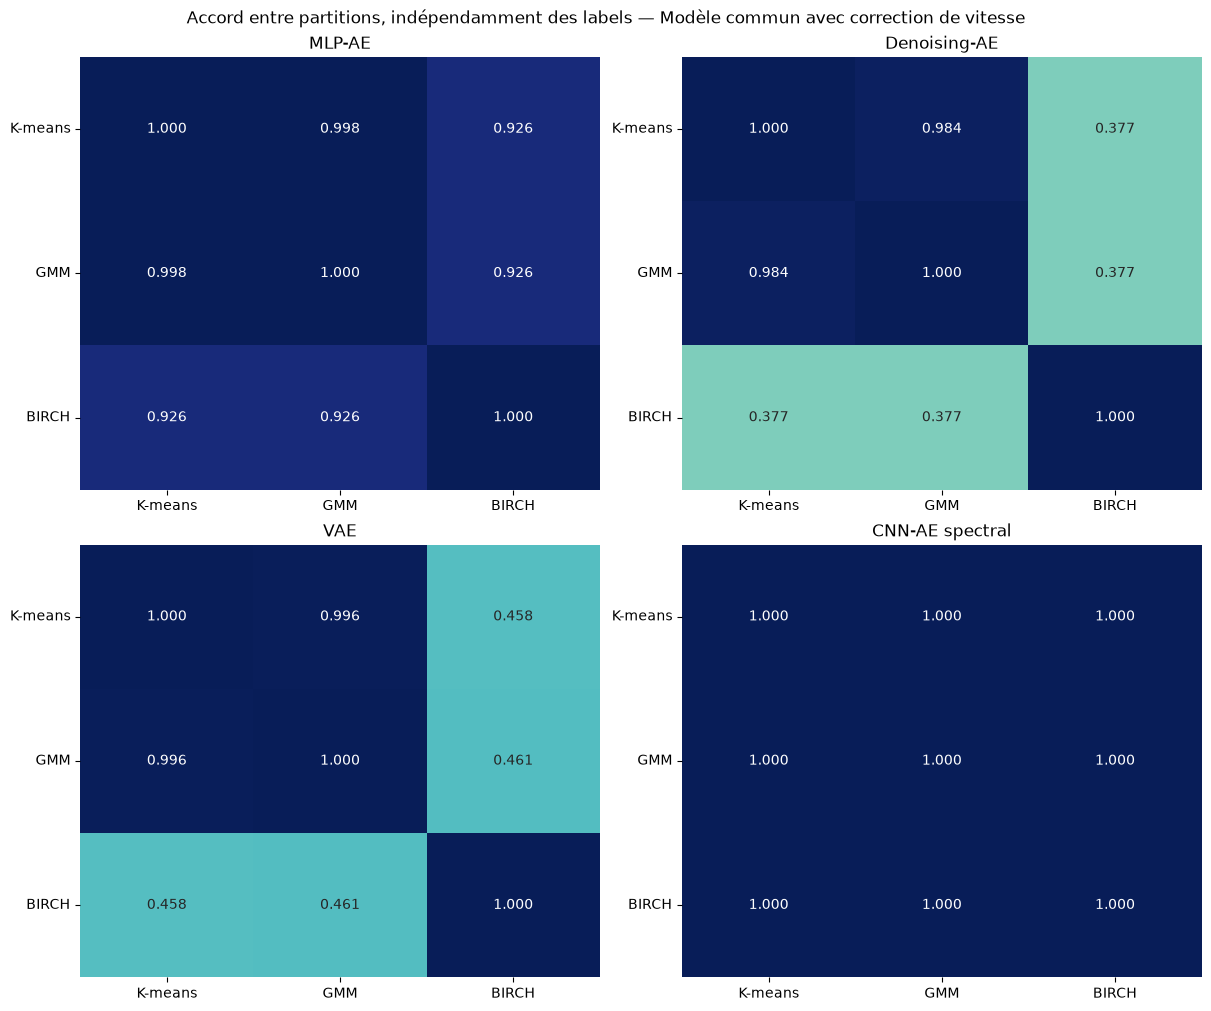

In [35]:
_ = accord_algorithmes(res, "correction_vitesse")

## 5. Bilan général — architectures et algorithmes côte à côte

Comparaison de toutes les combinaisons : pour l'approche « un modèle par vitesse », les métriques affichées sont la **moyenne des trois scores par vitesse**, et non un score obtenu par regroupement artificiel des clusters.

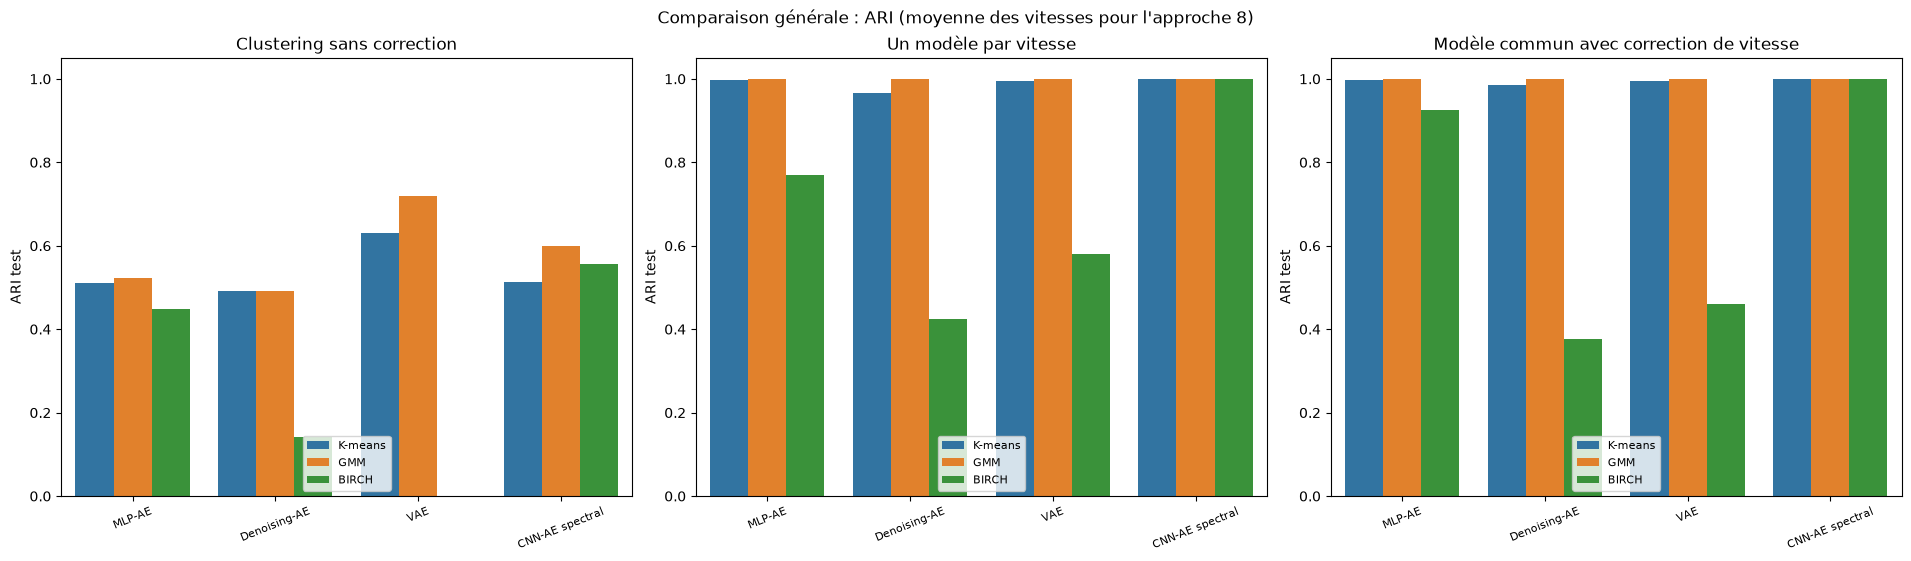

,famille,algorithme,strategie,ari,nmi,silhouette_train
23,CNN-AE spectral,BIRCH,correction_vitesse,1.0000,1.0000,0.7976
22,CNN-AE spectral,GMM,correction_vitesse,1.0000,1.0000,0.7976
21,CNN-AE spectral,K-means,correction_vitesse,1.0000,1.0000,0.7976
17,Denoising-AE,BIRCH,correction_vitesse,0.3766,0.5908,0.5455
16,Denoising-AE,GMM,correction_vitesse,1.0000,1.0000,0.6377
15,Denoising-AE,K-means,correction_vitesse,0.9842,0.9824,0.6415
14,MLP-AE,BIRCH,correction_vitesse,0.9262,0.9433,0.6724
13,MLP-AE,GMM,correction_vitesse,1.0000,1.0000,0.7131
12,MLP-AE,K-means,correction_vitesse,0.9981,0.9968,0.7131
20,VAE,BIRCH,correction_vitesse,0.4611,0.7292,0.3871


In [36]:
bilan, _ = comparaison_strategies(res)
display(bilan[["famille", "algorithme", "strategie", "ari", "nmi",
               "silhouette_train"]].round(4).sort_values(["strategie", "famille", "algorithme"]))

### 5.1 Vérifier la valeur ajoutée de l'autoencodeur

L’étude A inclut K-means directement sur les données prétraitées, sans passer par un autoencodeur. Nous conservons cette référence afin de ne pas attribuer à tort une bonne séparation exclusivement à l'architecture neuronale.

**Cette référence directe ne constitue pas un quatrième algorithme et n'est pas l'objet du nouveau benchmark.**

In [37]:
direct = comparer_baseline_directe(res)
display(direct.query("strategie == 'correction_vitesse'")[
    ["famille", "algorithme", "ari", "nmi"]].round(4))

,famille,algorithme,ari,nmi
16,MLP-AE,K-means direct (sans AE),0.9922,0.9885
17,Denoising-AE,K-means direct (sans AE),0.9922,0.9885
18,VAE,K-means direct (sans AE),0.9922,0.9885
19,CNN-AE spectral,K-means direct (sans AE),1.0000,1.0000
36,MLP-AE,K-means,0.9981,0.9968
37,Denoising-AE,K-means,0.9842,0.9824
38,VAE,K-means,0.9960,0.9942
39,CNN-AE spectral,K-means,1.0000,1.0000


### 5.2 Paramètres retenus et coût de calcul

Le tableau ci-dessous décrit le type de covariance GMM retenu, le seuil de BIRCH retenu et les durées d'ajustement. Ces durées incluent la recherche des paramètres pour GMM/BIRCH : elles **ne sont pas** des temps de prédiction en production.

**Précision :** le tableau ne comprend pas le temps de préparation des données, l'entraînement des autoencodeurs ni l'inférence de bout en bout. Un classement de coût industriel ne peut donc pas être établi à partir de ces secondes d'ajustement seules.

In [38]:
choix = res["scores"].query("strategie == 'correction_vitesse'")[
    ["famille", "algorithme", "choix_parametre", "score_selection_train",
     "convergence", "temps_fit_s"]]
display(choix.round(4))

,famille,algorithme,choix_parametre,score_selection_train,convergence,temps_fit_s
48,MLP-AE,K-means,"K=5, graine du protocole V5",NaN,True,0.5406
49,MLP-AE,GMM,covariance=full; composants=5,-86394.3793,True,0.3949
50,MLP-AE,BIRCH,threshold=0.0925444; sous_clusters=433,0.6724,True,1.8777
51,Denoising-AE,K-means,"K=5, graine du protocole V5",NaN,True,0.1015
52,Denoising-AE,GMM,covariance=full; composants=5,8287.5412,True,0.3445
53,Denoising-AE,BIRCH,threshold=1.60167; sous_clusters=14,0.5455,True,1.6611
54,VAE,K-means,"K=5, graine du protocole V5",NaN,True,0.1212
55,VAE,GMM,covariance=full; composants=5,-40927.4032,True,0.5593
56,VAE,BIRCH,threshold=0.222152; sous_clusters=485,0.3871,True,1.7576
57,CNN-AE spectral,K-means,"K=5, graine du protocole V5",NaN,True,0.0946


## B6. Discussion scientifique — effet du clustering après correction

Les performances ne permettent pas de déclarer GMM universellement supérieur, mais **sur le TEST actuel et avec correction de vitesse**, il atteint **ARI = 1,0000 pour les quatre familles d'AE**. La sélection de covariance BIC retient la covariance **complète (`full`)** dans ces quatre cas.

| Autoencodeur | K-means : ARI | GMM : ARI | BIRCH : ARI |
|---|---:|---:|---:|
| MLP-AE | 0,9981 | **1,0000** | 0,9262 |
| Denoising-AE | 0,9842 | **1,0000** | 0,3766 |
| VAE | 0,9960 | **1,0000** | 0,4611 |
| CNN-AE spectral | **1,0000** | **1,0000** | **1,0000** |

**Lecture des figures.** Les matrices classe–cluster confirment une séparation très nette pour GMM corrigé, alors que BIRCH fusionne ou répartit mal des états pour certaines familles, notamment Denoising-AE et VAE. Les identifiants de clusters sont arbitraires ; seule la correspondance d'ensemble avec les classes est évaluée.

**Coût et simplicité.** Le tableau de choix des paramètres fournit un temps d'ajustement local (en secondes), **pas le coût total** d'un système de diagnostic. K-means est facile à entraîner et à exploiter ; GMM modélise des groupes plus souples mais ajoute le choix d'une covariance ; BIRCH est moins régulier ici.

**Décision B :** parmi les solutions utilisant un autoencodeur, **CNN-AE spectral + K-means** est particulièrement convaincant : ARI parfait, silhouette élevée, stabilité à approfondir en C. **MLP-AE + GMM** est une alternative performante à partir de 26 descripteurs. Toutefois, la présence d'ARI parfaits pour des baselines **sans AE** empêche de conclure que la représentation profonde est nécessaire. Ces comparaisons doivent être confirmées sur acquisitions indépendantes et à vitesse jamais vue.

Les résultats et modèles B sont dans `results_v6_autonome/etude_b/` lorsqu'ils sont recalculés localement. Le présent `.ipynb` contient déjà les sorties utiles à leur lecture.

---
# Étude C — Validité des résultats, références classiques et robustesse

La partie C a été **effectivement calculée** sur les données et sur les latents des études A/B. Elle permet de tester la qualité de la séparation train/test, l'intérêt réel d'un autoencodeur, l'impact d'une vitesse totalement exclue de l'entraînement et la stabilité des partitions. Aucun AE historique n'est réentraîné dans cette partie.

In [39]:
import hashlib
from collections import defaultdict
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             roc_auc_score, average_precision_score,
                             precision_score, recall_score, confusion_matrix)
from scripts.methodologie_comparee_v5 import preparer

RNG_V6 = 20261116
X_DESC = bd[features].to_numpy(dtype=np.float32)
V = bd.vitesse.to_numpy()
Y_CLASSE = bd.classe.to_numpy()
TRAIN = bd.split.to_numpy() == 'train'
VALID = bd.split.to_numpy() == 'val'
TEST = bd.split.to_numpy() == 'test'
Y_DEFAUT = (Y_CLASSE != 'SAFE').astype(int)
assert len(bd)==len(spectra)==len(X_DESC)
assert TRAIN.any() and VALID.any() and TEST.any()
print('V6 —',len(bd),'acquisitions ;',TRAIN.sum(),'train /',VALID.sum(),'validation /',TEST.sum(),'test')

V6 — 8431 acquisitions ; 5902 train / 1264 validation / 1265 test


## C1. Audit des acquisitions et des risques de contamination

Le `group_id` n’existe pas dans la V4. **Le nom d’un fichier n’est pas nécessairement l’identifiant d’un roulement physique**. Nous l’utilisons uniquement comme indice de provenance à examiner avec la personne qui a constitué les données.

L’audit recherche :

1. des fichiers sources apparaissant dans plusieurs splits ;
2. des acquisitions rigoureusement identiques entre TRAIN et TEST (26 descripteurs + 512 bins) ;
3. des distances train-test très faibles, à comparer à celles observées *au sein du train* (signal d’alerte, **pas preuve de fuite**) ;
4. l’existence d’un identifiant de groupe documenté.

**Ne pas réinterpréter la colonne `fichier` comme un groupement indépendant sans vérification.**

**Résultat observé :** aucun `group_id` physique documenté ; **8 431 noms de fichiers distincts** ; **0 fichier commun entre splits** ; **0 doublon numérique exact TEST/TRAIN et TEST/VALIDATION** (26 descripteurs + 512 bins). Cela exclut les duplications exactes détectables par cet audit, **pas** les acquisitions corrélées provenant d'un même roulement ou d'une même série.

In [40]:
def audit_splits(bd, descriptors, spectra):
    r=[]
    if 'group_id' in bd.columns:
        cross = pd.crosstab(bd['group_id'].astype(str), bd['split'])
        mixed=int(((cross>0).sum(axis=1)>1).sum())
        r.append(('group_id identifiables',len(cross)))
        r.append(('group_id présents dans plusieurs splits',mixed))
    else:
        r.append(('group_id physiquement indépendant','ABSENT — validation non confirmée'))
    for field in ('fichier','chemin'):
        if field in bd.columns:
            cross=pd.crosstab(bd[field].astype(str),bd['split'])
            overlap=((cross>0).sum(axis=1)>1)
            r.append((f'{field} distincts',len(cross)))
            r.append((f'{field} communs à plusieurs splits',int(overlap.sum())))
            if overlap.any():
                r.append((f'acquisitions dans {field} communs',int(bd[field].astype(str).isin(cross.index[overlap]).sum())))
    # Vérifie l'identité numérique stricte; cela ne détecte pas les fenêtres adjacentes.
    hashes=[]
    for desc,spec in zip(descriptors,spectra):
        raw=np.asarray(desc,dtype=np.float32).tobytes()+np.asarray(spec,dtype=np.float32).tobytes()
        hashes.append(hashlib.sha256(raw).hexdigest())
    a=bd.split.to_numpy()
    hashes=np.asarray(hashes)
    r.append(('doublons exacts TEST vs TRAIN',int(np.isin(hashes[a=='test'],hashes[a=='train']).sum())))
    r.append(('doublons exacts TEST vs VAL',int(np.isin(hashes[a=='test'],hashes[a=='val']).sum())))
    return pd.DataFrame(r,columns=['Contrôle','Observation'])

audit = audit_splits(bd,X_DESC,spectra)
display(audit)
display(pd.crosstab([bd.classe, bd.vitesse],bd.split))

,Contrôle,Observation
0,group_id physiquement indépendant,ABSENT — validation non confirmée
1,fichier distincts,8431
2,fichier communs à plusieurs splits,0
3,chemin distincts,8431
4,chemin communs à plusieurs splits,0
5,doublons exacts TEST vs TRAIN,0
6,doublons exacts TEST vs VAL,0


split               test  train  val
classe     vitesse                  
BALL       10         85    396   85
           15         87    403   86
           20         83    389   83
COMBINED   10         82    385   83
           15         87    402   86
           20         78    363   78
INNER_RACE 10         84    389   83
           15         98    461   99
           20         84    393   85
OUTER_RACE 10         79    370   78
           15         85    393   84
           20         77    361   77
SAFE       10         78    366   79
           15         99    465  100
           20         79    366   78

### C1.1 Acquisitions très proches : contrôle exploratoire

On compare la distance du plus proche voisin **TEST → TRAIN** à la distance du plus proche voisin **TRAIN → TRAIN** (en excluant l’acquisition elle-même), après standardisation ajustée uniquement sur TRAIN. Des distances nulles ou extrêmement faibles méritent d’inspecter les mesures d’origine, mais ne suffisent pas à conclure à une fuite.

**Résultat observé :** distance médiane train→train **0,26168** contre test→train **0,25796** ; les percentiles 1 et 99 sont également proches. Aucun voisin de distance < 10⁻⁶ n'est détecté dans ces deux ensembles. Ce comportement ne constitue **ni une preuve d'indépendance ni une fuite démontrée** ; l'identité physique des acquisitions doit être auditée.

Distances médianes (descripteurs standardisés) : TRAIN→TRAIN 0.26168 TEST→TRAIN 0.25796


,Jeu,p01,médiane,p99,distance < 1e-6
0,TRAIN→TRAIN (hors soi),0.03239,0.26168,1.25182,0
1,TEST→TRAIN,0.03384,0.25796,1.24977,0


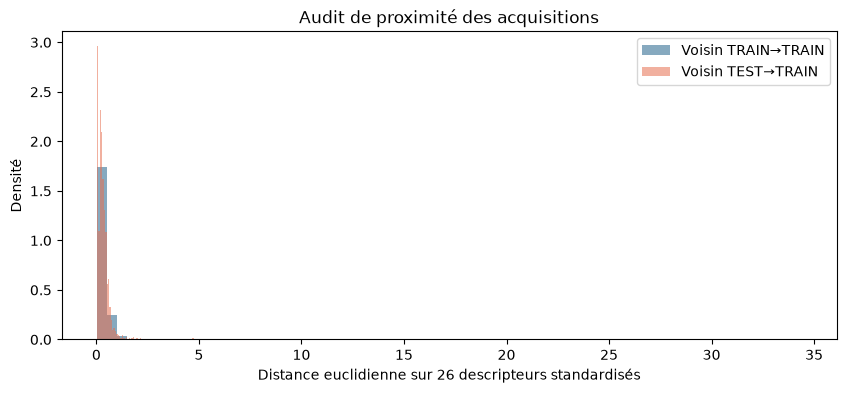

In [41]:
xx=StandardScaler().fit(X_DESC[TRAIN]).transform(X_DESC).astype(np.float32)
xtr=xx[TRAIN]
xte=xx[TEST]
nn=NearestNeighbors(n_neighbors=2).fit(xtr)
dtr=nn.kneighbors(xtr,return_distance=True)[0][:,1]
dte=nn.kneighbors(xte,return_distance=True)[0][:,0]
print('Distances médianes (descripteurs standardisés) :',
      'TRAIN→TRAIN',round(float(np.median(dtr)),5),
      'TEST→TRAIN',round(float(np.median(dte)),5))
distances = pd.DataFrame({
    'Jeu':['TRAIN→TRAIN (hors soi)','TEST→TRAIN'],
    'p01':[np.percentile(dtr,1),np.percentile(dte,1)],
    'médiane':[np.median(dtr),np.median(dte)],
    'p99':[np.percentile(dtr,99),np.percentile(dte,99)],
    'distance < 1e-6':[int((dtr <1e-6).sum()),int((dte<1e-6).sum())]
})
display(distances.round(5))
plt.figure(figsize=(10,4))
plt.hist(dtr,bins=70,alpha=.65,density=True,label='Voisin TRAIN→TRAIN',color='#457b9d')
plt.hist(dte,bins=70,alpha=.55,density=True,label='Voisin TEST→TRAIN',color='#e76f51')
plt.legend(); plt.xlabel('Distance euclidienne sur 26 descripteurs standardisés')
plt.ylabel('Densité'); plt.title('Audit de proximité des acquisitions');plt.show()

## C2. Méthodes de référence **sans** autoencodeur

Notre CNN-AE + K-means atteint déjà ARI = 1 sur le test courant, mais **K-means sur les spectres corrigés atteint aussi 1**. Pour savoir si un réseau neuronal est utile, nous ajoutons des baselines contrôlées :

- 26 descripteurs standardisés + K-means ou GMM ;
- PCA à 6 dimensions sur ces descripteurs + K-means ou GMM ;
- 512 bins spectraux standardisés + K-means ;
- PCA à 6 dimensions sur les spectres + K-means ou GMM.

Deux stratégies sont évaluées, avec ou sans correction de vitesse. Les algorithmes ne voient jamais les classes du test au moment de leur ajustement. **K=5 est un choix informé par le banc d’essai** ; GMM utilise ici la covariance diagonale fixée à l’avance, contrairement à la recherche BIC de l’étude B.

**Résultats après correction :** sur le TEST, cinq références classiques atteignent **ARI = 1,0000** : K-means brut sur les 512 bins spectraux ; K-means et GMM diagonal sur leur PCA6 ; GMM diagonal brut et après PCA6 sur les 26 descripteurs. K-means brut sur les 26 descripteurs atteint **0,9922**. **Sans correction**, toutes les références C2 restent sous **0,5531**. La normalisation par vitesse joue donc ici un rôle déterminant, sans qu'on puisse attribuer à l'AE une amélioration nécessaire.

,strategie,entree,reduction,algorithme,n_train,n_test,ari,nmi,ari_vs_vitesse
12,correction_vitesse,512 bins spectraux,PCA6,K-means,5902,1265,1.0000,1.0000,-0.0017
13,correction_vitesse,512 bins spectraux,PCA6,GMM-diag,5902,1265,1.0000,1.0000,-0.0017
10,correction_vitesse,26 descripteurs,PCA6,GMM-diag,5902,1265,1.0000,1.0000,-0.0017
11,correction_vitesse,512 bins spectraux,brut,K-means,5902,1265,1.0000,1.0000,-0.0017
8,correction_vitesse,26 descripteurs,brut,GMM-diag,5902,1265,1.0000,1.0000,-0.0017
7,correction_vitesse,26 descripteurs,brut,K-means,5902,1265,0.9922,0.9885,-0.0017
9,correction_vitesse,26 descripteurs,PCA6,K-means,5902,1265,0.9921,0.9888,-0.0017
3,sans_correction,26 descripteurs,PCA6,GMM-diag,5902,1265,0.5531,0.7160,0.0837
4,sans_correction,512 bins spectraux,brut,K-means,5902,1265,0.5269,0.6705,0.1399
2,sans_correction,26 descripteurs,PCA6,K-means,5902,1265,0.5248,0.6937,0.1038


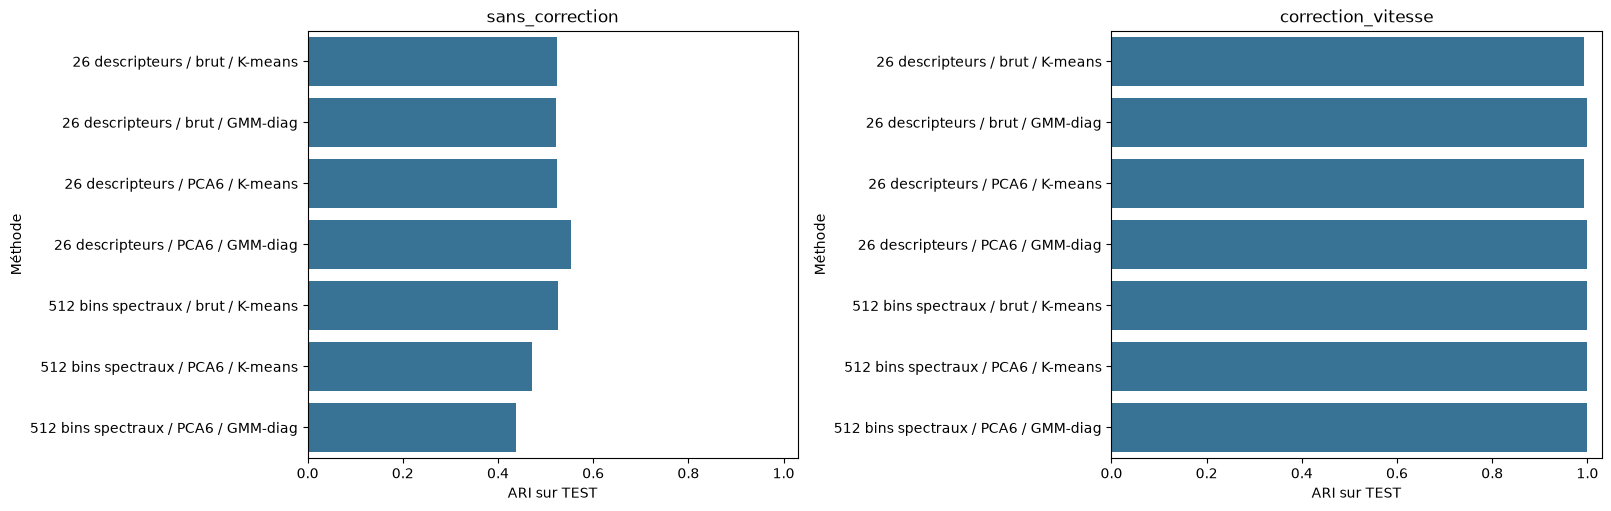

In [42]:
def baselines_non_supervisees(bd, x_desc, x_spectres, features, seed=42):
    split=bd.split.to_numpy(); tr=split=='train'; te=split=='test'
    y=bd.classe.to_numpy()[te]
    v=bd.vitesse.to_numpy()[te]
    records=[]
    for strategie in ('sans_correction','correction_vitesse'):
        stage=strategie
        for modalite, original, colonnes in (
            ('26 descripteurs',x_desc,features),('512 bins spectraux',x_spectres,None)):
            x,_=preparer(bd,original,colonnes,stage,tr)
            for reduction in ('brut','PCA6'):
                if reduction=='brut':
                    z=x
                else:
                    pca=PCA(n_components=6,random_state=seed)
                    z=np.empty((len(x),6),dtype=np.float32)
                    z[tr]=pca.fit_transform(x[tr]);z[~tr]=pca.transform(x[~tr])
                algos=('K-means',) if modalite=='512 bins spectraux' and reduction=='brut' else ('K-means','GMM-diag')
                for algo in algos:
                    if algo=='K-means':
                        pred=KMeans(n_clusters=5,n_init=10,random_state=seed).fit(z[tr]).predict(z[te])
                    else:
                        pred=GaussianMixture(n_components=5,covariance_type='diag',
                                             reg_covar=1e-5,n_init=2,max_iter=250,
                                             random_state=seed).fit(z[tr]).predict(z[te])
                    records.append(dict(strategie=strategie,entree=modalite,
                                        reduction=reduction,algorithme=algo,
                                        n_train=int(tr.sum()),n_test=int(te.sum()),
                                        ari=adjusted_rand_score(y,pred),
                                        nmi=normalized_mutual_info_score(y,pred),
                                        ari_vs_vitesse=adjusted_rand_score(v,pred)))
    return pd.DataFrame(records)

baselines_v6=baselines_non_supervisees(bd,X_DESC,spectra,features)
display(baselines_v6.sort_values('ari',ascending=False).round(4))
fig, axes=plt.subplots(1,2,figsize=(16,5),constrained_layout=True)
for ax,strat in zip(axes,['sans_correction','correction_vitesse']):
    sub=baselines_v6.query('strategie==@strat').copy()
    sub['Méthode']=sub['entree']+' / '+sub['reduction']+' / '+sub['algorithme']
    sns.barplot(data=sub,y='Méthode',x='ari',ax=ax,color='#2877a4')
    ax.set_xlim(0,1.03);ax.set_title(strat);ax.set_xlabel('ARI sur TEST')
plt.show()

## C3. Détection d’anomalies : Isolation Forest, One-Class SVM et PCA

**Protocole comparable à l’étude A :** prétraitement ajusté sur les acquisitions SAFE du train ; ajustement du détecteur exclusivement sur TRAIN/SAFE ; seuil de décision au **99e percentile de VAL/SAFE** ; score et métriques calculés sur TEST avec SAFE contre tous les défauts. La PR-AUC complète l’AUROC lorsque les classes sont déséquilibrées.

Ces détecteurs classiques ne sont pas des autoencodeurs. Ils permettent de vérifier si la reconstruction profonde apporte une amélioration de la détection.

**Résultat enregistré :** les sept détecteurs atteignent AUROC = **1,0000** et rappel = **1,0000**, mais produisent **3 à 11 fausses alarmes sur 256 acquisitions SAFE TEST**. En particulier : PCA par reconstruction et MLP-AE/Denoising-AE : **3** ; CNN-AE et Isolation Forest : **4** ; VAE : **8** ; One-Class SVM : **11**. **Une AUROC parfaite ne signifie donc pas un seuil opérationnel sans erreur.** La PR-AUC des méthodes classiques est calculée par le code (`detecteurs_simples`) mais n'est pas reportée dans le tableau comparatif principal.

,type,modèle,auroc,precision,rappel,fausses_alarmes,manques,taux_fausses_alarmes
0,Méthode classique,Isolation Forest,1.0,0.9961,1.0,4,0,0.0156
1,Méthode classique,One-Class SVM,1.0,0.9892,1.0,11,0,0.0430
2,Méthode classique,PCA reconstruction,1.0,0.9970,1.0,3,0,0.0117
3,Autoencodeur V5,MLP-AE,1.0,0.9970,1.0,3,0,0.0117
4,Autoencodeur V5,Denoising-AE,1.0,0.9970,1.0,3,0,0.0117
5,Autoencodeur V5,VAE,1.0,0.9921,1.0,8,0,0.0312
6,Autoencodeur V5,CNN-AE spectral,1.0,0.9961,1.0,4,0,0.0156


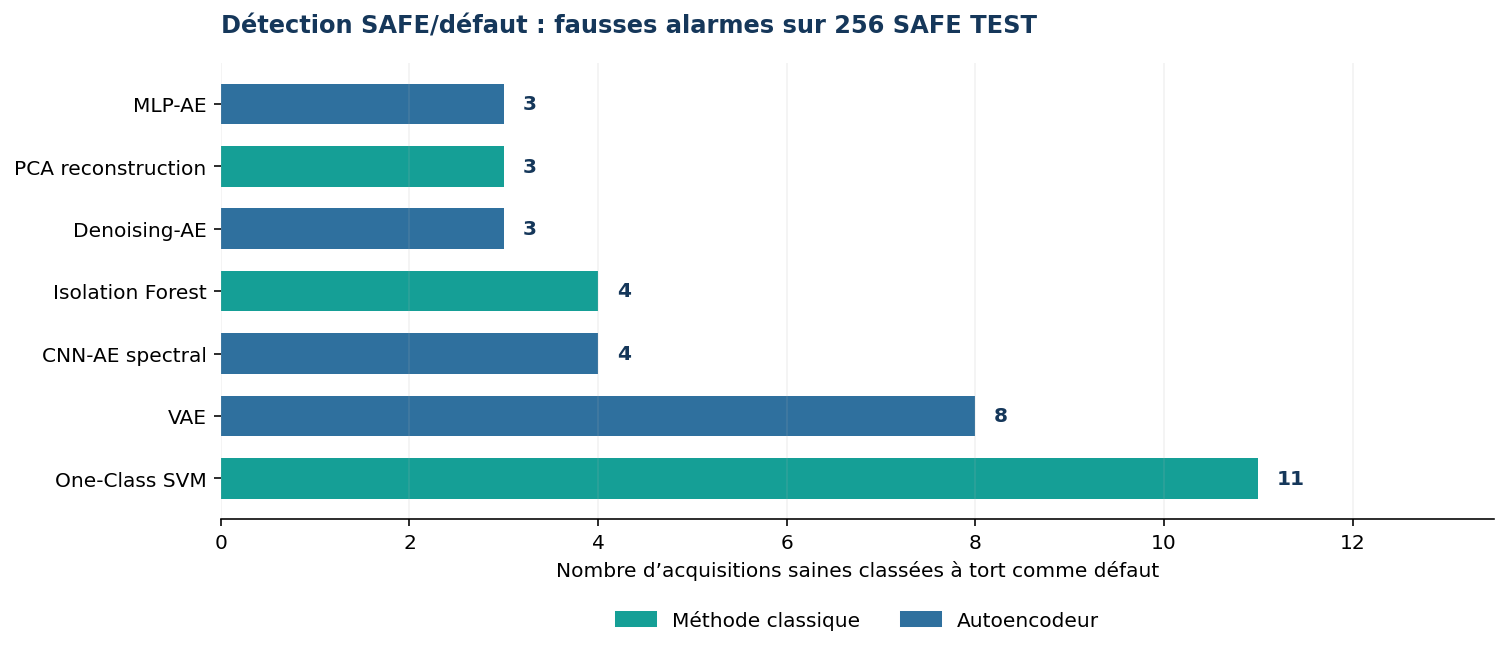

In [43]:
def evaluer_detection_classique(bd, x, features, seed=42):
    split=bd.split.to_numpy(); labels=bd.classe.to_numpy()
    safe=labels=='SAFE'; tr=(split=='train')&safe
    va=(split=='val')&safe; te=(split=='test')
    assert tr.sum()>15 and va.sum()>10 and te.sum()>10
    y=(~safe).astype(int); ytest=y[te]
    xx,_=preparer(bd,x,features,'sans_correction',tr)
    out=[]
    for nom in ('Isolation Forest','One-Class SVM','PCA reconstruction'):
        if nom=='Isolation Forest':
            est=IsolationForest(n_estimators=200,random_state=seed,n_jobs=-1).fit(xx[tr])
            scores=-est.score_samples(xx)
        elif nom=='One-Class SVM':
            est=OneClassSVM(nu=0.05,gamma='scale').fit(xx[tr])
            scores=-est.decision_function(xx)
        else:
            est=PCA(n_components=6,random_state=seed).fit(xx[tr])
            z=est.transform(xx)
            scores=np.mean((xx-est.inverse_transform(z))**2,axis=1)
        threshold=float(np.percentile(scores[va],99))
        pred=(scores[te]>threshold).astype(int)
        tn,fp,fn,tp=confusion_matrix(ytest,pred,labels=[0,1]).ravel()
        out.append(dict(methode=nom,auroc=roc_auc_score(ytest,scores[te]),
                        pr_auc=average_precision_score(ytest,scores[te]),
                        precision=precision_score(ytest,pred,zero_division=0),
                        rappel=recall_score(ytest,pred,zero_division=0),
                        fausses_alarmes=int(fp),manques=int(fn),
                        taux_fausses_alarmes=fp/max(1,fp+tn),
                        seuil_val_safe_p99=threshold))
    return pd.DataFrame(out)

detecteurs_simples=evaluer_detection_classique(bd,X_DESC,features)
comparatif_detect=pd.concat([
    detecteurs_simples.assign(type='Méthode classique').rename(columns={'methode':'modèle'}),
    resultats['detection'].rename(columns={'famille':'modèle',
               'fp':'fausses_alarmes','fn':'manques'})
              .assign(type='Autoencodeur V5')
],ignore_index=True)
display(comparatif_detect[['type','modèle','auroc','precision','rappel',
                           'fausses_alarmes','manques','taux_fausses_alarmes']].round(4))
# Remplace le graphique AUROC uniforme (=1 pour tous) par les fausses alarmes.
# Le tableau juste au-dessus conserve AUROC, précision et rappel.
_df = comparatif_detect[['type','modèle','fausses_alarmes','manques']].copy()
_df = _df.sort_values('fausses_alarmes')
_fig,_ax = plt.subplots(figsize=(10.5,4.7))
_colors=['#159f96' if t=='Méthode classique' else '#2f709e' for t in _df['type']]
_bars=_ax.barh(_df['modèle'],_df['fausses_alarmes'],color=_colors,height=.65)
_ax.invert_yaxis();_ax.set_xlim(0,max(_df['fausses_alarmes'])+2.5)
for _bar,_num in zip(_bars,_df['fausses_alarmes']):
    _ax.text(_num+.2,_bar.get_y()+_bar.get_height()/2,str(int(_num)),va='center',color='#15375a',fontweight='bold')
_ax.set_title('Détection SAFE/défaut : fausses alarmes sur 256 SAFE TEST',loc='left',fontweight='bold',color='#15375a',pad=15)
_ax.set_xlabel('Nombre d’acquisitions saines classées à tort comme défaut')
_ax.spines[['top','right','left']].set_visible(False);_ax.grid(axis='x',alpha=.16)
from matplotlib.patches import Patch
_ax.legend(handles=[Patch(color='#159f96',label='Méthode classique'),Patch(color='#2f709e',label='Autoencodeur')],loc='upper center',bbox_to_anchor=(0.5,-0.16),ncol=2,frameon=False)
plt.tight_layout();plt.show()

**Commentaire de la figure C3.** Les sept AUROC sont égales à 1 : elles ne discriminent donc pas les modèles sur ce TEST. Le graphique indique plutôt les **fausses alarmes sur 256 SAFE** (en conservant le tableau AUROC, rappel et précision). Tous les détecteurs gardent **zéro défaut manqué** au seuil testé. Le choix doit considérer les conséquences respectives des fausses alertes et des défauts non détectés, et sera à revalider sur une cohorte indépendante.

## C3 bis. Vitesse **totalement inconnue** : validation inter-régimes des références

Les études A/B analysent seulement des vitesses **présentes à l'entraînement** (10, 15, 20). Nous ajoutons un test de généralisation plus exigeant : pour chaque vitesse tenue à l'écart, **aucune acquisition de cette vitesse, quel que soit son split d'origine, n'est utilisée pour entraîner le scaler, la PCA ou le clustering**.

On entraîne uniquement sur les acquisitions du **TRAIN des deux autres vitesses** et on évalue sur le **TEST de la vitesse retirée**. Comme la correction « standardisation par vitesse » de A nécessite des exemples TRAIN à chaque vitesse, **elle n'est pas applicable à ce protocole sans nouvelle règle de normalisation**. Nous utilisons donc une standardisation globale ajustée exclusivement sur les vitesses d'entraînement.

Cette expérience concerne **des baselines classiques (K-means et GMM sur PCA6)**, **pas une nouvelle validation des autoencodeurs**. Les résultats de cette section démontrent seulement ce qu'apprennent ces références sous changement de régime.

**Résultats observés :** avec une vitesse exclue, les douze ARI des références PCA6 varient de **0,1963 à 0,7769**. Pour la vitesse **10**, ils sont de **0,1963 à 0,5171** ; pour la vitesse **15**, de **0,5888 à 0,7769** ; pour la vitesse **20**, de **0,4489 à 0,5544**. Ce décrochage illustre une dépendance forte au régime. **Aucun autoencodeur n'a encore été évalué par cette expérience de vitesse exclue** ; on ne peut donc pas généraliser ce résultat directement aux AE.

,vitesse_absente,entree,algorithme,n_train,n_test,ari,nmi
0,10,descripteurs,K-means,3996,408,0.1963,0.4191
1,10,descripteurs,GMM-diag,3996,408,0.5171,0.6382
2,10,spectres,K-means,3996,408,0.1968,0.4338
3,10,spectres,GMM-diag,3996,408,0.3639,0.5906
4,15,descripteurs,K-means,3778,456,0.7769,0.9044
5,15,descripteurs,GMM-diag,3778,456,0.6051,0.7795
6,15,spectres,K-means,3778,456,0.5888,0.7187
7,15,spectres,GMM-diag,3778,456,0.6366,0.7564
8,20,descripteurs,K-means,4030,401,0.5379,0.7518
9,20,descripteurs,GMM-diag,4030,401,0.4489,0.7120


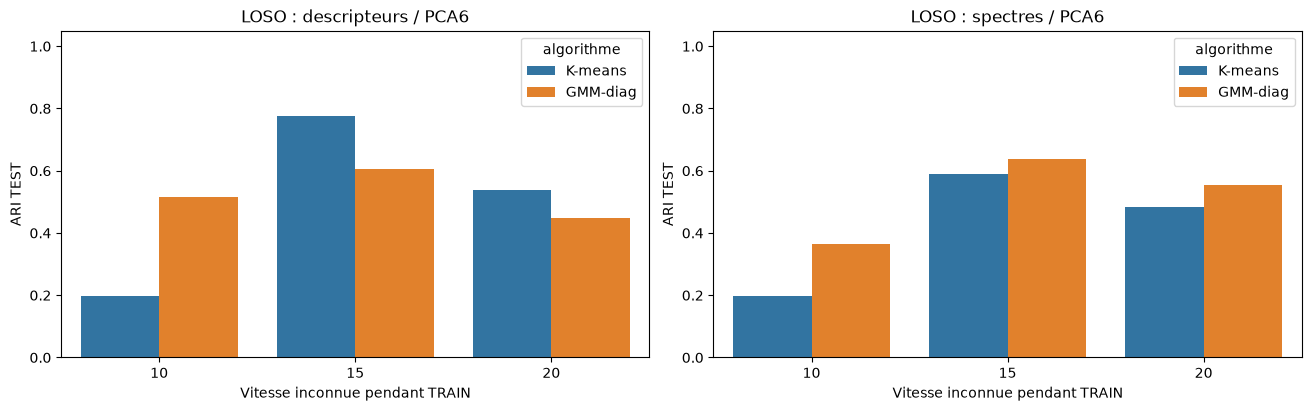

In [44]:
def test_vitesse_tenue_a_ecart(bd, x_desc, x_spectres, seed=42):
    v=bd.vitesse.to_numpy();split=bd.split.to_numpy()
    y=bd.classe.to_numpy();data=[]
    for vitesse_absente in sorted(np.unique(v)):
        train=(split=='train') & (v!=vitesse_absente)
        test=(split=='test') & (v==vitesse_absente)
        if len(np.unique(y[train]))<5 or test.sum()<5:
            raise ValueError('Données insuffisantes : vitesse '+str(vitesse_absente))
        for ent,original in [('descripteurs',x_desc),('spectres',x_spectres)]:
            scale=StandardScaler().fit(original[train])
            xtrain=scale.transform(original[train]).astype(np.float32)
            xtest=scale.transform(original[test]).astype(np.float32)
            pca=PCA(n_components=6,random_state=seed).fit(xtrain)
            ztrain=pca.transform(xtrain)
            ztest=pca.transform(xtest)
            for algo in ('K-means','GMM-diag'):
                if algo=='K-means':
                    model=KMeans(n_clusters=5,n_init=10,random_state=seed).fit(ztrain)
                else:
                    model=GaussianMixture(n_components=5,covariance_type='diag',
                                reg_covar=1e-5,n_init=2,max_iter=250,random_state=seed).fit(ztrain)
                prediction=model.predict(ztest)
                data.append(dict(vitesse_absente=int(vitesse_absente),
                                 entree=ent,algorithme=algo,n_train=int(train.sum()),
                                 n_test=int(test.sum()),
                                 ari=adjusted_rand_score(y[test],prediction),
                                 nmi=normalized_mutual_info_score(y[test],prediction)))
    return pd.DataFrame(data)

loso_v6=test_vitesse_tenue_a_ecart(bd,X_DESC,spectra)
display(loso_v6.round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
for ax,ent in zip(axes,['descripteurs','spectres']):
    d=loso_v6.query('entree==@ent')
    sns.barplot(data=d,x='vitesse_absente',y='ari',hue='algorithme',ax=ax)
    ax.set_ylim(0,1.05);ax.set_title('LOSO : '+ent+' / PCA6')
    ax.set_xlabel('Vitesse inconnue pendant TRAIN');ax.set_ylabel('ARI TEST')
plt.show()

**Interprétation du test de vitesse exclue.** Les barres les plus faibles apparaissent lorsque la vitesse 10 est entièrement absente du TRAIN (meilleur ARI de ce groupe = **0,5171**). La vitesse 15 exclue donne le meilleur résultat de ce protocole (**0,7769** pour K-means sur les descripteurs), mais reste loin des ARI parfaits sur vitesses vues. Les autres régimes et modalités ne montrent pas de méthode universellement robuste. **Ne pas comparer directement ces scores aux AE A/B**, qui n'ont pas été évalués sous exclusion de régime.

## C4. Répétabilité des algorithmes sur les représentations A

Nous mesurons la variabilité de K-means et GMM sur **les mêmes espaces latents déjà entraînés**, en changeant uniquement leurs initialisations. **Cela ne mesure pas la variabilité de l’entraînement des autoencodeurs**, qui exigerait de les réentraîner avec plusieurs graines.

GMM utilise son **type de covariance sélectionné par BIC sur TRAIN dans l’étude B** ; seule l’initialisation change. Les scores TEST sont observés pour l’analyse de robustesse, jamais pour choisir une graine.

**Résultat observé sur cinq graines :** CNN-AE + K-means et CNN-AE + GMM obtiennent **ARI = 1,0000 à chacune des cinq initialisations** ; MLP-AE + GMM et Denoising-AE + GMM également. **VAE + GMM** varie de **0,8583 à 1,0000** (moyenne **0,9717**, écart-type **0,0634**). Cette stabilité porte **sur le clustering de latents figés**, pas sur la variabilité des réentraînements des encodeurs.

ari_moyen  ari_ecart_type  ari_min  ari_max  \
famille         algorithme                                                
CNN-AE spectral GMM            1.0000          0.0000   1.0000   1.0000   
                K-means        1.0000          0.0000   1.0000   1.0000   
Denoising-AE    GMM            1.0000          0.0000   1.0000   1.0000   
                K-means        0.9842          0.0000   0.9842   0.9842   
MLP-AE          GMM            1.0000          0.0000   1.0000   1.0000   
                K-means        0.9981          0.0000   0.9981   0.9981   
VAE             GMM            0.9717          0.0634   0.8583   1.0000   
                K-means        0.9960          0.0000   0.9960   0.9960   

                            nmi_moyen  
famille         algorithme             
CNN-AE spectral GMM            1.0000  
                K-means        1.0000  
Denoising-AE    GMM            1.0000  
                K-means        0.9824  
MLP-AE          GMM            1.0000  
                K-means        0.9968  
VAE             GMM            0.9824  
                K-means        0.9942

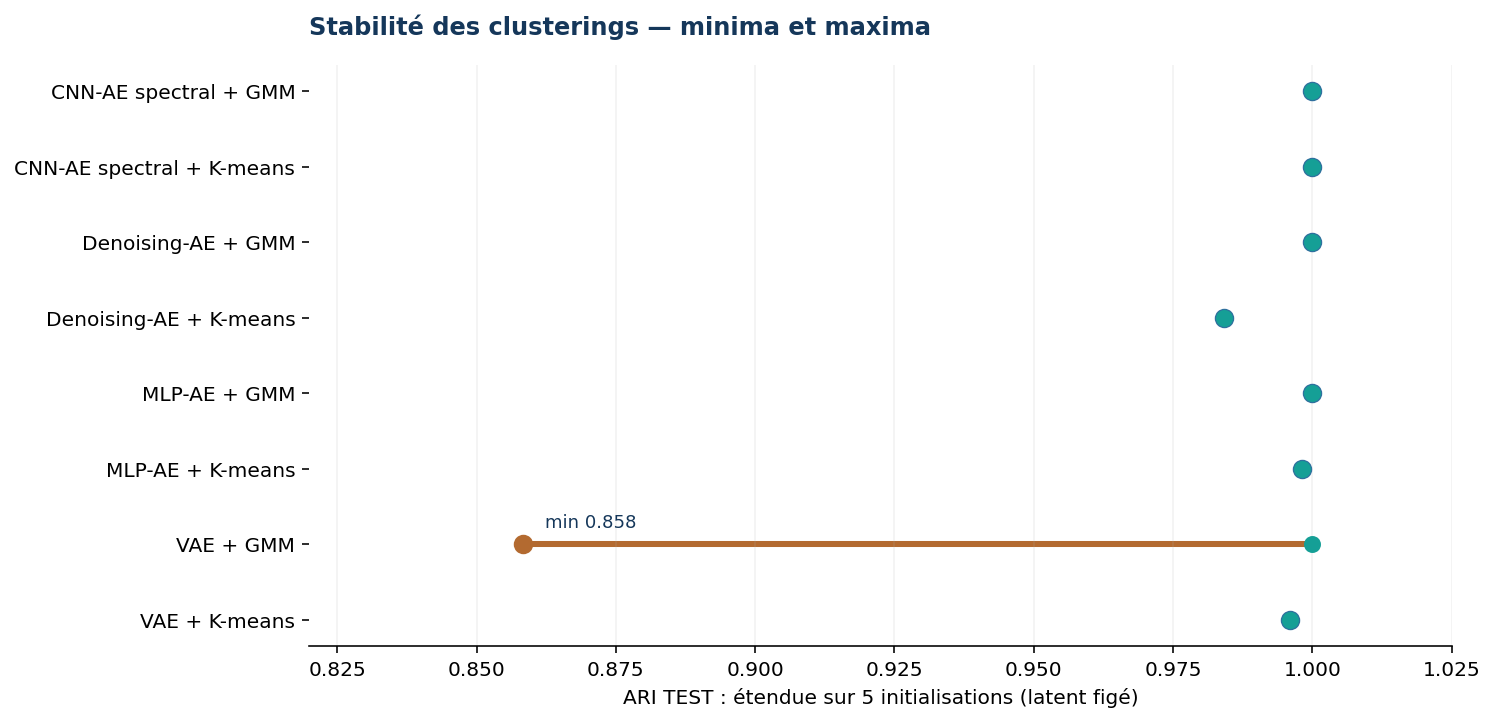

In [45]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import re
NB_GRAINES = 5
GRAINES = [10,20,30,40,50][:NB_GRAINES]

def robustesse_graines(res, graine_liste):
    rows=[]
    for fam in ('MLP-AE','Denoising-AE','VAE','CNN-AE spectral'):
        d=res['scores']
        df=d[(d.strategie=='correction_vitesse')&(d.vitesse_modele=='toutes')&(d.famille==fam)]
        with np.load(res['source']/'latents'/f"correction_vitesse__{ {'MLP-AE':'mlp','Denoising-AE':'denoising','VAE':'vae','CNN-AE spectral':'cnn_spectral'}[fam]}__toutes.npz",allow_pickle=False) as inp:
            tr=np.asarray(inp['z_train'],dtype=np.float32)
            te=np.asarray(inp['z_test'],dtype=np.float32)
            ids=inp['idx_test']
        cls=(res['predictions'][(res['predictions'].strategie=='correction_vitesse')&
                                 (res['predictions'].famille==fam)&
                                 (res['predictions'].algorithme=='K-means')&
                                 (res['predictions'].vitesse_modele=='toutes')]
             .set_index('sample_id').loc[ids,'classe'].to_numpy())
        gmm_choix=str(df[df.algorithme=='GMM']['choix_parametre'].iloc[0])
        m=re.search(r'covariance=(full|tied|diag|spherical)',gmm_choix)
        if not m: raise ValueError('Type de covariance GMM absent pour '+fam)
        cov=m.group(1)
        for seed in graine_liste:
            for algo in ('K-means','GMM'):
                if algo=='K-means':
                    labels=KMeans(n_clusters=5,n_init=10,random_state=seed).fit(tr).predict(te)
                else:
                    labels=GaussianMixture(n_components=5,covariance_type=cov,
                                           reg_covar=1e-5,n_init=2,max_iter=250,
                                           random_state=seed).fit(tr).predict(te)
                rows.append(dict(famille=fam,algorithme=algo,graine=seed,
                                 ari=adjusted_rand_score(cls,labels),
                                 nmi=normalized_mutual_info_score(cls,labels)))
    return pd.DataFrame(rows)

robustesse_initialisations=robustesse_graines(res,GRAINES)
display(robustesse_initialisations.groupby(['famille','algorithme'])
        .agg(ari_moyen=('ari','mean'),ari_ecart_type=('ari','std'),
             ari_min=('ari','min'),ari_max=('ari','max'),nmi_moyen=('nmi','mean'))
        .round(4))
# Représentation lisible lorsque presque tous les boxplots sont confondus à ARI≈1.
_table = (robustesse_initialisations.groupby(['famille','algorithme'])
          .agg(ari_min=('ari','min'),ari_max=('ari','max')).reset_index()
          .sort_values(['famille','algorithme']).reset_index(drop=True))
_fig,_ax = plt.subplots(figsize=(10.4,5.1))
for _i,_row in _table.iterrows():
    _lo=float(_row.ari_min);_hi=float(_row.ari_max)
    _ax.plot([_lo,_hi],[_i,_i],color='#b36a30' if _hi-_lo>.01 else '#b6c8d4',lw=3,zorder=1)
    _ax.scatter(_lo,_i,s=75,color='#b36a30' if _hi-_lo>.01 else '#2f709e',zorder=2)
    _ax.scatter(_hi,_i,s=55,color='#159f96',zorder=2)
    if _hi-_lo>.01:_ax.text(_lo+.004,_i-.22,f'min {_lo:.3f}',fontsize=9,color='#15375a')
_ax.set_yticks(range(len(_table)),_table['famille']+' + '+_table['algorithme']);_ax.invert_yaxis()
_ax.set_xlim(.82,1.025);_ax.set_xlabel('ARI TEST : étendue sur 5 initialisations (latent figé)')
_ax.set_title('Stabilité des clusterings — minima et maxima',loc='left',fontweight='bold',color='#15375a',pad=15)
_ax.grid(axis='x',alpha=.16);_ax.spines[['top','right','left']].set_visible(False)
plt.tight_layout();plt.show()

**Interprétation de C4.** Avec cinq graines et des latents AE figés, **7 des 8 combinaisons** donnent un ARI identique pour toutes les graines (même s'il n'est pas toujours parfait). **VAE + GMM (covariance complète)** est l'exception : **0,8583 à 1,0000**. Cette figure rend visibles les bornes, mieux adaptées que des boxplots écrasés à 1, sans prétendre couvrir la variabilité du réentraînement des AE.

## C5. Sensibilité à une perturbation **dans l’espace latent**

Nous dégradons les vecteurs TEST *après* l’encodeur par un bruit gaussien proportionnel à l’écart-type des codes TRAIN, puis mesurons l’ARI avec des clusterings **ajustés une seule fois sur TRAIN propre**. Les niveaux de bruit sont fixés à l’avance (0, 0,05, 0,10 et 0,20).

**Interprétation stricte :** il s’agit d’une robustesse mathématique dans l’espace latent, **pas** d’un essai de bruit d’accéléromètre ni d’un diagnostic en situation industrielle. Une étude réelle demanderait de perturber les mesures brutes avant prétraitement et encodage.

**Résultat observé :** à 20 % de perturbation du latent, **CNN-AE + K-means** conserve **ARI = 1,0000** ; CNN-AE + GMM diagonal **0,9959** ; MLP-AE + K-means **0,9961** ; Denoising-AE + GMM diagonal **0,9502** ; VAE + GMM diagonal **0,3375**. Le **VAE + GMM diagonal ne part que de 0,5417 à bruit nul** : ne pas confondre cet essai avec le GMM à covariance **complète** retenu dans B, qui obtenait ARI = 1,0000. Ces perturbations sont artificielles **après encodage** ; elles n'attestent pas la robustesse à un bruit physique de capteur.

niveau_bruit                  0.00    0.05    0.10    0.20
famille         algorithme                                
CNN-AE spectral GMM-diag    1.0000  1.0000  1.0000  0.9959
                K-means     1.0000  1.0000  1.0000  1.0000
Denoising-AE    GMM-diag    0.9904  0.9886  0.9867  0.9502
                K-means     0.9842  0.9823  0.9804  0.9767
MLP-AE          GMM-diag    1.0000  1.0000  1.0000  0.9960
                K-means     0.9981  0.9981  0.9981  0.9961
VAE             GMM-diag    0.5417  0.4731  0.4069  0.3375
                K-means     0.9960  0.9980  0.9940  0.9880

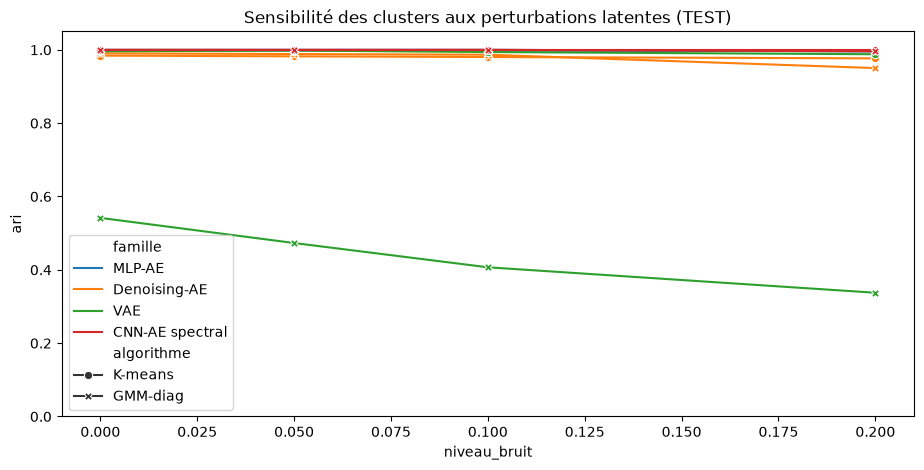

In [46]:
def robustesse_bruit_latent(res, niveaux=(0,.05,.10,.20), seed=2026):
    rng=np.random.default_rng(seed);records=[]
    for fam,slug in [('MLP-AE','mlp'),('Denoising-AE','denoising'),
                     ('VAE','vae'),('CNN-AE spectral','cnn_spectral')]:
        with np.load(res['source']/'latents'/f'correction_vitesse__{slug}__toutes.npz',allow_pickle=False) as d:
            ztr=d['z_train'];zte=d['z_test'];ids=d['idx_test']
        q=res['predictions'][(res['predictions'].strategie=='correction_vitesse')&
                             (res['predictions'].vitesse_modele=='toutes')&
                             (res['predictions'].famille==fam)&
                             (res['predictions'].algorithme=='K-means')]
        cls=q.set_index('sample_id').loc[ids,'classe'].to_numpy()
        models={'K-means':KMeans(n_clusters=5,n_init=10,random_state=42).fit(ztr),
                'GMM-diag':GaussianMixture(n_components=5,covariance_type='diag',
                    reg_covar=1e-5,random_state=42,n_init=2).fit(ztr)}
        std=np.maximum(np.std(ztr,axis=0),1e-6)
        for niveau in niveaux:
            rng_loc=np.random.default_rng(seed) # mêmes directions du bruit entre niveaux
            bruit=rng_loc.normal(size=zte.shape).astype(np.float32)*std
            zbruite=zte+niveau*bruit
            for name,model in models.items():
                labels=model.predict(zbruite)
                records.append(dict(famille=fam,algorithme=name,niveau_bruit=niveau,
                                    ari=adjusted_rand_score(cls,labels)))
    return pd.DataFrame(records)

sensibilite_latente=robustesse_bruit_latent(res)
display(sensibilite_latente.pivot_table(index=['famille','algorithme'],
                   columns='niveau_bruit',values='ari').round(4))
fig,ax=plt.subplots(figsize=(11,5))
sns.lineplot(data=sensibilite_latente,x='niveau_bruit',y='ari',
             hue='famille',style='algorithme',markers=True,dashes=False,ax=ax)
ax.set_title('Sensibilité des clusters aux perturbations latentes (TEST)')
ax.set_ylim(0,1.05);plt.show()

**Attention au comparatif C5.** Le GMM utilisé pour le bruit latent possède une **covariance diagonale**, tandis que celui optimisé en B utilise une covariance complète (`full`). Le score initial faible de VAE + GMM-diag (**ARI = 0,5417 au bruit nul**) est donc compatible avec le **ARI = 1** du VAE + GMM-full en B. La courbe verte dégradée traduit une sensibilité de **cette configuration précise** ; elle ne prouve ni l'échec général du VAE ni une vulnérabilité physique aux vibrations bruitées.

### C6. Conservation et provenance des évaluations C

Les tableaux numériques C sont exportés dans `results_v6_autonome/experiences_c/` avec l'empreinte SHA-256 de `bd_v1.pkl` et les versions de bibliothèques utilisées. Ils **n'écrasent aucun résultat historique V5**. Les valeurs et les graphiques intégrés au présent notebook sont lisibles sans cette arborescence ; pour une reproduction complète, il faut aussi les données `bd_v1.pkl` et les dépendances Python appropriées.

In [47]:
import json
import sklearn
from pathlib import Path
out_v6=RACINE_V6 / 'experiences_c'
out_v6.mkdir(exist_ok=True)
fichiers_v6={
    'audit.csv':audit,
    'distances_nearest_neighbor.csv':distances,
    'baselines_clustering.csv':baselines_v6,
    'baselines_detection.csv':detecteurs_simples,
    'comparaison_detection.csv':comparatif_detect,
    'test_vitesse_inconnue_loso.csv':loso_v6,
    'stabilite_initialisations.csv':robustesse_initialisations,
    'sensibilite_bruit_latent.csv':sensibilite_latente,
}
for nom,table in fichiers_v6.items():
    table.to_csv(out_v6/nom,index=False,encoding='utf-8')
meta_v6={
    'nature':'Exploratoire : split V4 sans preuve de séries indépendantes',
    'n_acquisitions':len(bd),
    'cache_sha256':hashlib.sha256(Path('bd_v1.pkl').read_bytes()).hexdigest(),
    'python_numpy':np.__version__,
    'pandas':pd.__version__,
    'sklearn':sklearn.__version__,
    'graines_kmeans_gmm':GRAINES,
    'test_vitesse_inconnue':'Baselines PCA uniquement, sans autoencodeur et sans normalisation par la vitesse exclue',
    'bruit_latent':'Ne constitue pas un bruit de capteur physique',
    'attention':'Les labels TEST sont employés pour les métriques seulement; après résultats V5 déjà observés.'
}
(out_v6/'protocole_v6_exploratoire.json').write_text(
    json.dumps(meta_v6,indent=2,ensure_ascii=False),encoding='utf-8')
print('8 tableaux et le protocole scientifique V6 enregistrés dans',out_v6)

8 tableaux et le protocole scientifique V6 enregistrés dans results_v6_autonome\experiences_c


---
# Étude D — DEC et IDEC : réinvestir la littérature scientifique

### D1. Pourquoi ces deux méthodes ?

Nous avons jusqu’ici réalisé **autoencodeur → espace latent figé → K-means/GMM/BIRCH**. Dans [DEC, Xie et al., ICML 2016](https://proceedings.mlr.press/v48/xieb16.html), l’encodeur et les centres de clusters sont affinés ensemble en minimisant une divergence KL vers une distribution cible auto-calculée. [IDEC, Guo et al., IJCAI 2017](https://www.ijcai.org/proceedings/2017/243) y ajoute une perte de reconstruction afin de préserver davantage la structure locale.

**Question expérimentale :** IDEC améliore-t-il la qualité du clustering sur les **mêmes 26 descripteurs corrigés de la vitesse**, par rapport à un AE dense + K-means ?

Cette partie utilise **un nouvel encodeur dense** entraîné sur les 26 descripteurs, et non les poids du CNN de l’étude A. L’essai comporte 3 méthodes avec **même préentraînement et même initialisation des clusters**, pour isoler la contribution de l’objectif de clustering. Aucun label réel n’intervient dans l’optimisation ou le choix des paramètres ; le TEST est réservé à l’évaluation.

**Par défaut, cette expérience est désactivée** pour éviter des entraînements involontaires lors de l’ouverture du notebook. Passer `EXECUTER_DEC_IDEC=True` et exécuter les cellules de code de la partie D pour la réaliser, puis sauvegarder le notebook. Les scores de cette section ne sont pas préremplis.

In [48]:
import copy
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader

EXECUTER_DEC_IDEC = False  # Activer explicitement pour entraîner ces nouveaux modèles.
EPOCHS_PRETRAIN = 30
EPOCHS_DEEP = 30
BATCH_SIZE_DEEP = 128
GAMMA_IDEC = 0.1
SEED_DEEP = 42

class ModeleDEC(nn.Module):
    def __init__(self, input_dim=26, latent_dim=6, k=5):
        super().__init__()
        self.encodeur=nn.Sequential(nn.Linear(input_dim,16),nn.Tanh(),
                                   nn.Linear(16,latent_dim))
        self.decodeur=nn.Sequential(nn.Linear(latent_dim,16),nn.Tanh(),
                                   nn.Linear(16,input_dim))
        self.centres=nn.Parameter(torch.zeros(k,latent_dim))
    def forward(self,x):
        z=self.encodeur(x)
        xrec=self.decodeur(z)
        distance=((z[:,None,:]-self.centres[None,:,:])**2).sum(dim=2)
        q=(1.+distance).pow(-1)  # Student t, alpha=1
        q=q/q.sum(dim=1,keepdim=True)
        return z,xrec,q

def distribution_cible(q):
    poids=q*q/torch.clamp(q.sum(dim=0,keepdim=True),min=1e-12)
    return (poids/torch.clamp(poids.sum(dim=1,keepdim=True),min=1e-12)).detach()

def pretrain_modele(x_train,epochs=30,batch_size=128,seed=42):
    torch.manual_seed(seed)
    mod=ModeleDEC(input_dim=x_train.shape[1])
    train_tensor=torch.tensor(x_train,dtype=torch.float32)
    loader=DataLoader(TensorDataset(train_tensor),batch_size=batch_size,
                      shuffle=True,generator=torch.Generator().manual_seed(seed))
    opt=torch.optim.Adam(list(mod.encodeur.parameters())+list(mod.decodeur.parameters()),lr=1e-3)
    losses=[]
    for epoch in range(epochs):
        mod.train();loss_sum=0.
        for (xb,) in loader:
            _,rec,_=mod(xb)
            loss=F.mse_loss(rec,xb)
            opt.zero_grad();loss.backward();opt.step()
            loss_sum+=float(loss.item())*len(xb)
        losses.append(dict(etape='préentraînement AE',epoch=epoch+1,
                           reconstruction=loss_sum/len(x_train),kl=0.))
    return mod,losses

def entrainer_deep(init_model,x_train,methode,epochs=30,batch_size=128,seed=42,gamma=.1):
    assert methode in ('DEC','IDEC')
    torch.manual_seed(seed)
    model=copy.deepcopy(init_model)
    tensor=torch.tensor(x_train,dtype=torch.float32)
    # Initialisation identique : centres K-means calculés sur les codes TRAIN.
    model.eval()
    with torch.no_grad(): codes=model.encodeur(tensor).numpy()
    km=KMeans(n_clusters=5,n_init=10,random_state=seed).fit(codes)
    with torch.no_grad(): model.centres.copy_(torch.tensor(km.cluster_centers_))
    params=list(model.encodeur.parameters())+[model.centres]
    if methode=='IDEC': params+=list(model.decodeur.parameters())
    opt=torch.optim.Adam(params,lr=1e-3)
    history=[]
    for epoch in range(epochs):
        model.eval()
        with torch.no_grad(): _,_,qtrain=model(tensor)
        p_train=distribution_cible(qtrain)
        model.train();loss_rec=0.;loss_kl=0.
        order=torch.randperm(len(tensor),generator=torch.Generator().manual_seed(seed+epoch))
        for indices in order.split(batch_size):
            xb=tensor[indices];pb=p_train[indices]
            _,recon,q=model(xb)
            kl=F.kl_div(torch.clamp(q,min=1e-10).log(),pb,reduction='batchmean')
            recon_loss=F.mse_loss(recon,xb)
            loss=kl+(gamma*recon_loss if methode=='IDEC' else 0.)
            opt.zero_grad();loss.backward();opt.step()
            loss_kl+=float(kl.item())*len(indices)
            loss_rec+=float(recon_loss.item())*len(indices)
        history.append(dict(etape=methode,epoch=epoch+1,
                            reconstruction=loss_rec/len(tensor),kl=loss_kl/len(tensor)))
    return model,history,km

def evaluer_deep(model,x_test,classe_test,method):
    with torch.no_grad():
        z,_,q=model(torch.tensor(x_test,dtype=torch.float32))
        labels=q.argmax(1).cpu().numpy()
    return dict(methode=method,
                ari=adjusted_rand_score(classe_test,labels),
                nmi=normalized_mutual_info_score(classe_test,labels))

print('Protocole DEC/IDEC disponible ; entraînement activé :',EXECUTER_DEC_IDEC)

Protocole DEC/IDEC disponible ; entraînement activé : False


### D2. Expérience contrôlée : AE seul, DEC, IDEC

- Prétraitement **log10 + standardisation par vitesse**, ajusté sur TRAIN seulement, comme pour les AE denses de l’étude A.
- Préentraînement AE sur toutes les acquisitions TRAIN, sans étiquettes.
- Initialisation des centres K-means à partir de l’encodeur préentraîné, identique pour DEC et IDEC.
- Raffinement DEC par **KL** ; raffinement IDEC par **KL + 0,1 × MSE**.
- Les étiquettes du TEST ne servent qu’au calcul final de ARI/NMI.

Il s’agit d’une **adaptation pédagogique de DEC/IDEC** (une seule graine, paramètres fixes, architecture compacte), et non d’une reproduction intégrale des expériences publiées. Les vitesses de TEST appartiennent aux régimes déjà vus. Les métriques restent exploratoires.

In [49]:
if EXECUTER_DEC_IDEC:
    x_deep,_=preparer(bd,X_DESC,features,'correction_vitesse',TRAIN)
    train_x=x_deep[TRAIN];test_x=x_deep[TEST];test_y=Y_CLASSE[TEST]
    init,trace_pre=pretrain_modele(train_x,EPOCHS_PRETRAIN,BATCH_SIZE_DEEP,SEED_DEEP)
    with torch.no_grad():zt=init.encodeur(torch.tensor(train_x)).numpy()
    km_init=KMeans(n_clusters=5,n_init=10,random_state=SEED_DEEP).fit(zt)
    with torch.no_grad():ztest=init.encodeur(torch.tensor(test_x)).numpy()
    scores_deep=[dict(methode='AE dense initial + K-means',
                      ari=adjusted_rand_score(test_y,km_init.predict(ztest)),
                      nmi=normalized_mutual_info_score(test_y,km_init.predict(ztest)))]
    traces=trace_pre.copy();modeles_deep={}
    for meth in ('DEC','IDEC'):
        modele,hist,_=entrainer_deep(init,train_x,meth,EPOCHS_DEEP,
                                     BATCH_SIZE_DEEP,SEED_DEEP,GAMMA_IDEC)
        modeles_deep[meth]=modele
        traces.extend(hist)
        scores_deep.append(evaluer_deep(modele,test_x,test_y,meth))
    scores_deep=pd.DataFrame(scores_deep)
    traces_deep=pd.DataFrame(traces)
    display(scores_deep.round(5))
    fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    sns.barplot(data=scores_deep,x='methode',y='ari',ax=axes[0],color='#457b9d')
    axes[0].set_ylim(0,1.05);axes[0].set_title('DEC/IDEC — ARI TEST (une graine)')
    sns.lineplot(data=traces_deep.query("etape!='préentraînement AE'"),
                 x='epoch',y='kl',hue='etape',ax=axes[1]);axes[1].set_title('KL train')
    plt.show()
    from pathlib import Path
    v6_dir=RACINE_V6 / 'experiences_c';v6_dir.mkdir(exist_ok=True)
    scores_deep.to_csv(v6_dir/'dec_idec_scores_exploratoires.csv',index=False)
    traces_deep.to_csv(v6_dir/'dec_idec_courbes.csv',index=False)
    for meth,mod in modeles_deep.items():
        torch.save({'state_dict':mod.state_dict(),'methode':meth,'seed':SEED_DEEP,
                    'gamma':GAMMA_IDEC},v6_dir/f'{meth.lower()}_v6.pt')
    print('DEC/IDEC terminés ; modèles et métriques enregistrés dans',v6_dir)
else:
    print('DEC/IDEC non exécutés : mettre EXECUTER_DEC_IDEC=True dans D1 pour lancer un nouvel entraînement.')

DEC/IDEC non exécutés : mettre EXECUTER_DEC_IDEC=True dans D1 pour lancer un nouvel entraînement.


---
# Synthèse générale — résultats, sélection provisoire et limites

## S1. Résultats majeurs, directement issus des expériences exécutées

| Question scientifique | Observation sur le TEST actuel | Interprétation justifiée |
|---|---|---|
| Les AE détectent-ils les défauts ? | **AUROC = 1** et **rappel = 1** pour les 4 AE ; **3 à 8** fausses alarmes selon le modèle | Excellent résultat dans les conditions testées ; le réglage du seuil et le risque de dépendance restent à considérer |
| Quel est l'effet de la vitesse ? | K-means sur latents : **ARI 0,4911–0,6296** sans correction, **0,9842–1,0000** après correction | **La correction de vitesse est un facteur majeur sur les vitesses connues** |
| Quel AE est le plus convaincant pour le clustering ? | **CNN-AE spectral + K-means : ARI = 1,0000 ; silhouette TRAIN ≈ 0,7970** après correction | Candidat fort, mais reçoit **512 coefficients spectraux**, pas les mêmes 26 descripteurs que les AE denses |
| Le choix de l'algorithme a-t-il un effet ? | **GMM covariance full : ARI = 1** avec chacun des 4 AE corrigés ; BIRCH varie **0,3766–1** | GMM régulier sur cette partition ; **BIRCH fragile** avec certains espaces latents |
| L'autoencodeur est-il nécessaire ? | **GMM diagonal sur les 26 descripteurs corrigés : ARI = 1** ; K-means spectral direct corrigé : **ARI = 1** | **Non démontré** : des références classiques atteignent les mêmes scores sans AE |
| Que devient le modèle à vitesse inconnue ? | Références classiques PCA6 : **ARI 0,1963–0,7769** selon vitesse exclue | Généralisation inter-régimes **insuffisamment établie** ; AE **non testés** par cette expérience |
| Les résultats sont-ils stables ? | CNN-AE + K-means : ARI = 1 sur 5 initialisations et sous perturbation latente de 20 % ; VAE + GMM : min ARI **0,8583** sur 5 graines | Encourageant pour CNN-AE + K-means **sur latents figés** ; pas une validation de stabilité inter-entraînements |
| Les acquisitions TEST sont-elles indépendantes ? | Aucun doublon exact ; **pas de `group_id` physique** | La validation indépendante du banc reste **à démontrer** |

## S2. Choix défendable pour la suite — plusieurs objectifs, plusieurs candidats

**1. Clustering avec apprentissage profond : CNN-AE spectral + K-means.** Il combine ARI/NMI parfaits, silhouette train élevée et stabilité sur les tests C4/C5 disponibles. **Réserve :** spectres riches, coût du CNN, absence de comparaison d'architectures à entrée strictement identique, absence de test inter-régimes inconnu.

**2. Baseline pratique à coût a priori plus faible : 26 descripteurs corrigés + GMM diagonal.** Son ARI = 1 sur ce split constitue un contre-exemple direct à la nécessité de l'AE. Le coût global et la robustesse d'un futur déploiement restent à mesurer.

**3. Détection SAFE/défaut : PCA par reconstruction et MLP-AE/Denoising-AE comme premiers candidats à départager.** Tous ont AUROC = 1, rappel = 1, **3 fausses alarmes** sur le test. Il faudra comparer temps de calcul, calibration, taux de fausses alarmes sur validation externe et évolution des données.

**4. GMM sur latents AE : alternative performante**, mais la variabilité constatée pour VAE + GMM et les différences de covariance selon expériences imposent de préciser les paramètres au lieu de parler de « GMM » comme d'un algorithme unique.

**Ce rapport ne désigne pas de « gagnant industriel » définitif.** Les valeurs maximales du TEST sont partagées par plusieurs solutions ; le choix final nécessite des preuves hors du banc/split actuellement utilisé.

## S3. Conditions de validation avant toute généralisation

1. **Identifier des groupes physiques d'acquisitions** (roulement, session, campagne, machine) et constituer des groupes strictement disjoints entre TRAIN, VALIDATION et TEST ; documenter les métadonnées.
2. **Évaluer une vitesse entièrement inconnue** avec un prétraitement applicable sans statistiques de la vitesse test. Refaire le protocole pour les modèles AE et les références classiques, à entrées et métriques comparables.
3. **Recommencer plusieurs entraînements AE complets**, pas seulement plusieurs initialisations K-means/GMM ; produire moyenne, dispersion, intervalles et coûts de calcul.
4. **Évaluer l'effet du bruit sur le signal physique**, avant extraction des caractéristiques et encodage, plutôt que seulement sur les latents.
5. **Comparer les entrées à information identique** pour distinguer l'intérêt de l'architecture CNN de celui du spectre ; mesurer l'inférence et les ressources mémoire.
6. **Clarifier le sens industriel du diagnostic :** détecter un défaut versus attribuer une classe à un cluster. Un regroupement non supervisé n'associe pas automatiquement ses numéros à des états de roulement.

## S4. Expérience non réalisée

DEC/IDEC (étude D) reste **désactivée**. Aucun score DEC/IDEC n'est donc cité, comparé ou anticipé dans les conclusions.

*Statut du choix :* **sélection méthodologique exploratoire**, fondée sur les résultats exécutés archivés ; à revalider sur un protocole indépendant avant toute revendication de généralisation.

## Cadre scientifique et bibliographie commentée

**Références méthodologiques vérifiées :**

1. **Xie, J., Girshick, R., Farhadi, A. (2016)** — *Unsupervised Deep Embedding for Clustering Analysis*, ICML, PMLR 48, pp. 478–487. [Article](https://proceedings.mlr.press/v48/xieb16.html). Base conceptuelle de **DEC** : apprentissage conjoint des codes et des clusters.
2. **Guo, X., Gao, L., Liu, X., Yin, J. (2017)** — *Improved Deep Embedded Clustering with Local Structure Preservation*, IJCAI, pp. 1753–1759. [Article / DOI](https://doi.org/10.24963/ijcai.2017/243). Base conceptuelle de **IDEC** : objectif de clustering associé à la reconstruction.
3. **Malhotra, P., et al. (2016)** — *LSTM-based Encoder-Decoder for Multi-sensor Anomaly Detection*. [Prépublication](https://arxiv.org/abs/1607.00148). Justifie l’approche de détection par reconstruction **de séries temporelles** ; nous ne reproduisons pas son LSTM, puisque le jeu de données exploité ne contient pas les signaux temporels nécessaires.
4. **Pang, G., Shen, C., Cao, L., van den Hengel, A. (2021)** — *Deep Learning for Anomaly Detection: A Review*, ACM Computing Surveys, DOI [10.1145/3439950](https://doi.org/10.1145/3439950). Sert au cadrage des détecteurs et limites de leur évaluation, pas à déclarer un algorithme gagnant.
5. **Boulenger, A. & Pachaud, C. (2009)** — *Aide-mémoire : Surveillance des machines par analyse des vibrations*, Dunod, ISBN 978-2-10-054190-4. Support métier remis dans le projet ; notamment analyse spectrale, enveloppe et défauts de roulements. Ses recommandations nécessitent les mesures et paramètres physiques avant une validation fréquentielle approfondie.

**Traçabilité de la littérature vers les expériences :**

| Hypothèse motivée par la littérature | Expérience correspondante | Limite de notre réalisation |
|---|---|---|
| Erreur de reconstruction utile pour la détection | Partie A + C3 | Pas d’apprentissage temporel LSTM ; anomalie binaire SAFE/défaut |
| Une représentation latente peut aider le clustering | Partie A/B et C2 | Baseline spectrale directe déjà parfaite sur le test V4 |
| Les distributions des clusters peuvent être non sphériques | GMM en partie B | K connu = cinq états ; covariance optimisée par BIC train |
| Ajuster l’encodeur pour améliorer les regroupements | DEC en partie D | Implémentation exploratoire, entraînement optionnel |
| Préserver la reconstruction pendant l’optimisation | IDEC en partie D | Hyperparamètres fixes ; validation externe nécessaire |
| Les vibrations dépendent du régime mécanique | A/B correction de vitesse et C3 bis | Trois vitesses connues, pas de test indépendant de régime |

**Distinction importante :** la bibliographie justifie des hypothèses et des choix de méthodes ; elle **ne prouve pas** l’efficacité de ces choix sur nos acquisitions. Seule une évaluation rigoureuse sur notre domaine peut le faire.

## Reproductibilité, transmission aux collaborateurs et précautions

### Lecture simple du livrable

- Le **fichier `.ipynb` suffit pour lire** les cellules de code, les analyses, les tableaux et les figures enregistrées. Les collaborateurs peuvent l'ouvrir dans JupyterLab, VS Code, Antigravity ou un lecteur compatible sans lancer d'entraînement.
- **Pour reproduire les calculs :** fournir de façon autorisée `bd_v1.pkl` (ou une copie issue d'une source de confiance), les bibliothèques Python du projet et le présent notebook. Le notebook intègre le code des modules A/B et **n'a pas besoin des anciennes versions V4/V5, ni des dossiers `results_v5_*`**.
- Première exécution **`Run All` : A réentraîne les 24 configurations AE ; B exécute les 60 évaluations de clustering ; C exécute les références et audits**. Les nouvelles sorties sont placées sous `results_v6_autonome/`. Les exécutions suivantes peuvent réutiliser ces résultats sous contrôle de cohérence avec le cache. **DEC/IDEC reste désactivé**.
- **Ne pas lancer `Run All` simplement pour lire le rapport** : les tableaux et graphiques sont déjà archivés. Les graphiques complémentaires de la présente révision ont été reconstitués à partir des tableaux numériques de la V6 exécutée, sans réentraînement.

### Limites méthodologiques à rappeler

- L'absence de doublons exacts et la proximité des distances ne démontrent pas que les séries d'acquisition sont indépendantes : l'identification physique des groupes est manquante.
- Les régimes 10/15/20 ont été utilisés pendant l'entraînement A/B. Les seuls essais à vitesse totalement tenue à l'écart concernent ici les **références classiques PCA6**, pas les autoencodeurs.
- Les données de test ont déjà été examinées dans les itérations antérieures : tout choix issu de ces résultats exige une vérification sur un **nouveau test indépendant**.
- Le CNN-AE spectral et les AE denses utilisent des représentations différentes. Les coûts d'inférence, la mémoire et les temps d'apprentissage complets doivent être documentés avant un choix applicatif.
- Le nombre de groupes K=5 est une connaissance préalable ; les clusters obtenus ne sont pas automatiquement étiquetés en catégories de défaut.

### Conservation et sécurité

Conserver ensemble : le présent fichier exécuté, le protocole de provenance des données, et les traces numériques si une reproduction exacte est exigée. Les fichiers `.pkl` et `.joblib` peuvent exécuter du code au chargement : **n'ouvrir que des sources fiables**. Partager les données uniquement si leurs conditions de diffusion le permettent.

**Révision éditoriale V6 :** adaptation des titres, consignes, commentaires, graphiques de synthèse et conclusion **sans réentraînement** ; chiffres repris des sorties de la V6 source ; autres expériences laissées intactes.